In [1]:

import pandas as pd
import tkinter as tk
from tkinter import filedialog
from pathlib import Path
from datetime import datetime
import pyarrow as pa
import pyarrow.parquet as pq

# ============================================================
# 1. DEFINIR A COLUNA DE RESPOSTAS
# ============================================================

COLUNA = (
    "B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você "
    "sentiu vontade de se machucar de propósito?"
)

# ============================================================
# 2. SELECIONAR O ARQUIVO PELO FINDER
# ============================================================

root = tk.Tk()
root.withdraw()

arquivo = filedialog.askopenfilename(
    title="Selecione a base de dados PeNSE",
    filetypes=[
        ("Arquivos Parquet", "*.parquet")
    ]
)

root.destroy()

if not arquivo:
    raise SystemExit("Nenhum arquivo foi selecionado.")

caminho = Path(arquivo)

# ============================================================
# 3. ABRIR O ARQUIVO PARQUET
# ============================================================

parquet = pq.ParquetFile(caminho)

if COLUNA not in parquet.schema_arrow.names:
    candidatas = [
        c for c in parquet.schema_arrow.names
        if "B12009" in c
    ]

    print("Colunas encontradas com B12009:", candidatas)
    raise ValueError(
        "A coluna B12009 não foi encontrada com o nome esperado."
    )

# ============================================================
# 4. DEFINIR PASTA, DATA E HORA DOS ARQUIVOS DE SAÍDA
# ============================================================

# Pasta de trabalho atual do Jupyter
pasta_saida = Path.cwd()

# Data: dia, mês abreviado em inglês
# Hora: formato de 24 horas
agora = datetime.now()
data_hora = agora.strftime("%d_%b_%H_%M_%S").lower()

saida_sim = pasta_saida / (
    f"02_PENSE2024_IDADE_13_A_17_SIM_{data_hora}.parquet"
)

saida_nao = pasta_saida / (
    f"02_PENSE2024_IDADE_13_A_17_NAO_{data_hora}.parquet"
)

# ============================================================
# 5. SEPARAR AS RESPOSTAS EM BLOCOS
# ============================================================

escritor_sim = None
escritor_nao = None

total_sim = 0
total_nao = 0
total_outros = 0

try:
    for bloco in parquet.iter_batches(batch_size=20_000):

        # Converter o bloco para DataFrame
        df_bloco = bloco.to_pandas()

        # Normalizar a representação das respostas
        respostas = (
            df_bloco[COLUNA]
            .astype("string")
            .str.strip()
        )

        # Código 3 = SIM
        # Código 1 = NÃO
        mascara_sim = respostas.isin(["3", "3.0"])
        mascara_nao = respostas.isin(["1", "1.0"])

        # Criar tabela Arrow com todas as colunas originais
        tabela = pa.Table.from_batches([bloco])

        # Inicializar os escritores no primeiro bloco
        if escritor_sim is None:
            escritor_sim = pq.ParquetWriter(
                str(saida_sim), tabela.schema
            )

            escritor_nao = pq.ParquetWriter(
                str(saida_nao), tabela.schema
            )

        # Gravar respostas SIM
        if mascara_sim.any():
            tabela_sim = tabela.filter(
                pa.array(mascara_sim.tolist())
            )
            escritor_sim.write_table(tabela_sim)
            total_sim += int(mascara_sim.sum())

        # Gravar respostas NÃO
        if mascara_nao.any():
            tabela_nao = tabela.filter(
                pa.array(mascara_nao.tolist())
            )
            escritor_nao.write_table(tabela_nao)
            total_nao += int(mascara_nao.sum())

        # Contabilizar outras respostas e ausências
        total_outros += int(
            (~mascara_sim & ~mascara_nao).sum()
        )

finally:
    if escritor_sim is not None:
        escritor_sim.close()

    if escritor_nao is not None:
        escritor_nao.close()

# ============================================================
# 6. MOSTRAR O RESUMO FINAL
# ============================================================

print("=" * 55)
print("SEPARAÇÃO CONCLUÍDA")
print("=" * 55)

print(f"Arquivo original: {caminho}")
print(f"Total de registros: {parquet.metadata.num_rows:,}")
print(f"Respondeu SIM (3): {total_sim:,}")
print(f"Respondeu NÃO (1): {total_nao:,}")
print(f"Outras respostas/ausências: {total_outros:,}")

print("\nArquivos gerados:")

print(f"\nSIM:\n{saida_sim}")
print(f"\nNÃO:\n{saida_nao}")

print("\nPasta de saída:")
print(pasta_saida)

SEPARAÇÃO CONCLUÍDA
Arquivo original: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/07_PENSE2024_IDADE_13_A_17.parquet
Total de registros: 118,041
Respondeu SIM (3): 38,561
Respondeu NÃO (1): 78,789
Outras respostas/ausências: 691

Arquivos gerados:

SIM:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/03_Divisao_base_dados_duas_intencao_sim_nao/02_PENSE2024_IDADE_13_A_17_SIM_18_oct_15_26_54.parquet

NÃO:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/03_Divisao_base_dados_duas_intencao_sim_nao/02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet

Pasta de saída:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/03_Divisao_base_dados_duas_intencao_sim_nao


Arquivo Excel carregado com sucesso!
Caminho: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/01_Colunas_recomendadas_pense_2024_final.xlsx
Número de regras carregadas: 41

Calculando estatísticas: 02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet

Calculando estatísticas: 02_PENSE2024_IDADE_13_A_17_SIM_18_oct_15_26_54.parquet

COMPARAÇÃO DAS ESTATÍSTICAS NUMÉRICAS


02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet  \
                                                                                                    count   
REGIAO - código de regiões                                                                    78789.0       
UF - código UF                                                                                78789.0       
CAPITAL - indica se é município da capital                                                    78789.0       
B01001A - Qual é o seu sexo?                                                                  78789.0       
IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS                                                  78789.0       
B01002 - Qual é a sua cor ou raça?                                                            78789.0       
B01006 - Você mora com sua mãe?                                                               78789.0       
B01007 - Você mora com seu pai?                                                               78789.0       
B01015B - Na sua casa tem computador ou notebook?                                             78789.0       
B01016 - Você tem acesso à internet em sua casa?                                              78789.0       
B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aul...                                            78789.0       
B03010C - Quantas horas por dia você costuma fi...                                            78789.0       
B05002A - Alguma vez na vida você tomou um copo...                                            78789.0       
B07002 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B07004 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B07005 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B07006 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B07007B - NOS ÚLTIMOS 30 DIAS, quantas vezes al...                                            78789.0       
B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes al...                                            78789.0       
B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes al...                                            78789.0       
B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu am...                                            78789.0       
B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, ...                                            78789.0       
B07016 - NOS ÚLTIMOS 30 DIAS, você ameaçou, ofe...                                            78789.0       
B12003 - Quantos(as) amigos(as) próximos você tem?                                            78789.0       
B12004 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B12007 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênci...                                            78789.0       
B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você ...                                            78789.0       
B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias v...                                            78789.0       
B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias v...                                            78789.0       
B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes v...                                            78789.0       
B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes ...                                            78789.0       
B09016A1 - Alguma vez na vida alguém o(a) tocou...                                            78789.0       
B09016A2 - Alguma 



####################################################################################################
INSPEÇÃO DA BASE: 02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet
####################################################################################################

[1] DIMENSÕES DA BASE
Número de linhas: 78,789
Número de colunas: 41
Total de células: 3,230,349
Memória utilizada: 27.73 MB

[2] DATAFRAME COMPLETO


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
0,1,11,0,1,2,4,3,1,3,3,...,1,1,1,1,1,3,1,1,3,1
1,1,11,0,1,2,1,3,1,1,3,...,1,3,3,1,1,1,3,4,0,0
2,1,11,0,2,2,2,3,3,3,3,...,1,1,1,1,1,1,3,4,0,0
3,1,11,0,2,2,4,3,3,3,3,...,1,1,1,1,1,1,3,4,0,0
4,1,11,0,1,2,4,3,1,1,3,...,1,1,1,1,1,1,3,4,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78784,5,53,1,1,2,4,3,3,3,3,...,1,1,1,3,1,3,3,4,0,0
78785,5,53,1,2,3,4,3,3,3,3,...,1,1,1,1,1,3,3,4,0,0
78786,5,53,1,1,2,4,3,3,1,3,...,1,1,1,1,1,3,3,4,0,0
78787,5,53,1,1,3,4,3,3,1,3,...,1,1,1,1,1,3,3,4,0,0



[3] PRIMEIRAS 5 LINHAS


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
0,1,11,0,1,2,4,3,1,3,3,...,1,1,1,1,1,3,1,1,3,1
1,1,11,0,1,2,1,3,1,1,3,...,1,3,3,1,1,1,3,4,0,0
2,1,11,0,2,2,2,3,3,3,3,...,1,1,1,1,1,1,3,4,0,0
3,1,11,0,2,2,4,3,3,3,3,...,1,1,1,1,1,1,3,4,0,0
4,1,11,0,1,2,4,3,1,1,3,...,1,1,1,1,1,1,3,4,0,0


... (12 outputs left out)

Total de células ausentes: 0

[10] VALORES ÚNICOS POR COLUNA


,valores_unicos,valores_unicos_incluindo_ausentes,percentual_unico
REGIAO - código de regiões,5,5,0.006
UF - código UF,27,27,0.034
CAPITAL - indica se é município da capital,2,2,0.003
B01001A - Qual é o seu sexo?,2,2,0.003
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",2,2,0.003
B01002 - Qual é a sua cor ou raça?,6,6,0.008
B01006 - Você mora com sua mãe?,3,3,0.004
B01007 - Você mora com seu pai?,3,3,0.004
B01015B - Na sua casa tem computador ou notebook?,3,3,0.004
B01016 - Você tem acesso à internet em sua casa?,3,3,0.004



[11] LINHAS DUPLICADAS
Linhas duplicadas: 161
Percentual de duplicatas: 0.204%

[12] COLUNAS CONSTANTES
['B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?']

[13] DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS

[14] DISTRIBUIÇÃO DAS VARIÁVEIS NUMÉRICAS

--------------------------------------------------------------------------------
Coluna: REGIAO - código de regiões

Tabela de frequências:


,frequencia,percentual
nordeste,26298,33.38
norte,18568,23.57
sudeste,14999,19.04
centro-oeste,9864,12.52
sul,9060,11.5


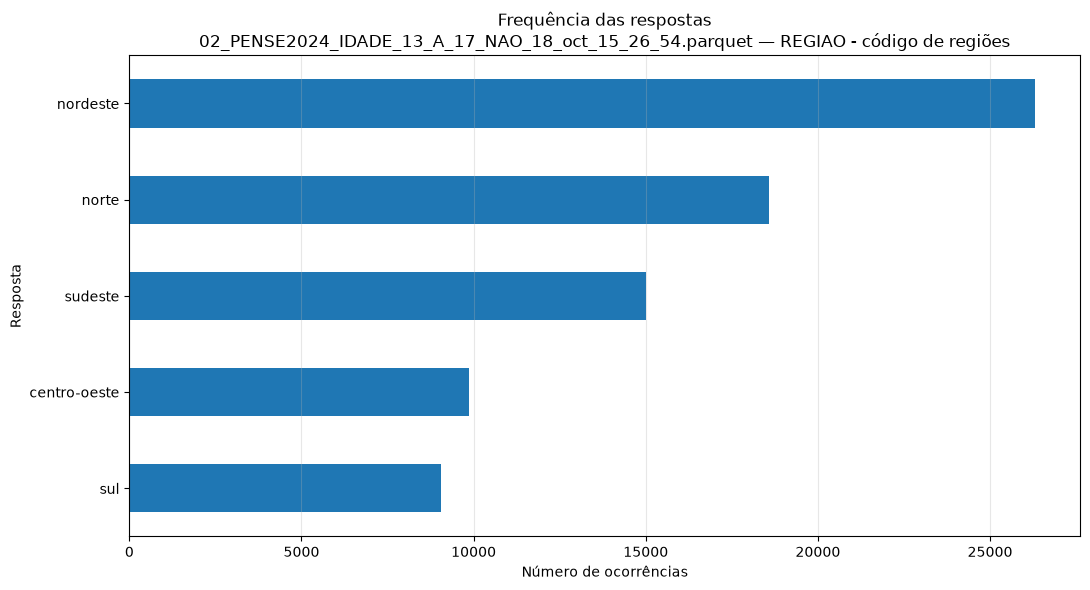


--------------------------------------------------------------------------------
Coluna: UF - código UF

Tabela de frequências:


,frequencia,percentual
Espírito Santo,4135,5.25
São Paulo,3900,4.95
Bahia,3638,4.62
Pernambuco,3598,4.57
Rio de Janeiro,3577,4.54
Minas Gerais,3387,4.3
Santa Catarina,3305,4.19
Rondônia,3236,4.11
Paraná,3193,4.05
Tocantins,3160,4.01


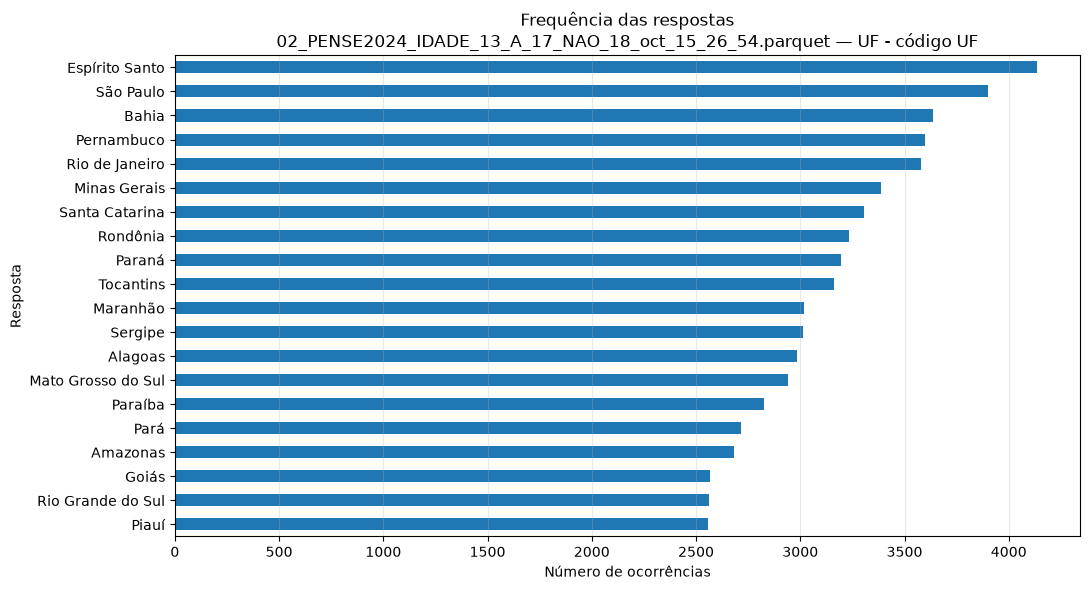


--------------------------------------------------------------------------------
Coluna: CAPITAL - indica se é município da capital

Tabela de frequências:


,frequencia,percentual
Capital,40284,51.13
Código não mapeado: 0,38505,48.87


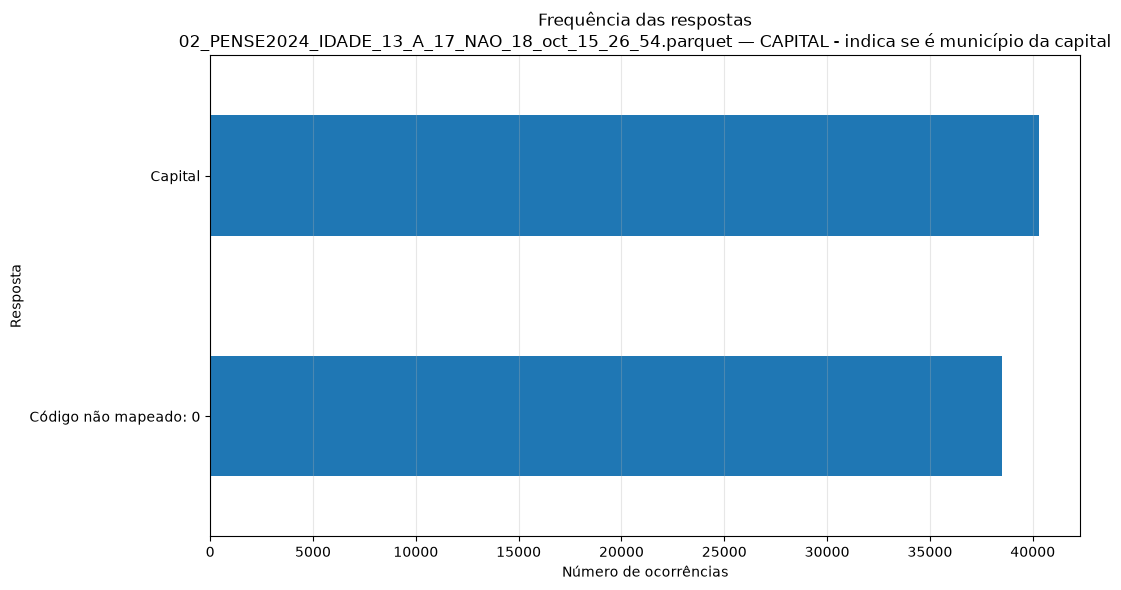


--------------------------------------------------------------------------------
Coluna: B01001A - Qual é o seu sexo?

Tabela de frequências:


,frequencia,percentual
Homem,45591,57.86
Mulher,33198,42.14


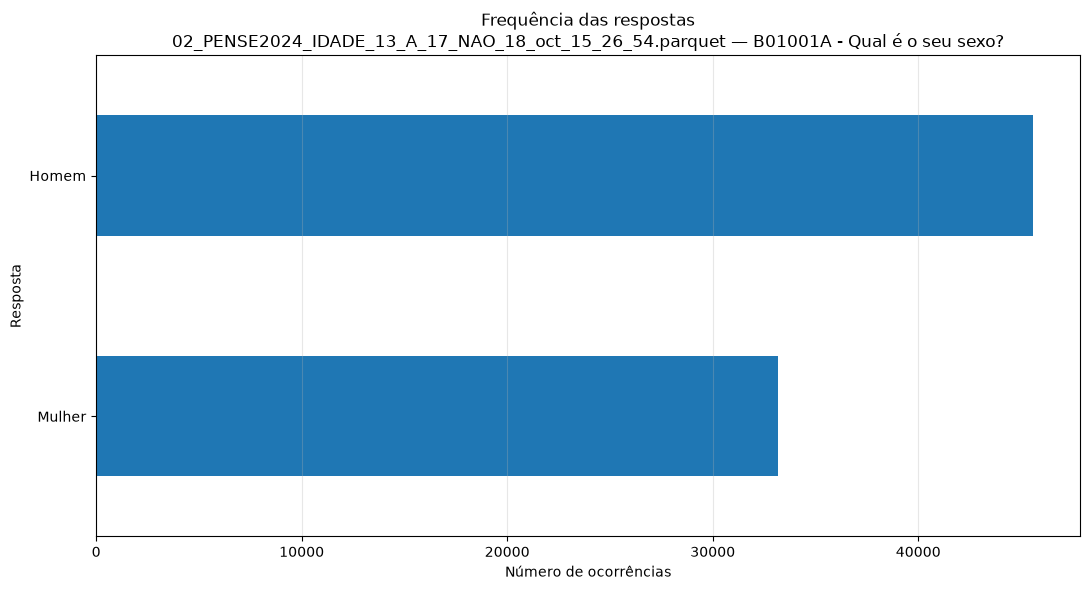


--------------------------------------------------------------------------------
Coluna: IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS

Tabela de frequências:


,frequencia,percentual
13 a 15 anos,50773,64.44
16 e 17 anos,28016,35.56


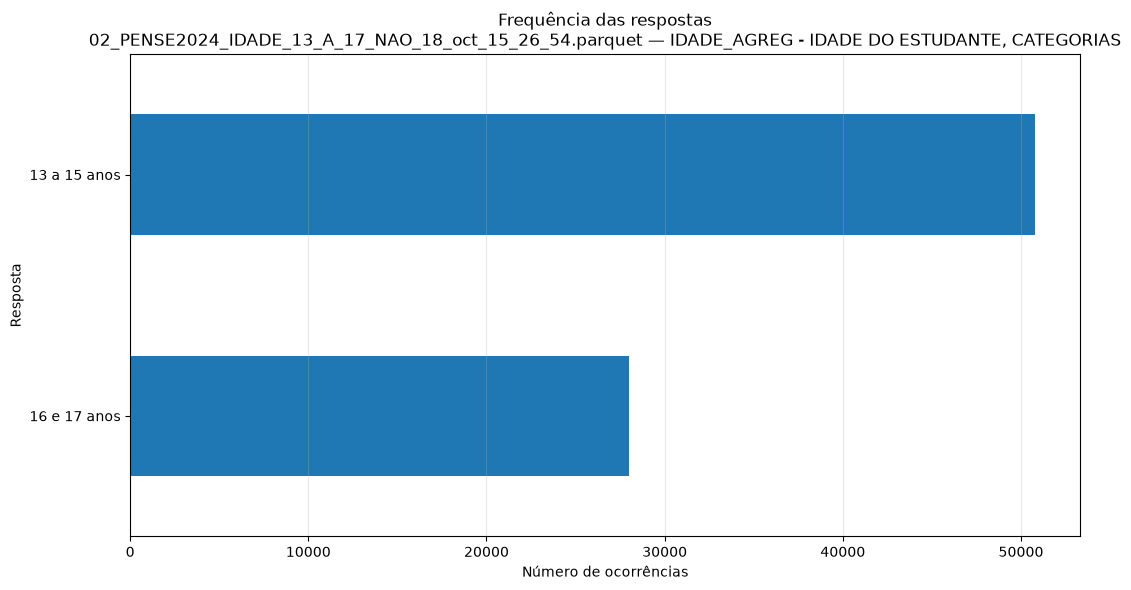


--------------------------------------------------------------------------------
Coluna: B01002 - Qual é a sua cor ou raça?

Tabela de frequências:


,frequencia,percentual
Parda,33708,42.78
Branca,32701,41.5
Preta,8459,10.74
Amarela,2009,2.55
Indígena,1596,2.03
Sem reposta,316,0.4


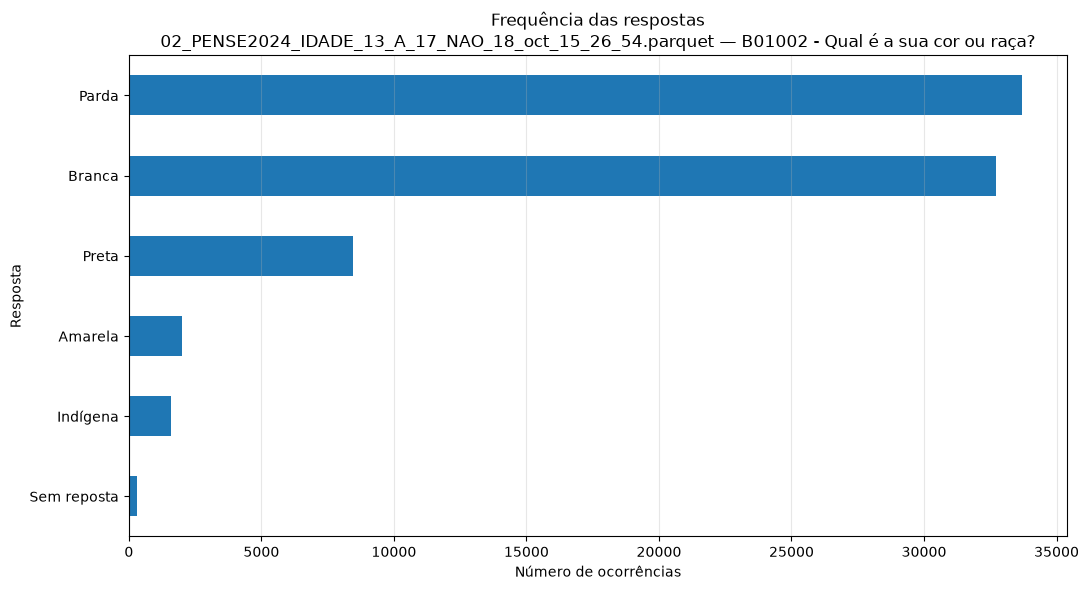


--------------------------------------------------------------------------------
Coluna: B01006 - Você mora com sua mãe?

Tabela de frequências:


,frequencia,percentual
Sim,71543,90.8
Nao,7229,9.18
Sem resposta,17,0.02


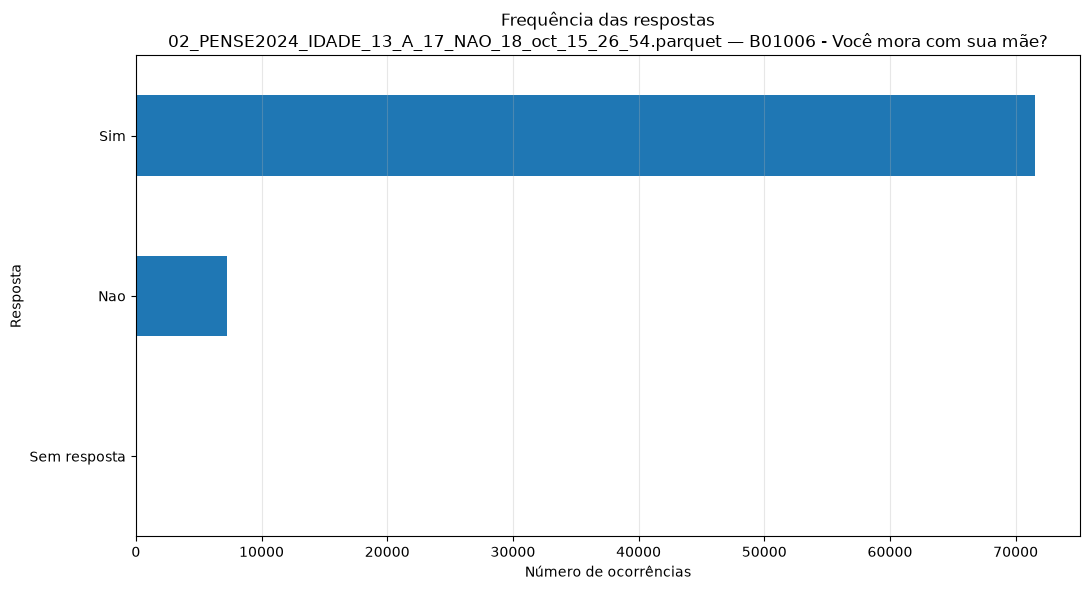


--------------------------------------------------------------------------------
Coluna: B01007 - Você mora com seu pai?

Tabela de frequências:


,frequencia,percentual
Sim,51674,65.59
Nao,27072,34.36
Sem resposta,43,0.05


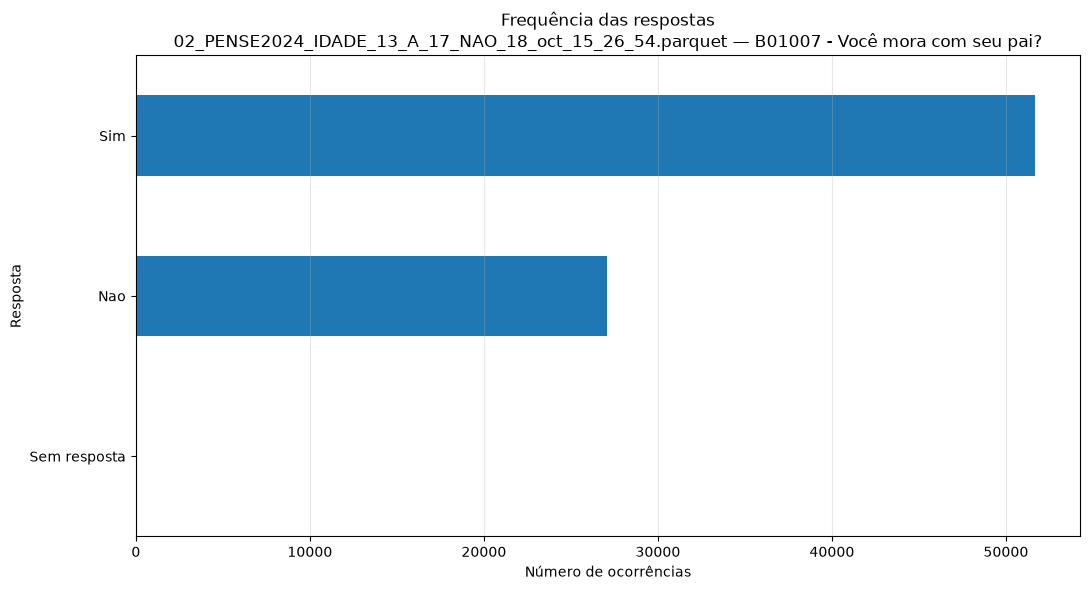


--------------------------------------------------------------------------------
Coluna: B01015B - Na sua casa tem computador ou notebook?

Tabela de frequências:


,frequencia,percentual
Sim,50776,64.45
Nao,27982,35.52
Sem resposta,31,0.04


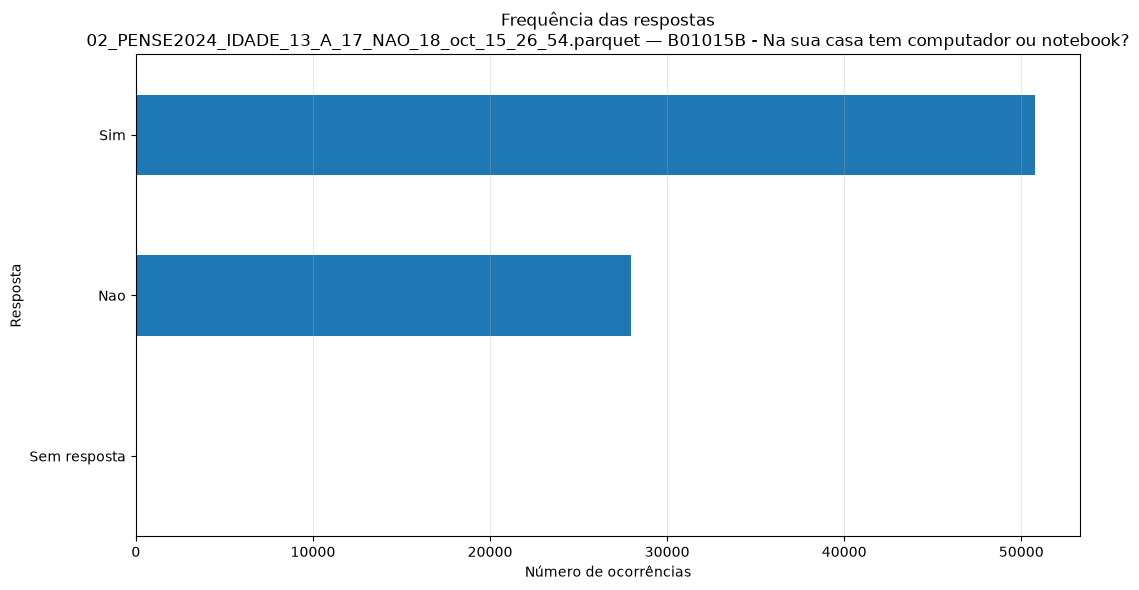


--------------------------------------------------------------------------------
Coluna: B01016 - Você tem acesso à internet em sua casa?

Tabela de frequências:


,frequencia,percentual
Sim,76899,97.6
Nao,1874,2.38
Sem resposta,16,0.02


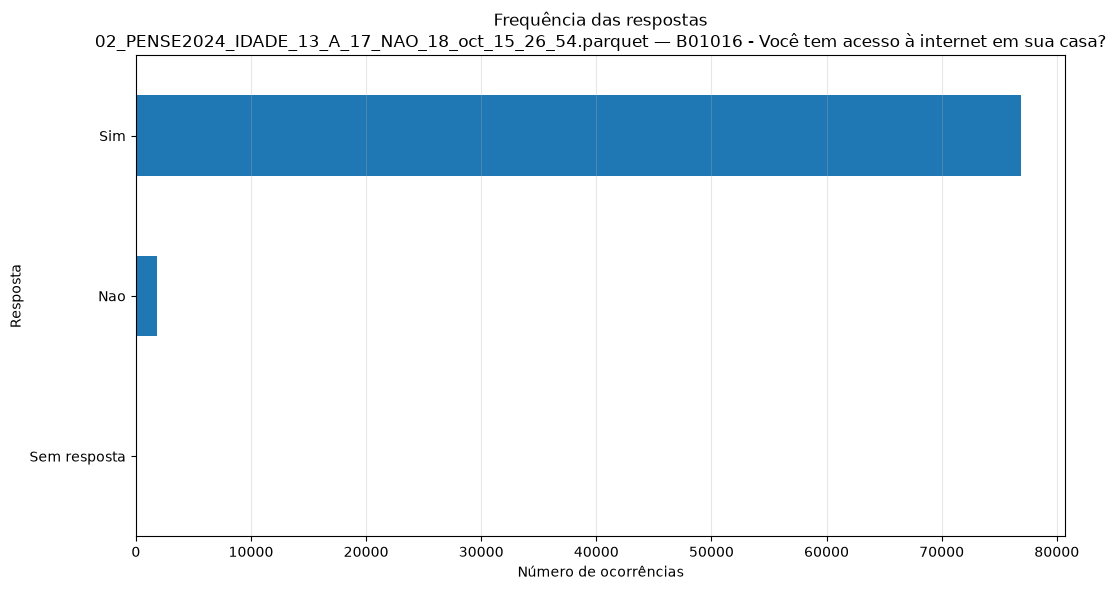


--------------------------------------------------------------------------------
Coluna: B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?

Tabela de frequências:


,frequencia,percentual
Um ou mais dias,57266,72.68
Nenhum dia,21392,27.15
Sem resposta,131,0.17


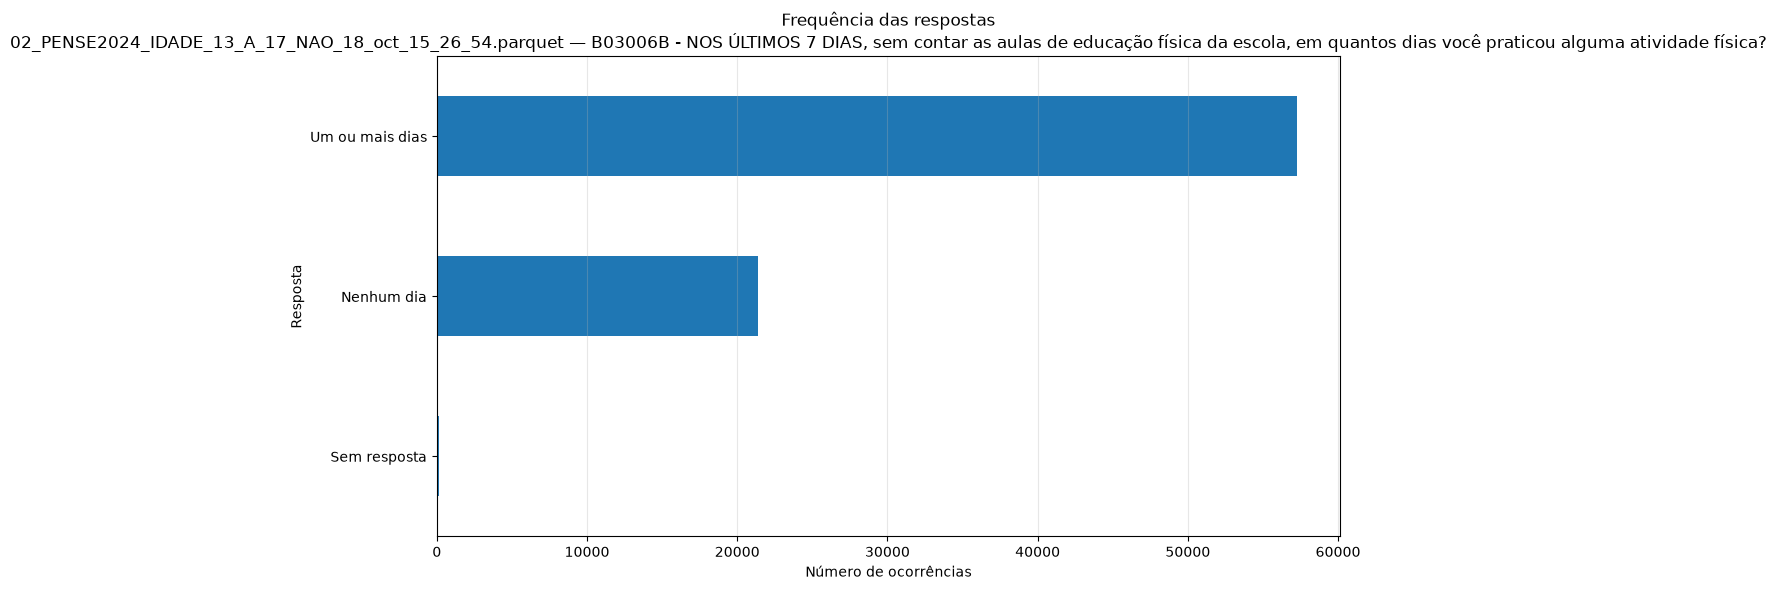


--------------------------------------------------------------------------------
Coluna: B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)

Tabela de frequências:


,frequencia,percentual
Um ou mais horas,59689,75.76
Nenhuma hora,11234,14.26
Sem resposta,7866,9.98


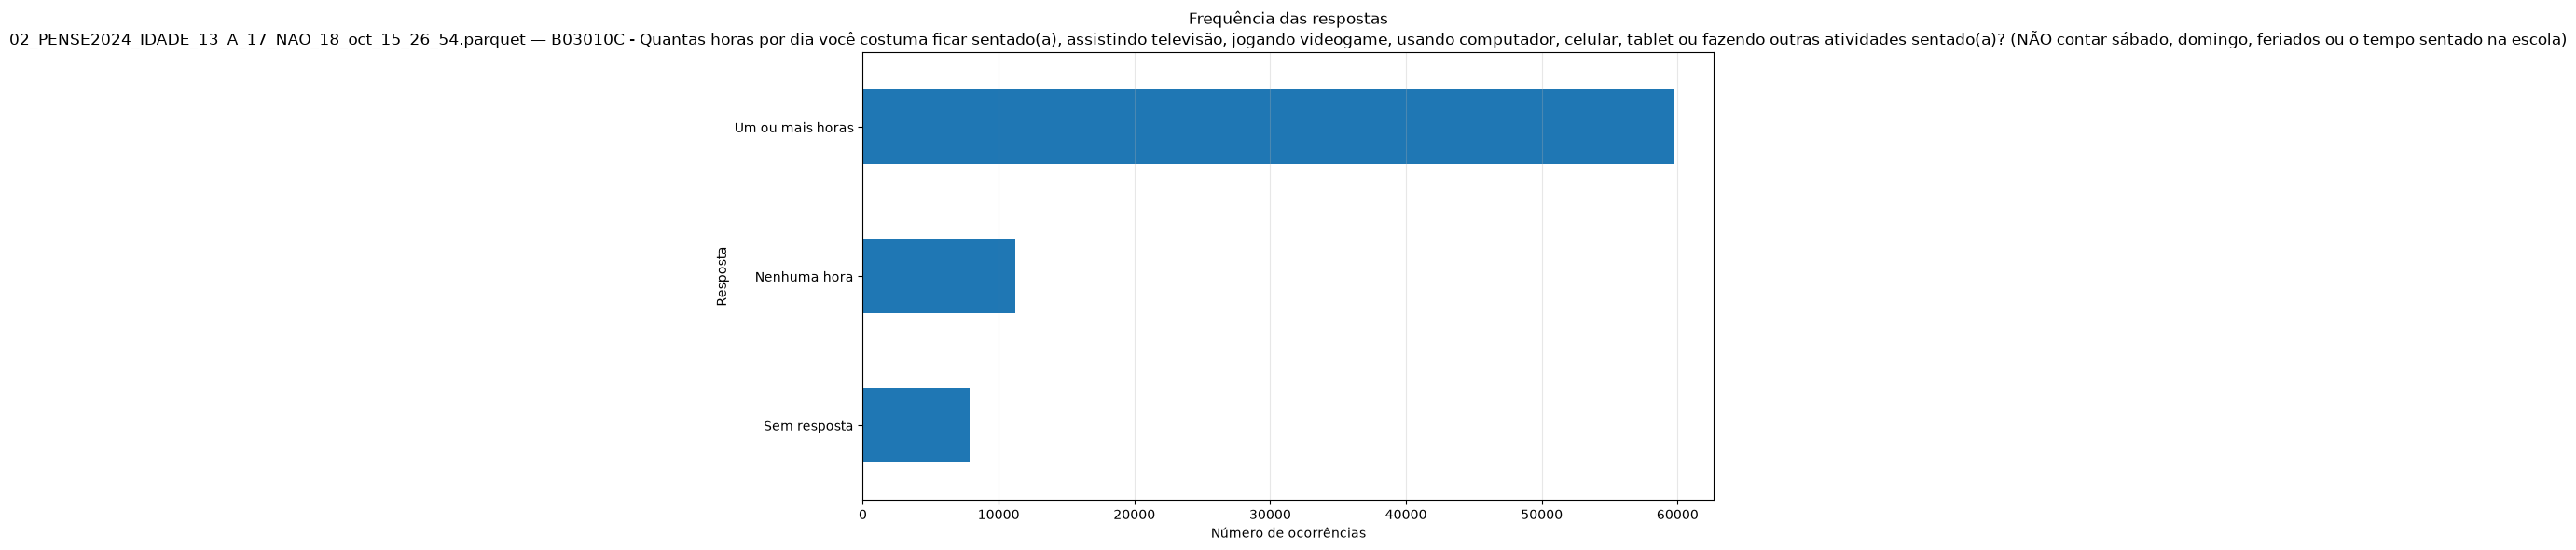


--------------------------------------------------------------------------------
Coluna: B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?

Tabela de frequências:


,frequencia,percentual
Nao,42319,53.71
Sim,36400,46.2
Sem resposta,70,0.09


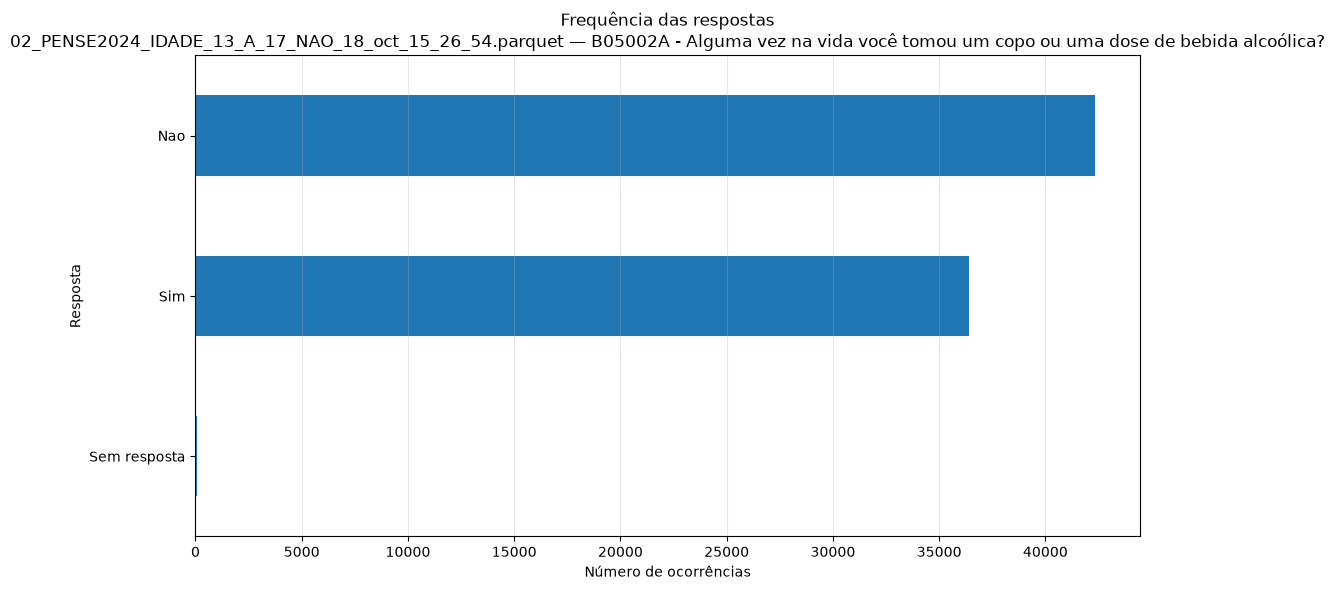


--------------------------------------------------------------------------------
Coluna: B07002 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável sabia realmente o que você estava fazendo em seu tempo livre?

Tabela de frequências:


,frequencia,percentual
Sabia,56283,71.44
Nunca/Raramente,11294,14.33
As vezes,11018,13.98
Sem resposta,194,0.25


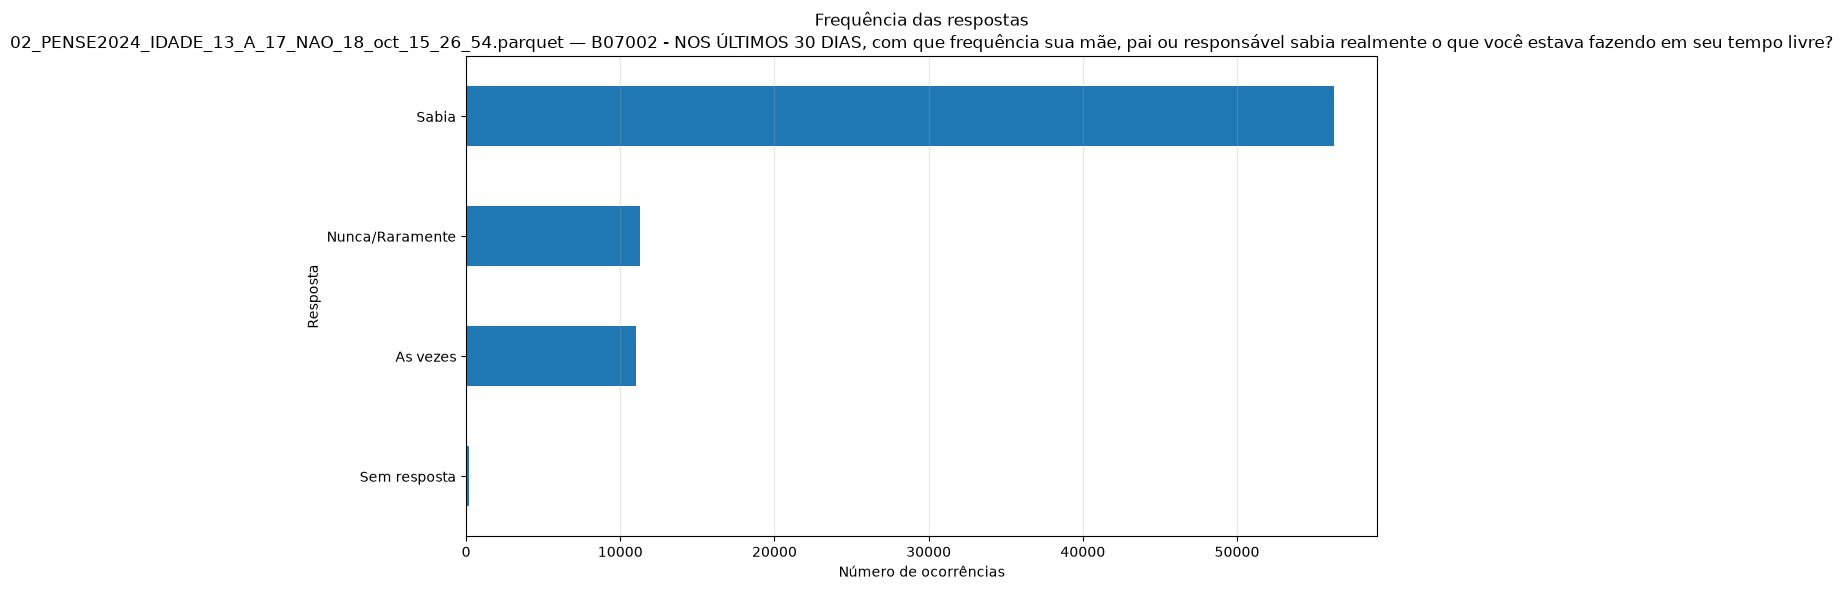


--------------------------------------------------------------------------------
Coluna: B07004 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável entendeu suas preocupações e problemas?

Tabela de frequências:


,frequencia,percentual
Entendia,40001,50.77
Nunca/Raramente,22357,28.38
As vezes,16196,20.56
Sem resposta,235,0.3


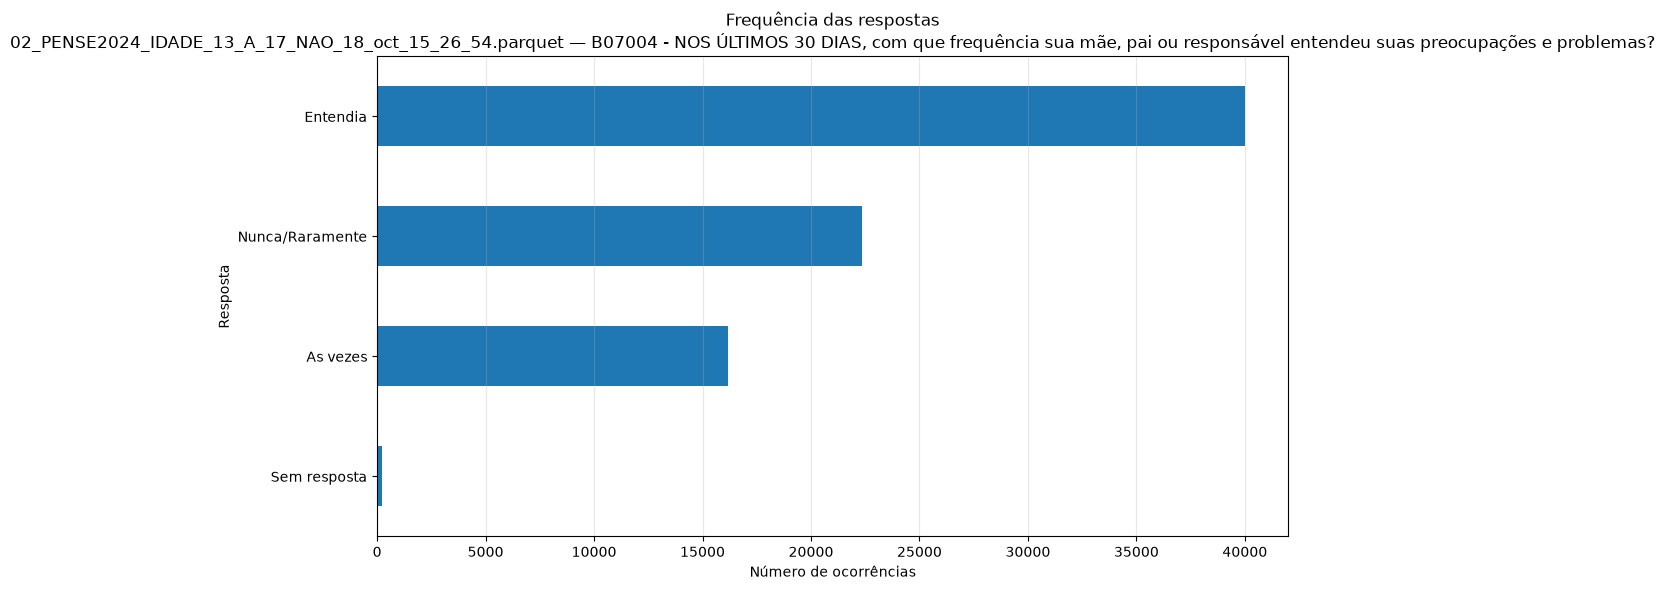


--------------------------------------------------------------------------------
Coluna: B07005 - NOS ÚLTIMOS 30 DIAS, com que frequência seus pais ou responsáveis mexeram em suas coisas sem a sua concordância?

Tabela de frequências:


,frequencia,percentual
Nunca/Raramente,57875,73.46
As vezes,12227,15.52
Sempre,8508,10.8
Sem resposta,179,0.23


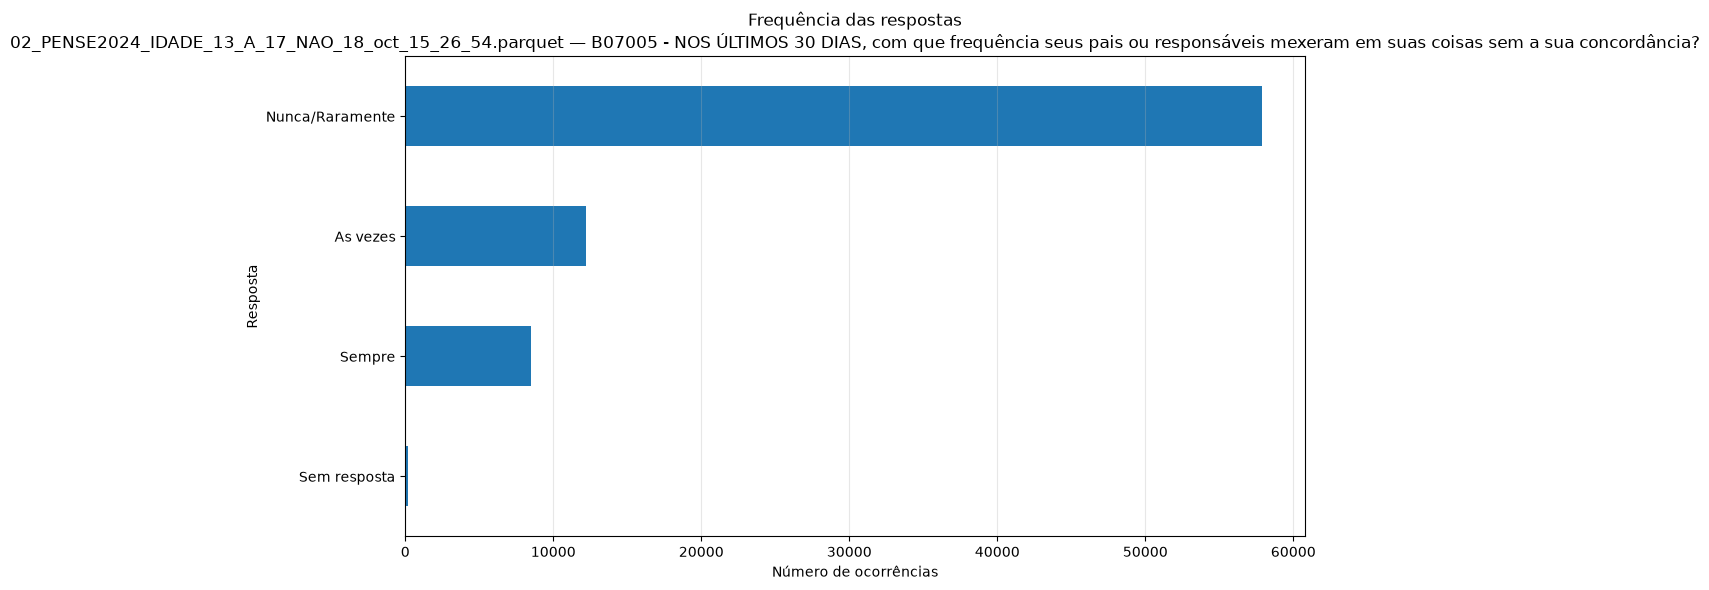


--------------------------------------------------------------------------------
Coluna: B07006 - NOS ÚLTIMOS 30 DIAS, com que frequência os colegas de sua escola trataram você bem e/ou foram prestativos com você?

Tabela de frequências:


,frequencia,percentual
Sim,54505,69.18
As vezes,13253,16.82
Nao,10861,13.78
Sem resposta,170,0.22


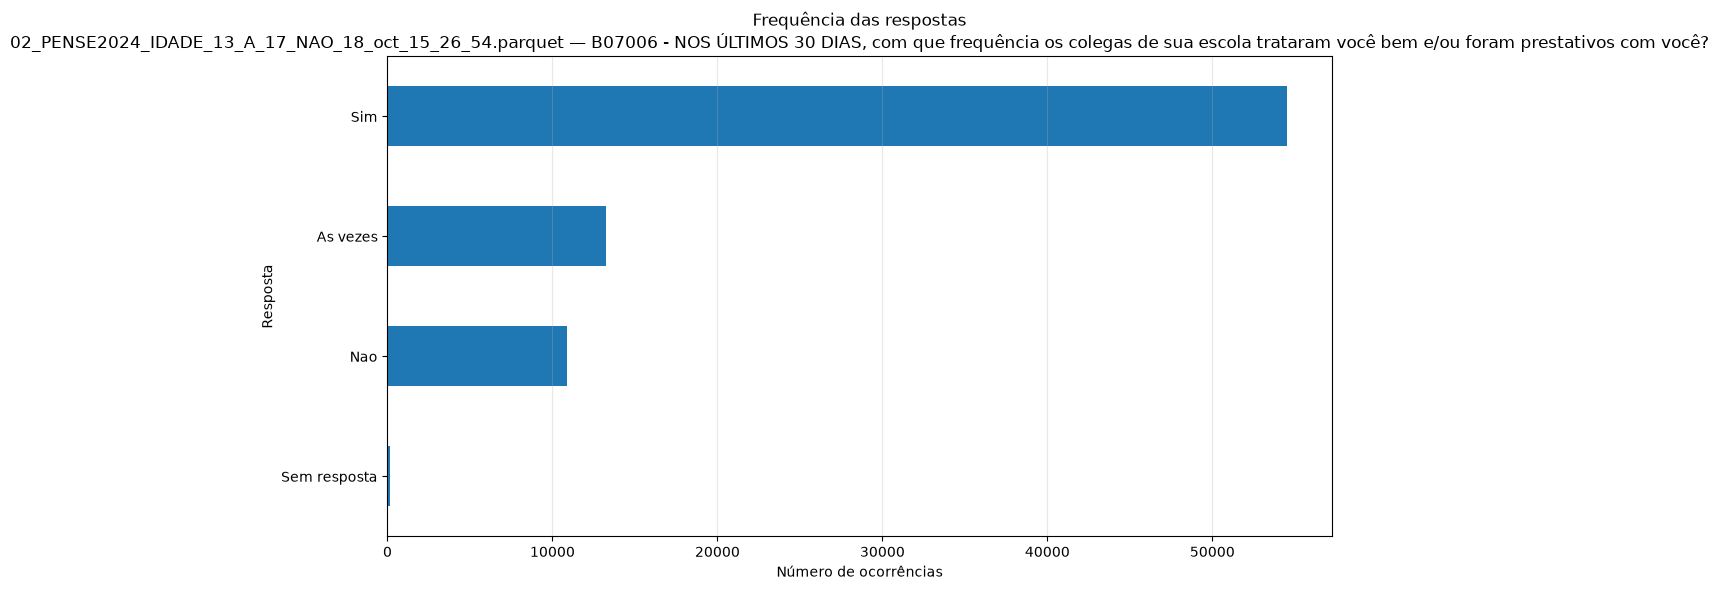


--------------------------------------------------------------------------------
Coluna: B07007B - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola o esculachou, zoou, mangou, intimidou ou caçoou tanto que você ficou magoado, incomodado, aborrecido, ofendido ou humilhado?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,51820,65.77
Uma ou mais vezes,26773,33.98
Sem resposta,196,0.25


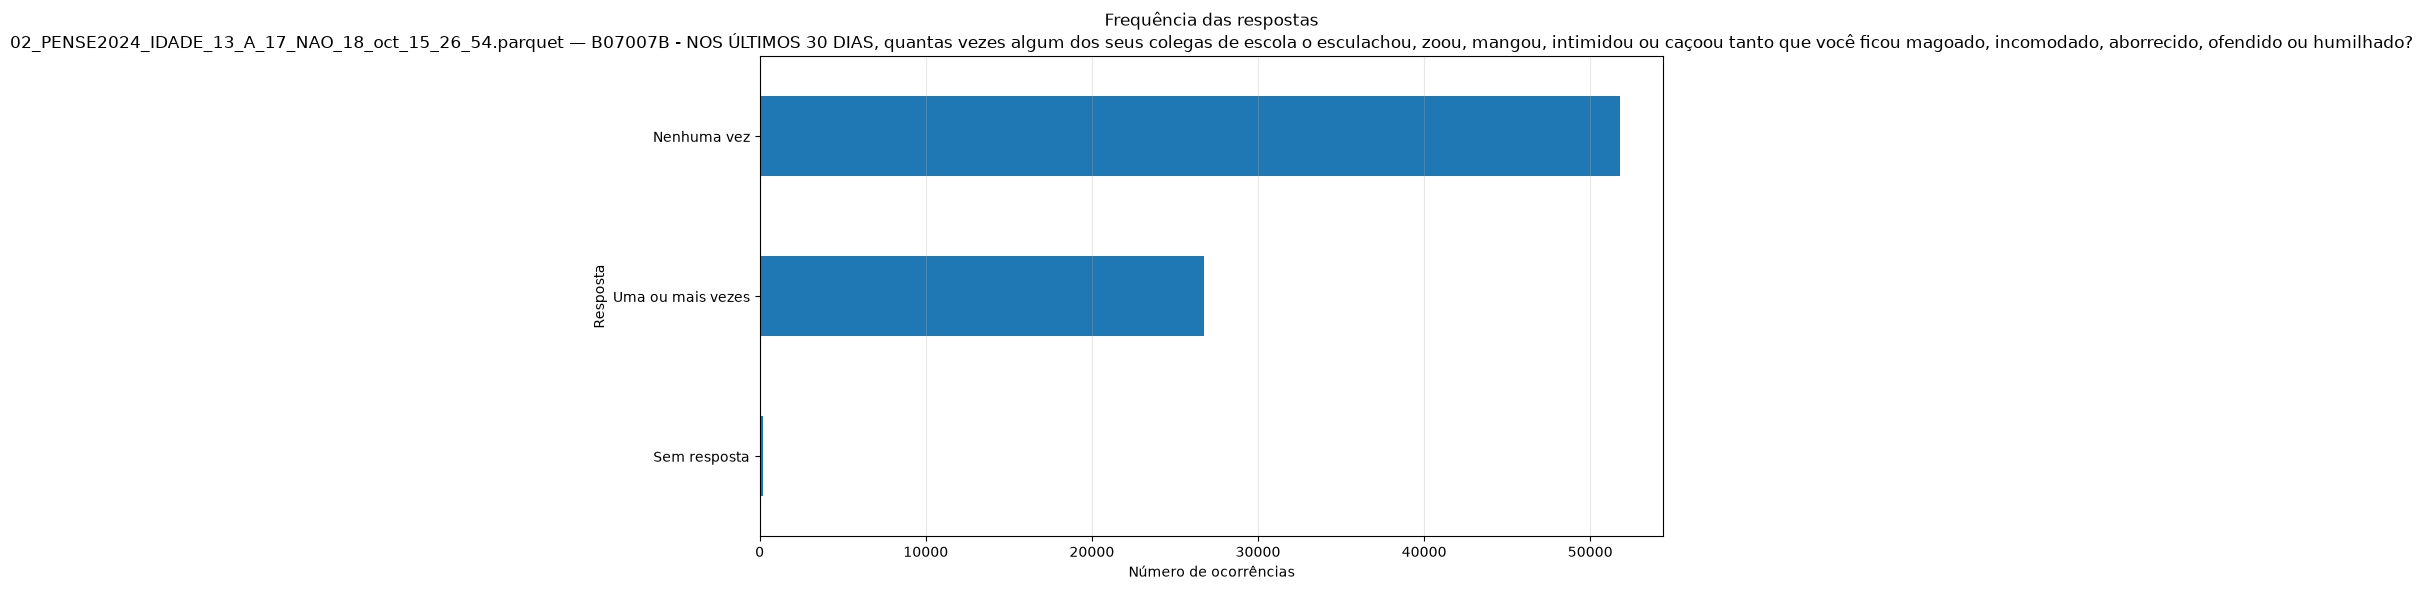


--------------------------------------------------------------------------------
Coluna: B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola se recusou a falar com você, deixou você de lado sem razão ou fez com que outros colegas deixassem de falar com você?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,63026,79.99
Uma ou mais vezes,15561,19.75
Sem resposta,202,0.26


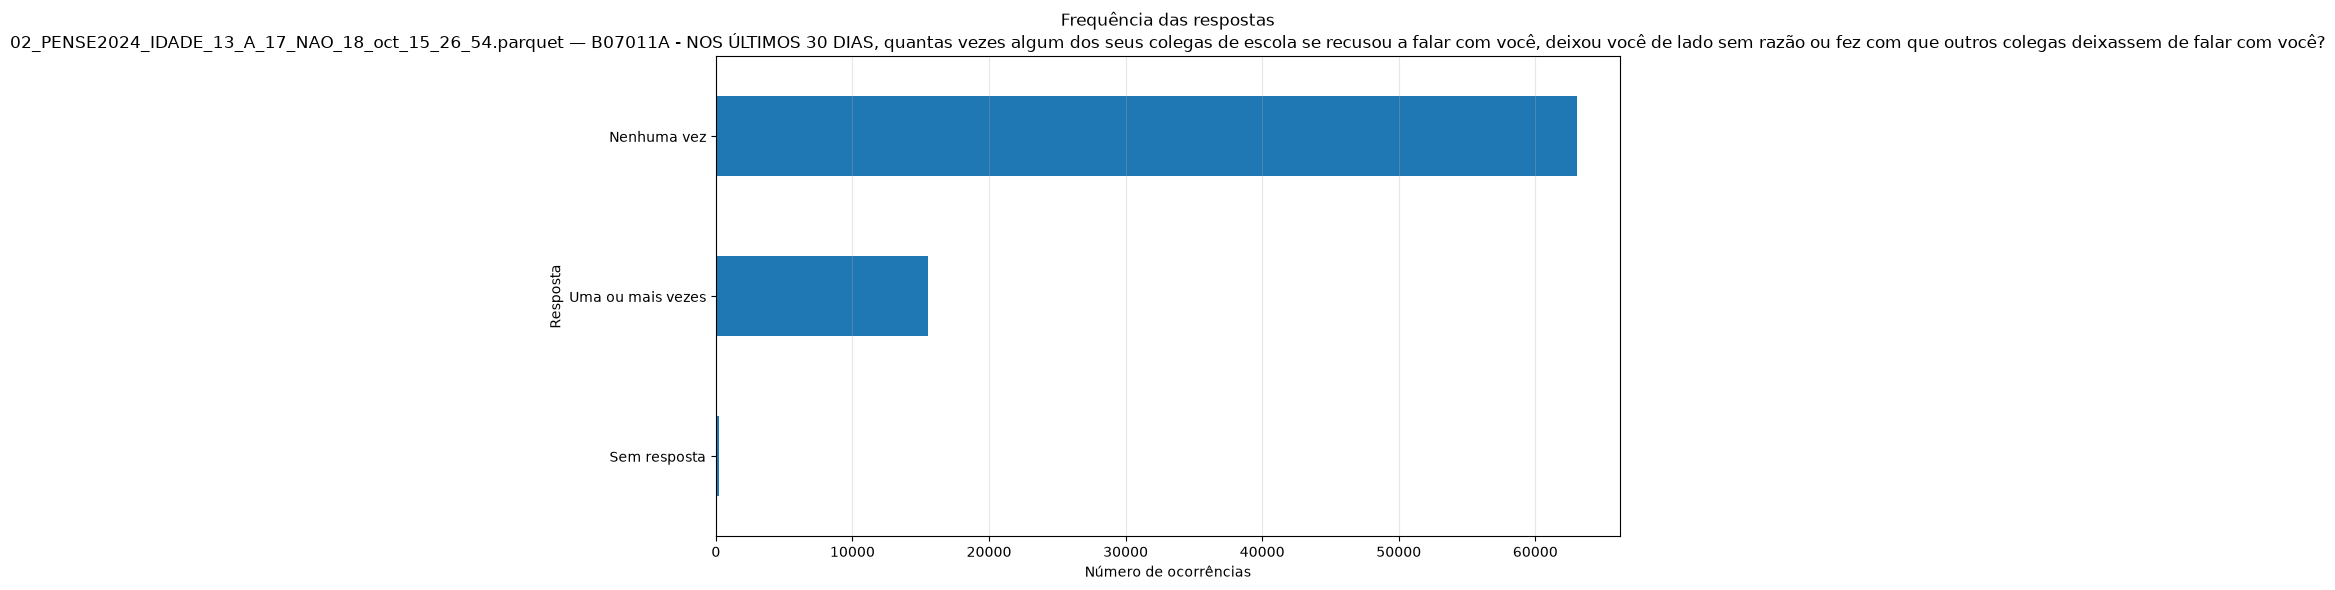


--------------------------------------------------------------------------------
Coluna: B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola bateu (deu socos, tapas, chutes, pontapés) em você ou o machucou fisicamente de outra forma?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,67597,85.79
Uma ou mais vezes,10987,13.94
Sem resposta,205,0.26


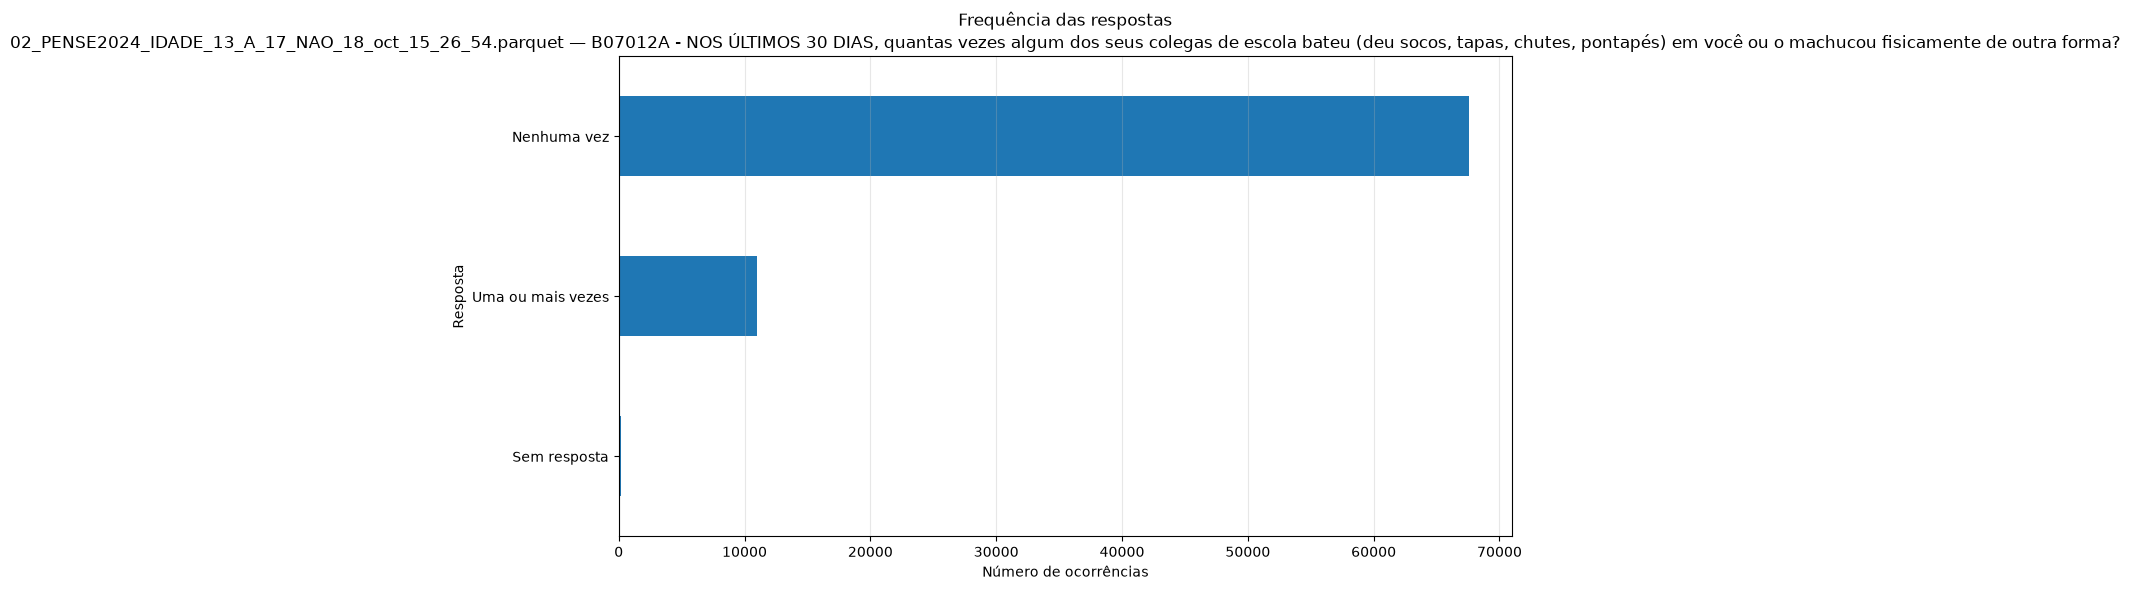


--------------------------------------------------------------------------------
Coluna: B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?

Tabela de frequências:


,frequencia,percentual
Nao,72818,92.42
Sim,5852,7.43
Sem resposta,119,0.15


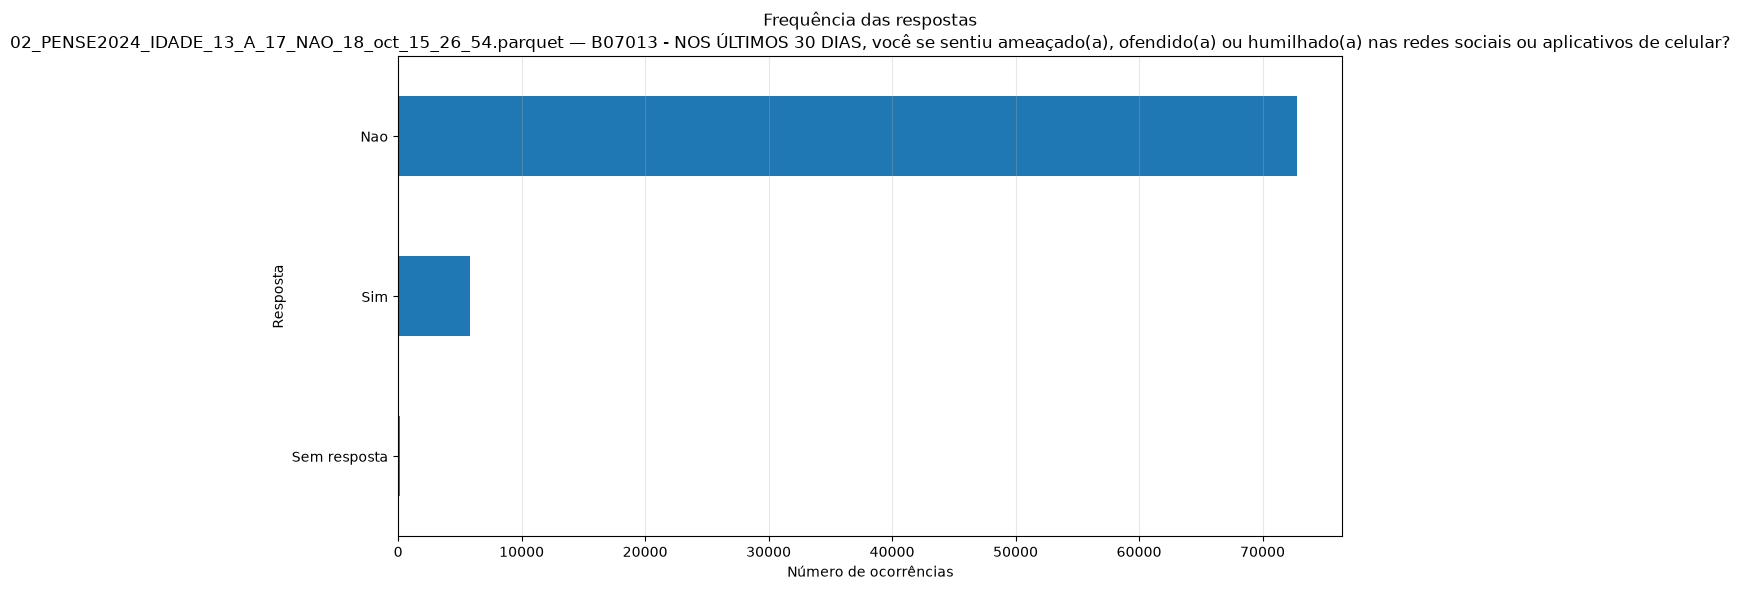


--------------------------------------------------------------------------------
Coluna: B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?

Tabela de frequências:


,frequencia,percentual
Nao,69114,87.72
Sim,9513,12.07
Sem resposta,162,0.21


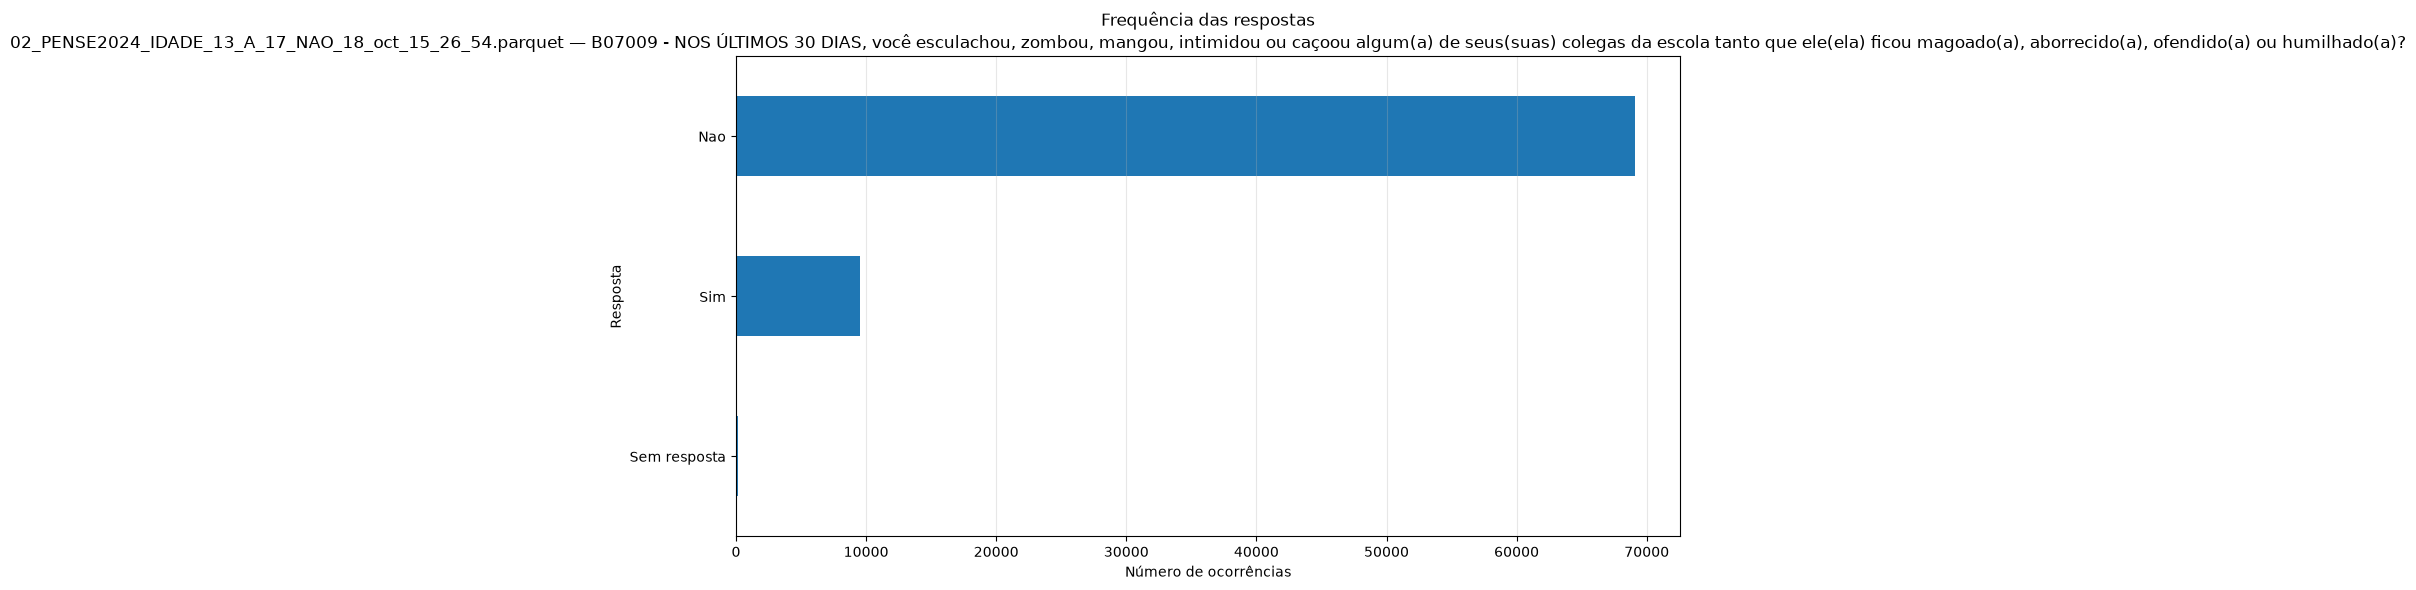


--------------------------------------------------------------------------------
Coluna: B07016 - NOS ÚLTIMOS 30 DIAS, você ameaçou, ofendeu ou humilhou outras pessoas nas redes sociais ou aplicativos de celular?

Tabela de frequências:


,frequencia,percentual
Nao,72024,91.41
Sim,6623,8.41
Sem resposta,142,0.18


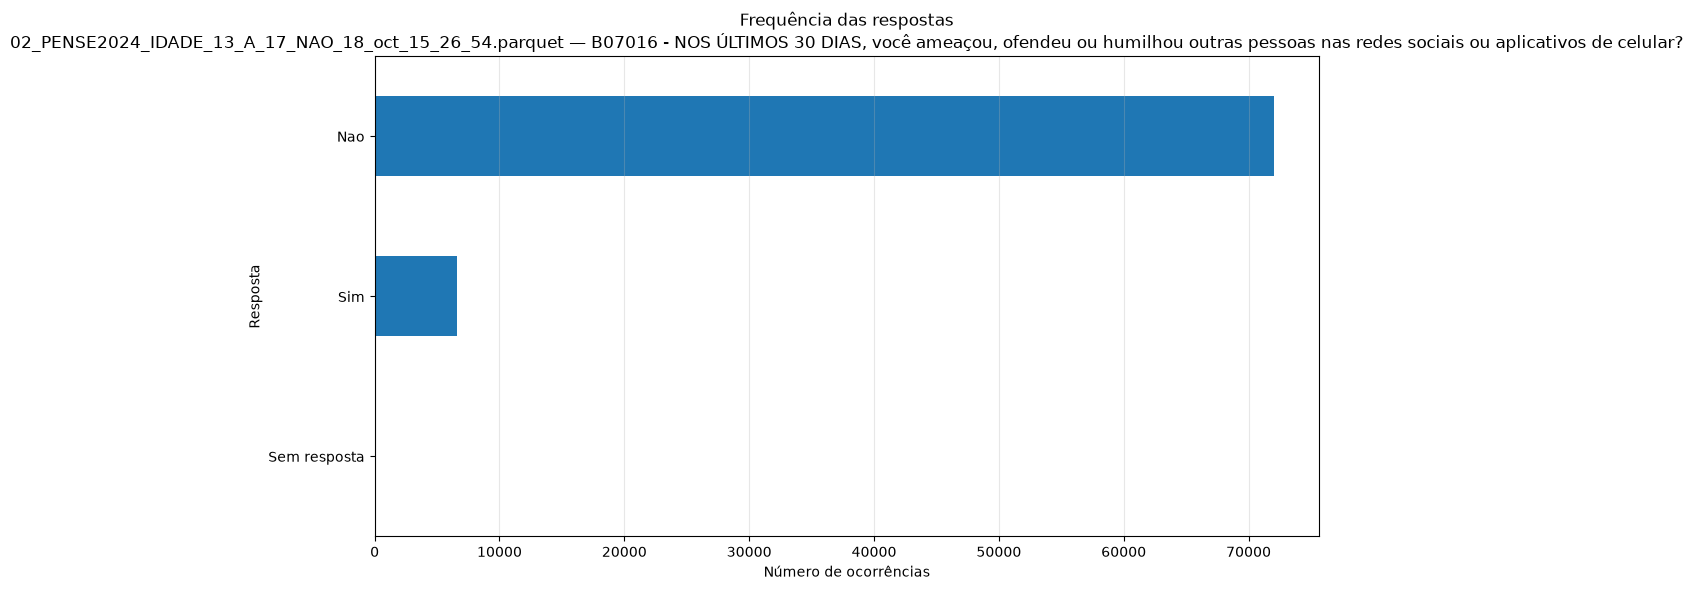


--------------------------------------------------------------------------------
Coluna: B12003 - Quantos(as) amigos(as) próximos você tem?

Tabela de frequências:


,frequencia,percentual
Mais que um,76153,96.65
Nenhum,2542,3.23
Sem resposta,94,0.12


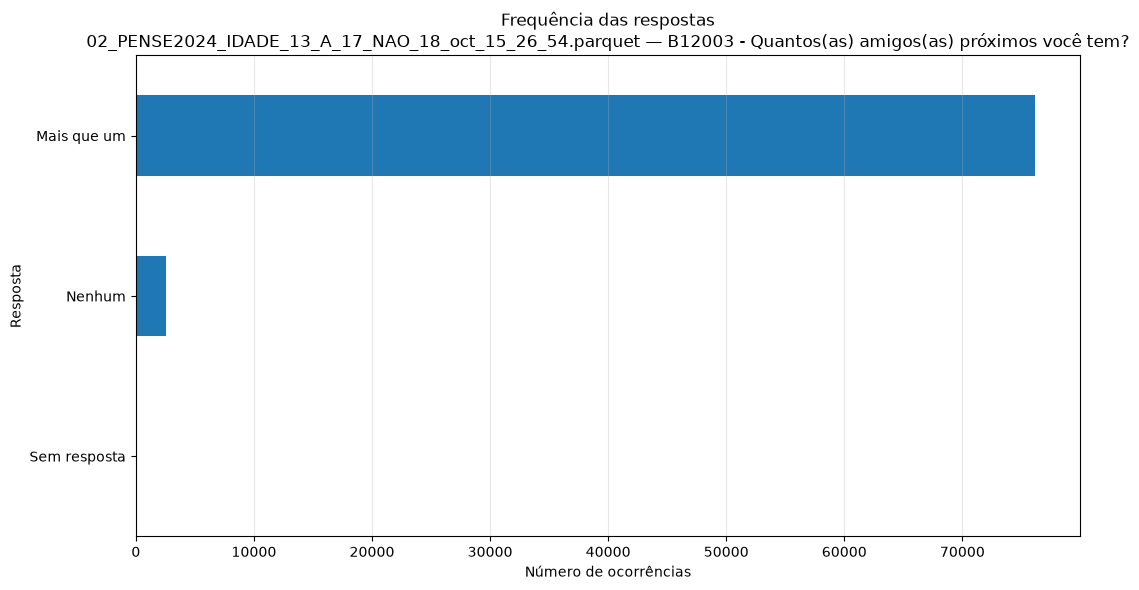


--------------------------------------------------------------------------------
Coluna: B12004 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu muito preocupado com as coisas comuns do seu dia a dia como atividades da escola, competições esportivas, tarefas de casa, etc.?

Tabela de frequências:


,frequencia,percentual
Sempre,39458,50.08
As vezes,21469,27.25
Nunca/Raramente,17677,22.44
Sem resposta,185,0.23


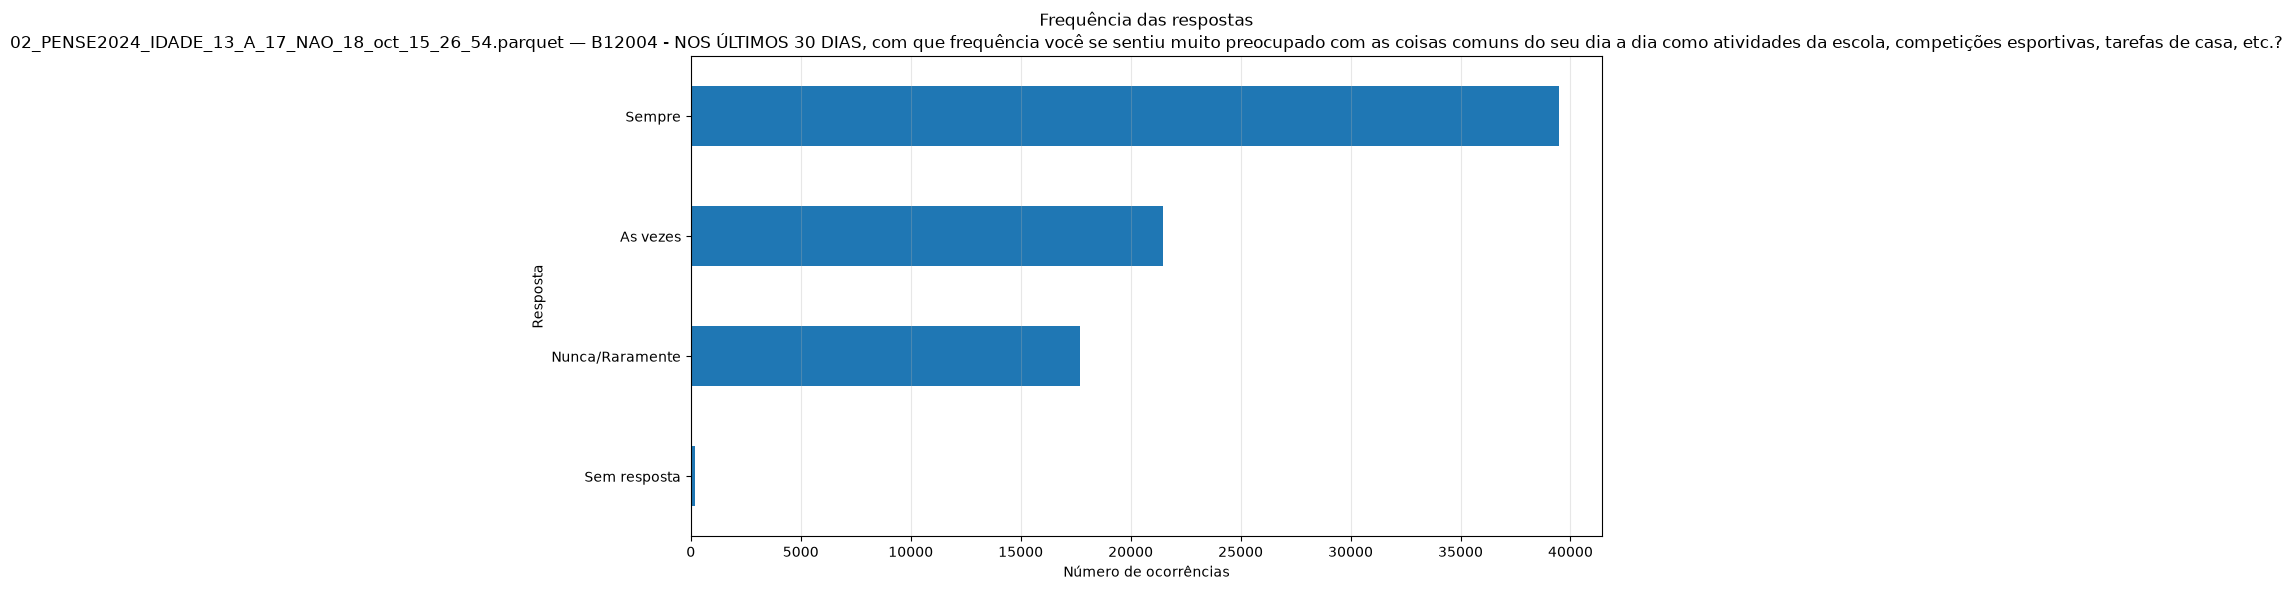


--------------------------------------------------------------------------------
Coluna: B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?

Tabela de frequências:


,frequencia,percentual
Nunca/Raramente,35002,44.42
As vezes,30297,38.45
Sempre,13362,16.96
Sem resposta,128,0.16


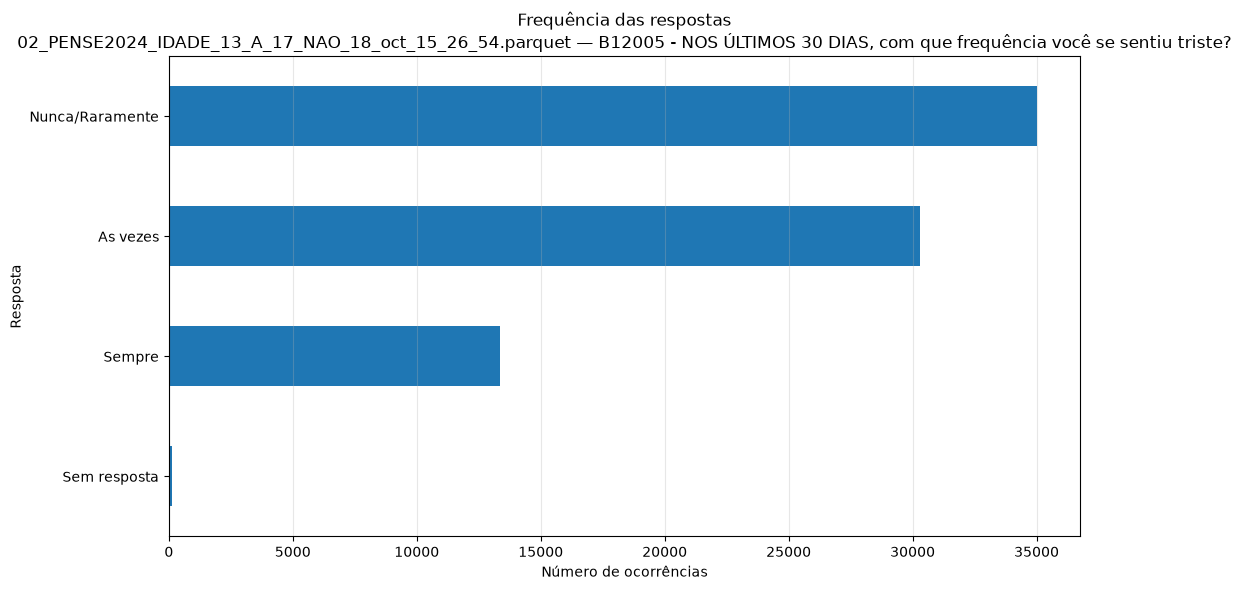


--------------------------------------------------------------------------------
Coluna: B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?

Tabela de frequências:


,frequencia,percentual
Nunca/Raramente,47456,60.23
As vezes,18128,23.01
Sempre,13031,16.54
Sem resposta,174,0.22


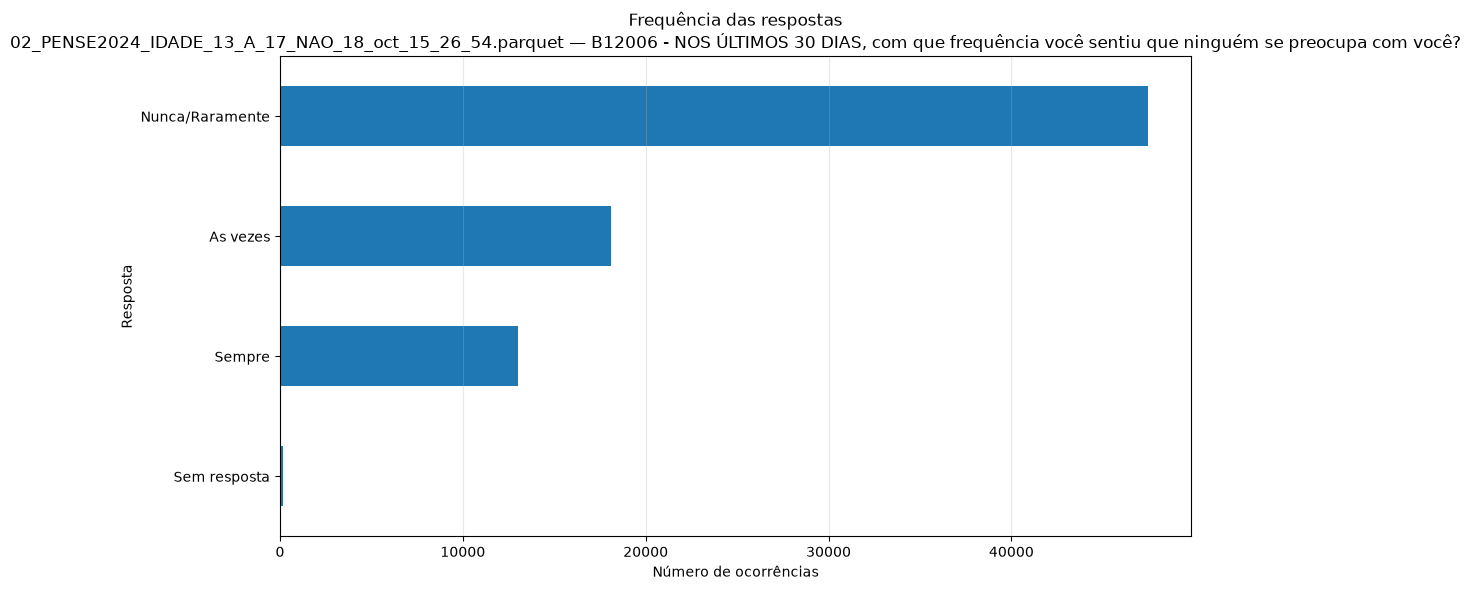


--------------------------------------------------------------------------------
Coluna: B12007 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu irritado(a), nervoso(a) ou mal-humorado(a) por qualquer coisa?

Tabela de frequências:


,frequencia,percentual
As vezes,28001,35.54
Sempre,27390,34.76
Nunca/Raramente,23241,29.5
Sem resposta,157,0.2


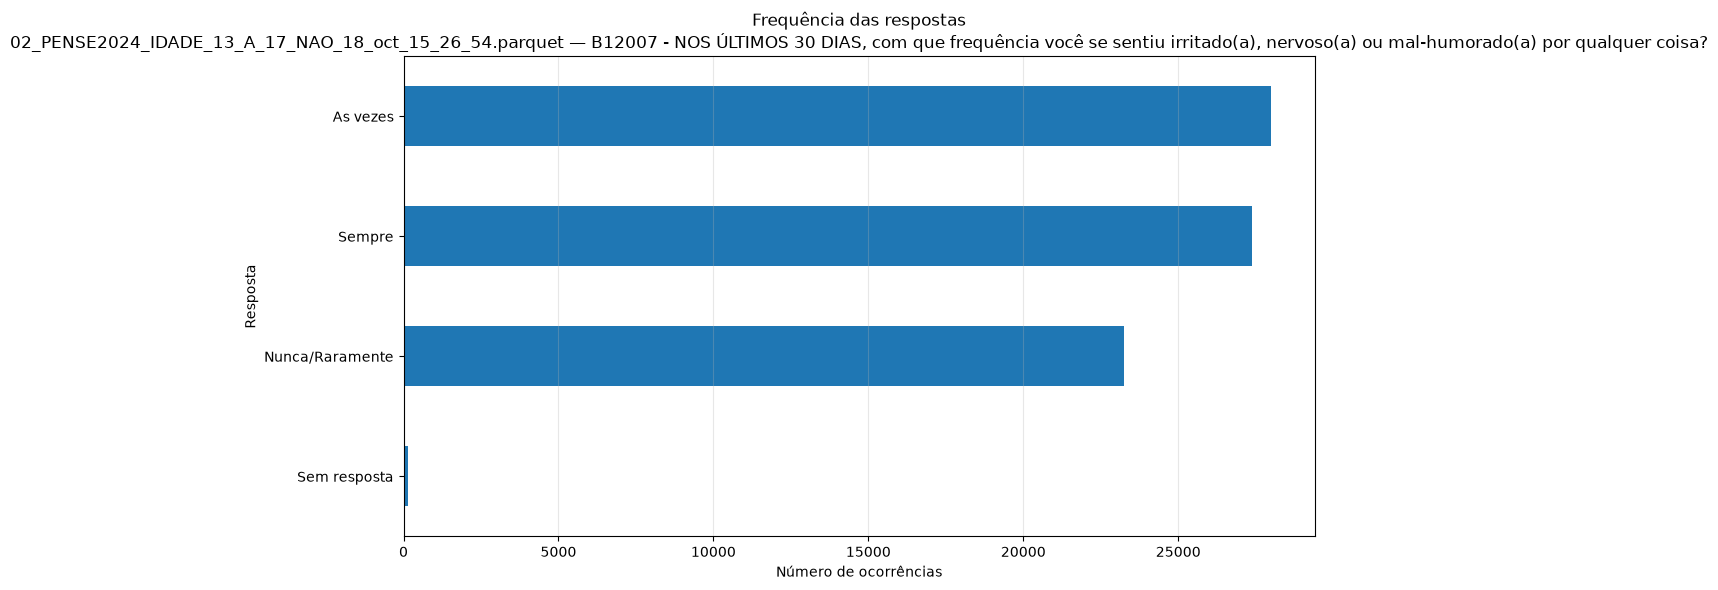


--------------------------------------------------------------------------------
Coluna: B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?

Tabela de frequências:


,frequencia,percentual
Nunca/Raramente,63645,80.78
As vezes,8850,11.23
Sempre,6103,7.75
Sem resposta,191,0.24


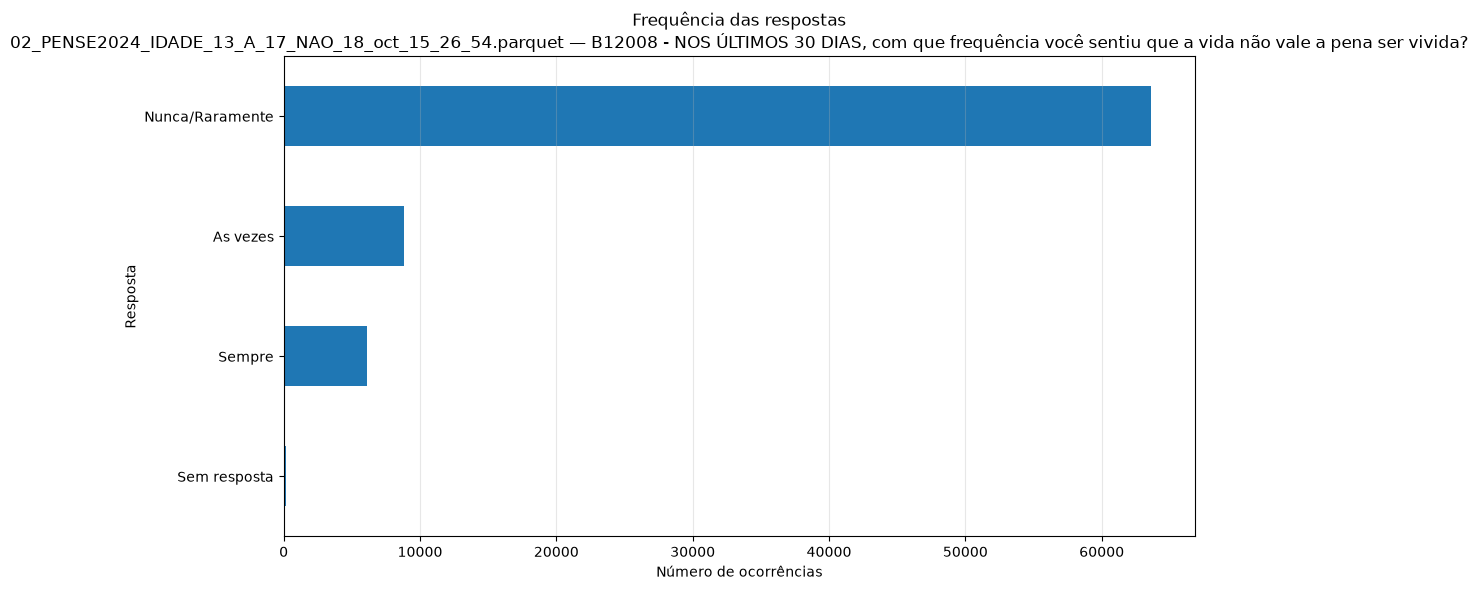


--------------------------------------------------------------------------------
Coluna: B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?

Tabela de frequências:


,frequencia,percentual
Nao,78789,100.0


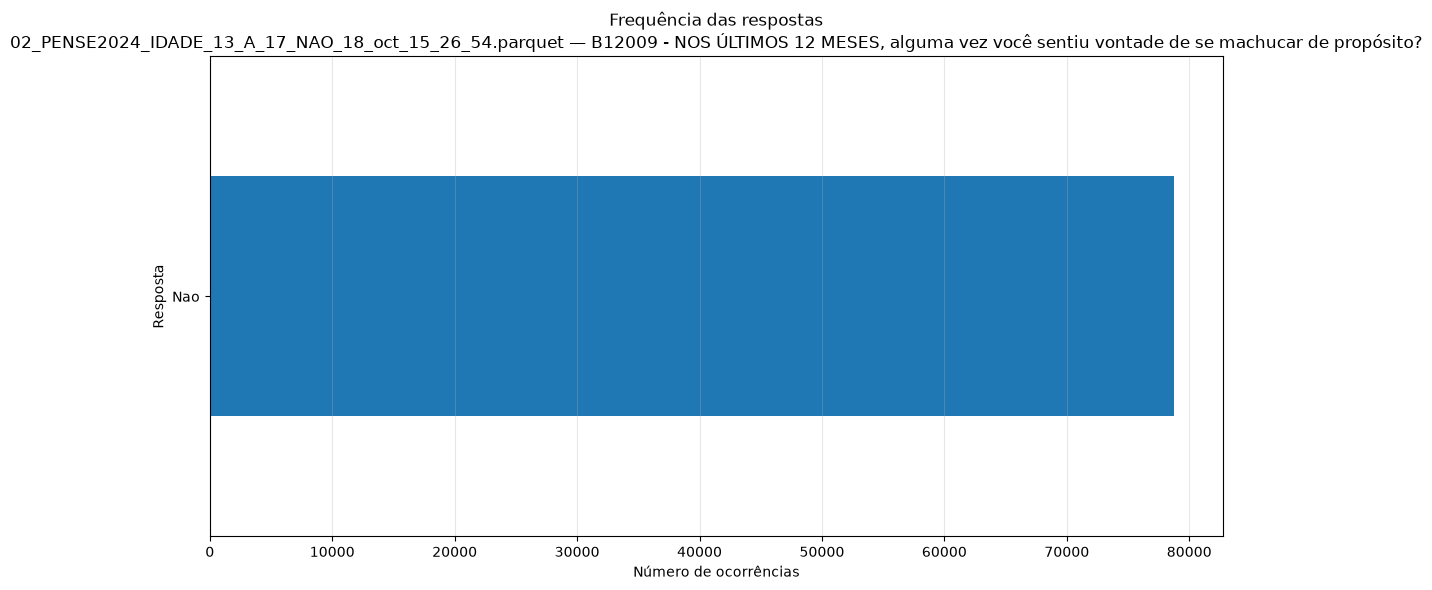


--------------------------------------------------------------------------------
Coluna: B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO de casa para a escola ou da escola para casa?

Tabela de frequências:


,frequencia,percentual
Nenhum dia,71922,91.28
1 ou mais dias,6381,8.1
Sem resposta,486,0.62


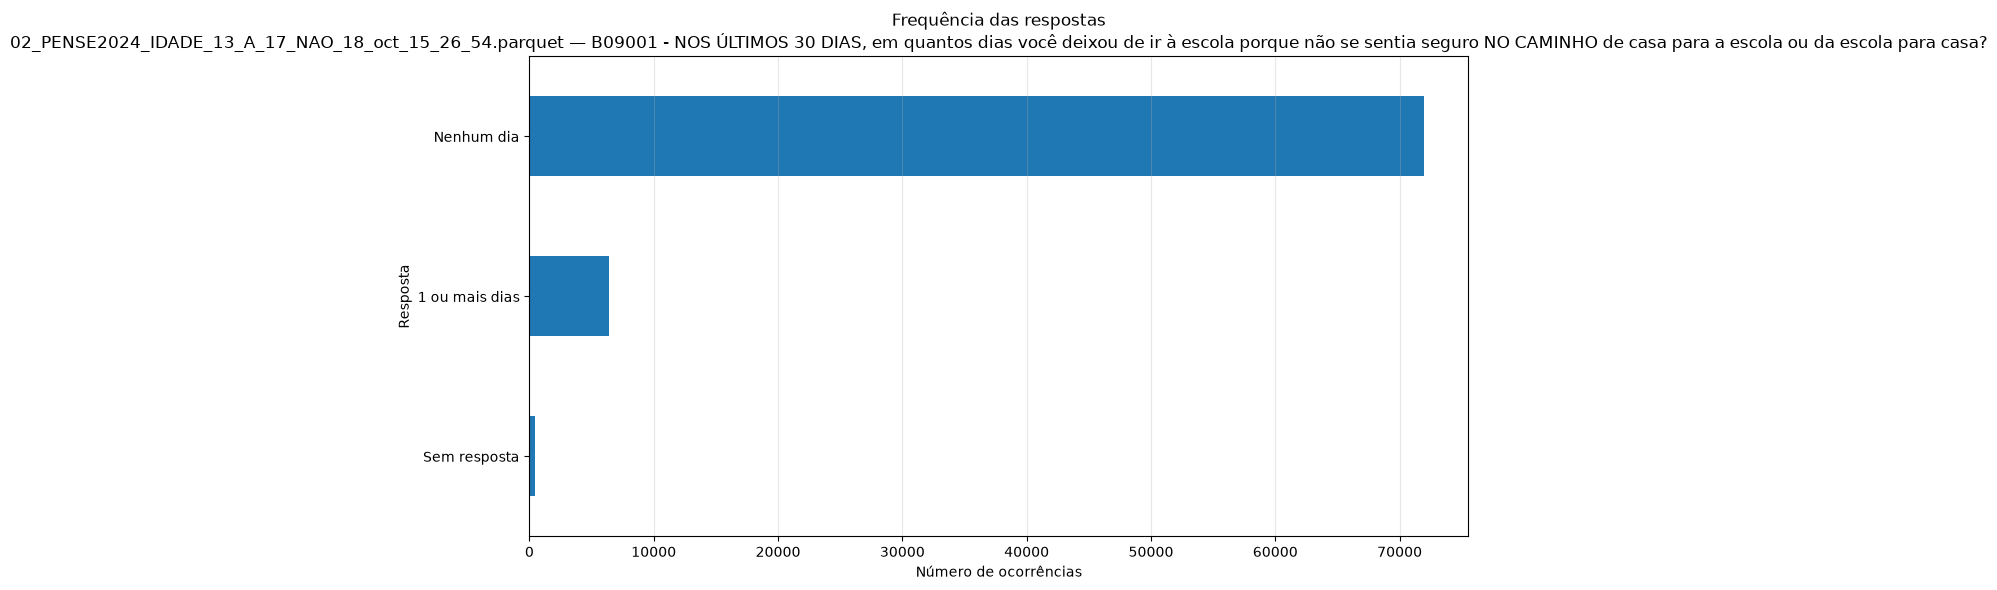


--------------------------------------------------------------------------------
Coluna: B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?

Tabela de frequências:


,frequencia,percentual
Nenhum dia,72207,91.65
1 ou mais dias,6053,7.68
Sem resposta,529,0.67


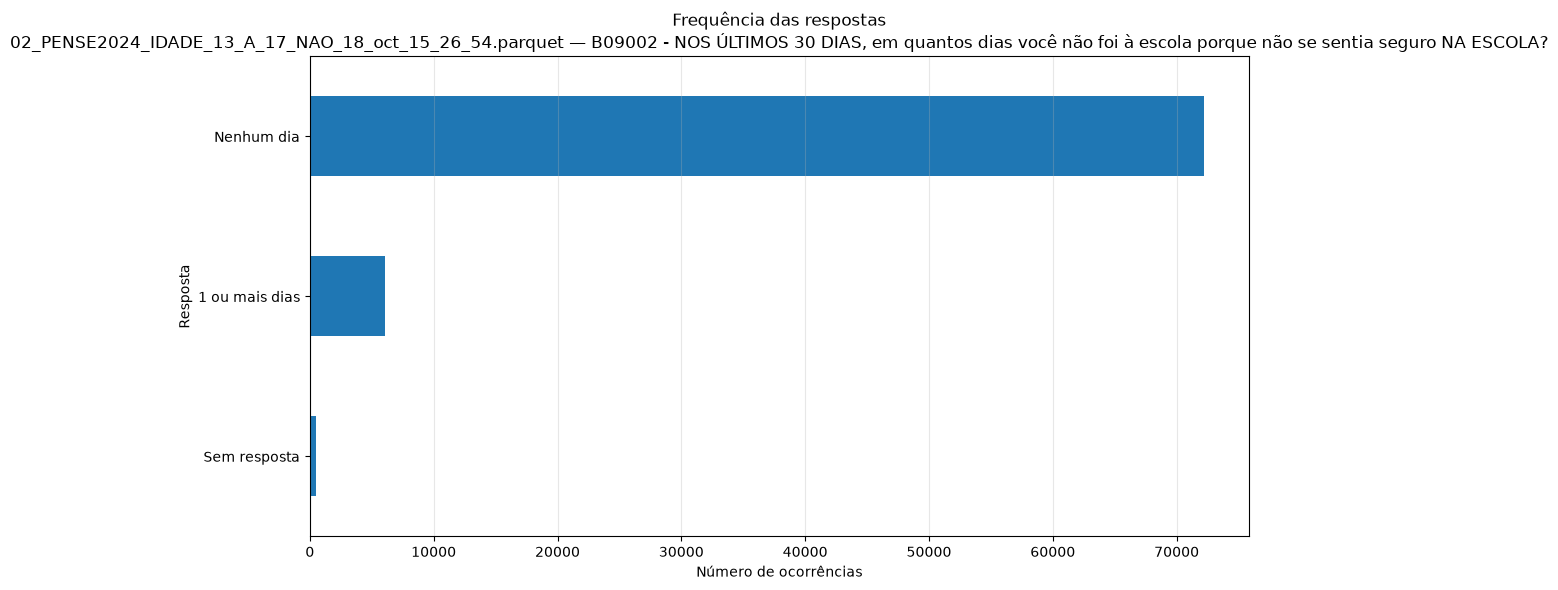


--------------------------------------------------------------------------------
Coluna: B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,65999,83.77
1 ou mais vezes,12239,15.53
Sem resposta,551,0.7


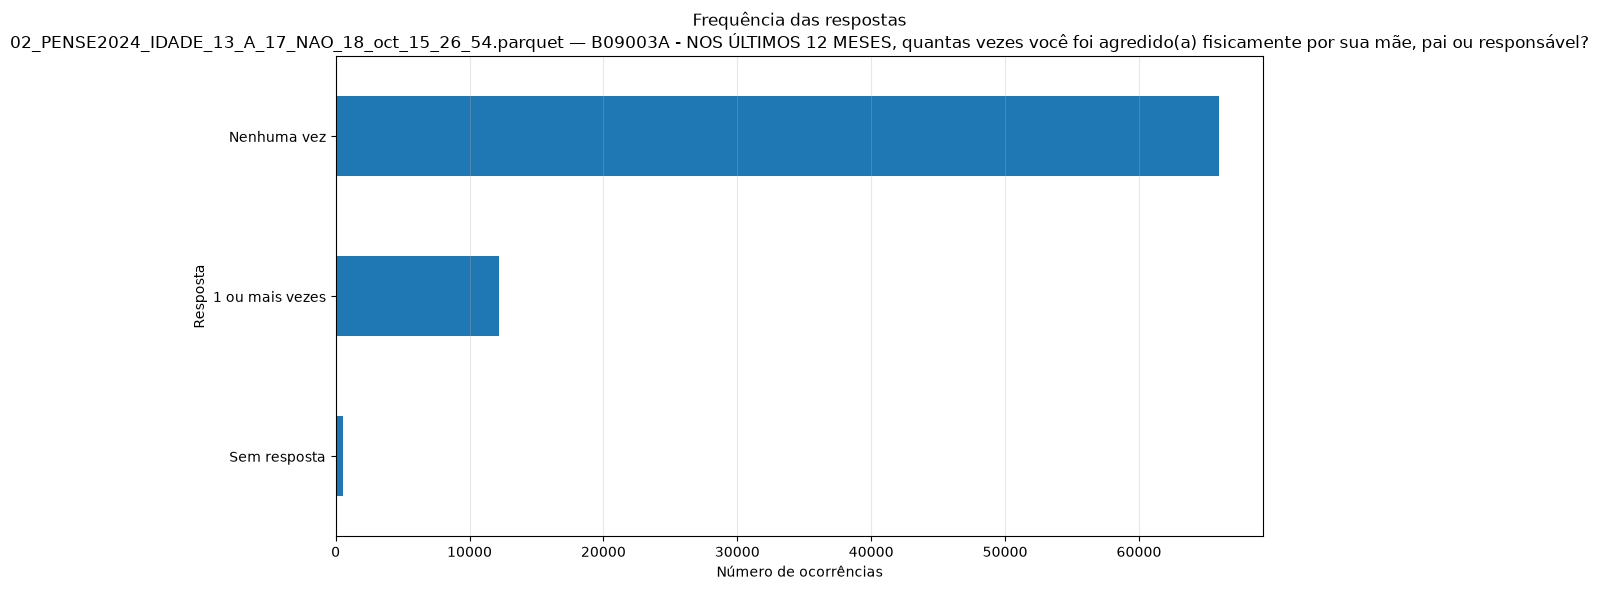


--------------------------------------------------------------------------------
Coluna: B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,70308,89.24
1 ou mais vezes,7901,10.03
Sem resposta,580,0.74


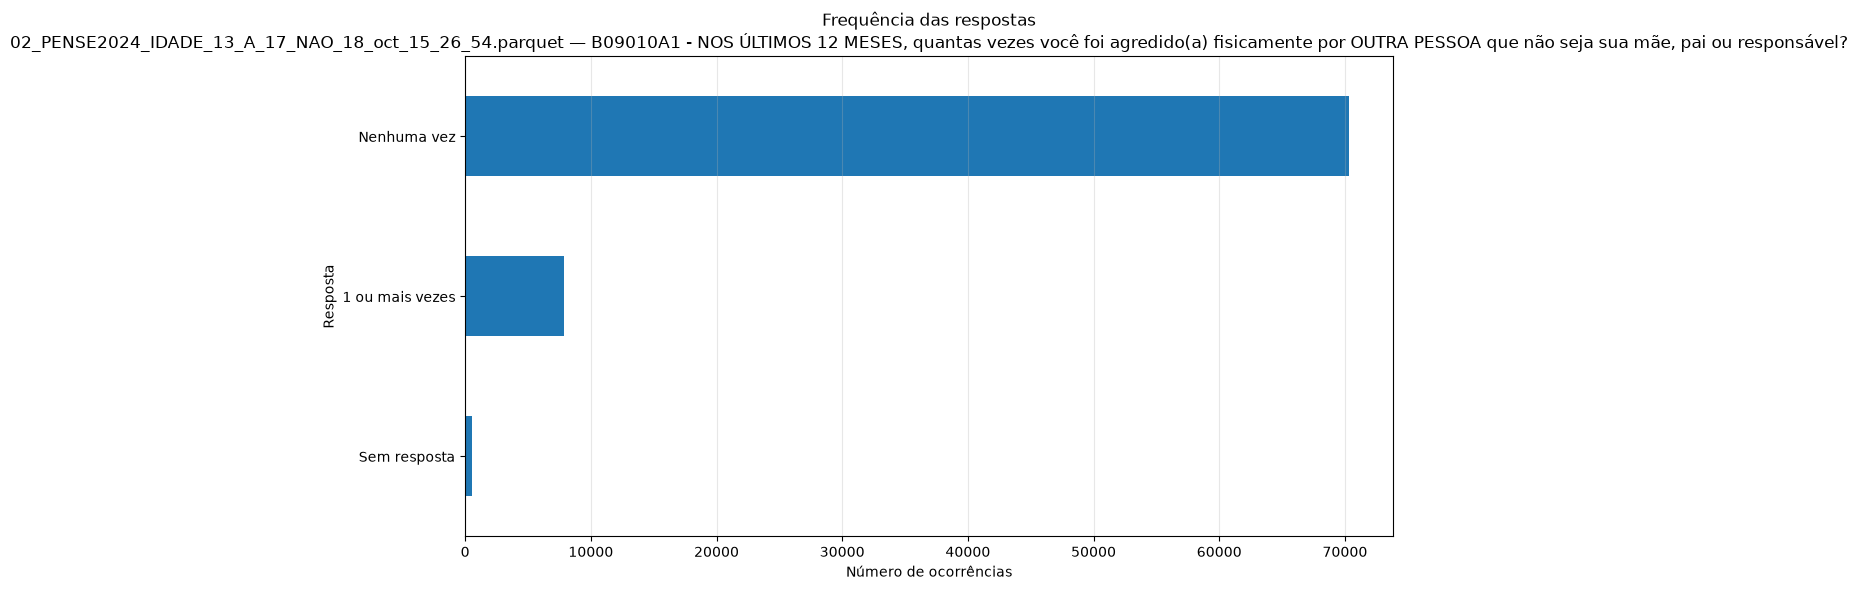


--------------------------------------------------------------------------------
Coluna: B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?

Tabela de frequências:


,frequencia,percentual
Nao,69295,87.95
Sim,8937,11.34
Sem resposta,557,0.71


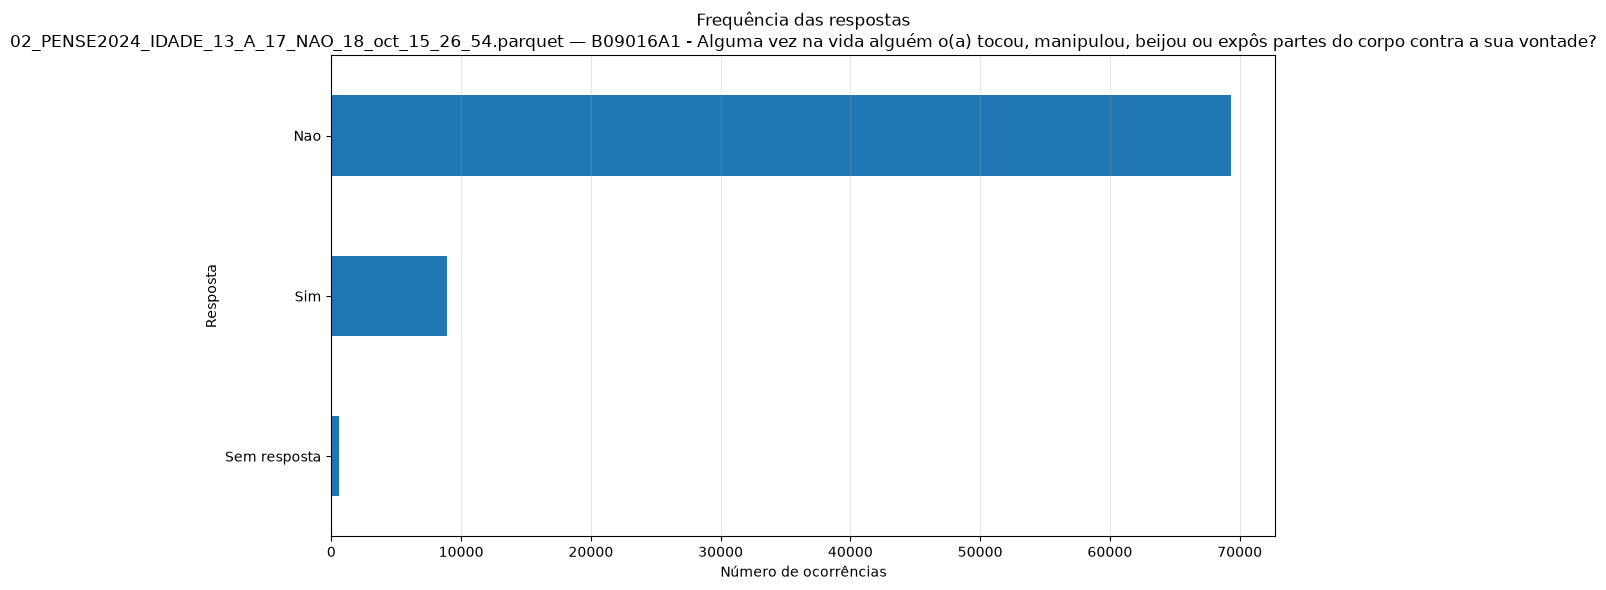


--------------------------------------------------------------------------------
Coluna: B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?

Tabela de frequências:


,frequencia,percentual
Nao,74974,95.16
Sim,3223,4.09
Sem resposta,592,0.75


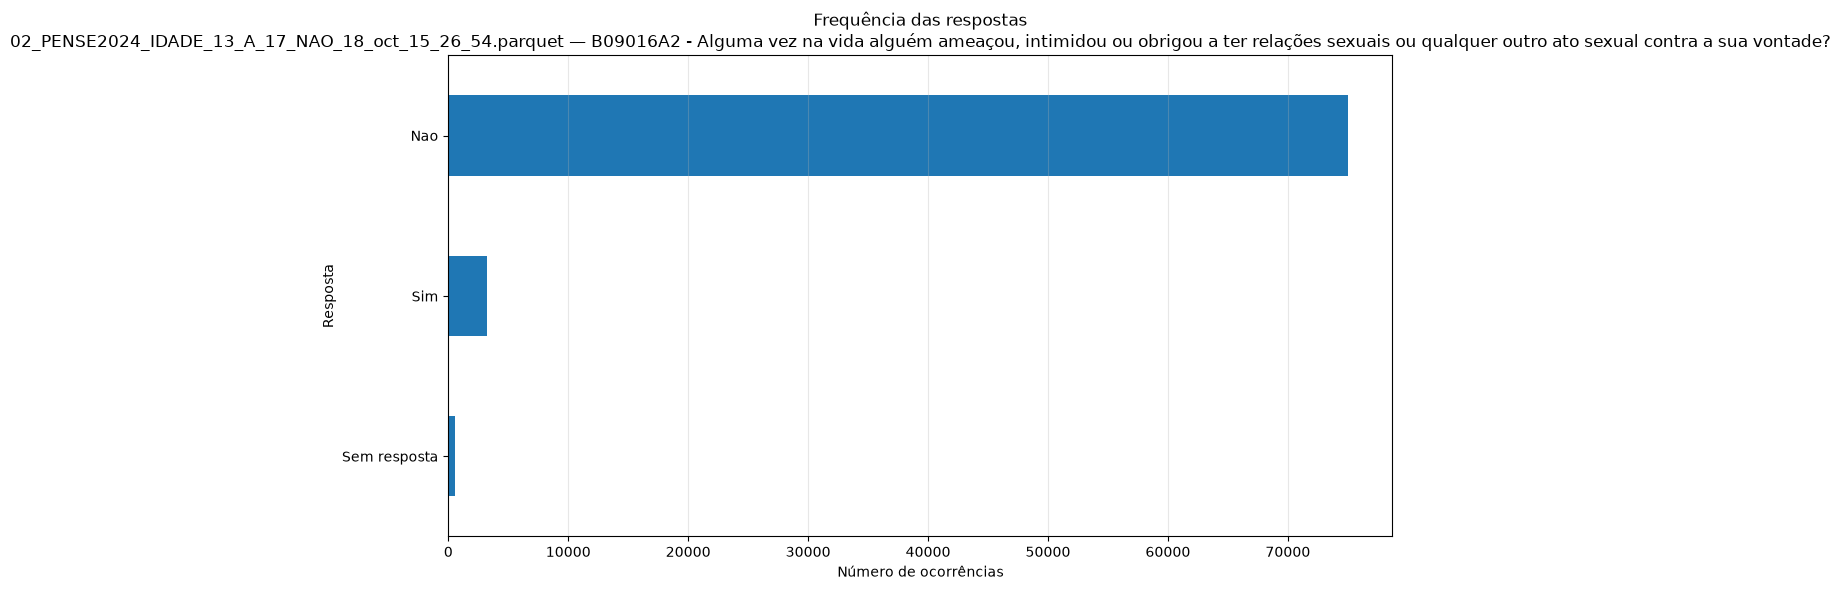


--------------------------------------------------------------------------------
Coluna: E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes

Tabela de frequências:


,frequencia,percentual
Sim,43655,55.41
Nao,34805,44.17
Sem resposta,329,0.42


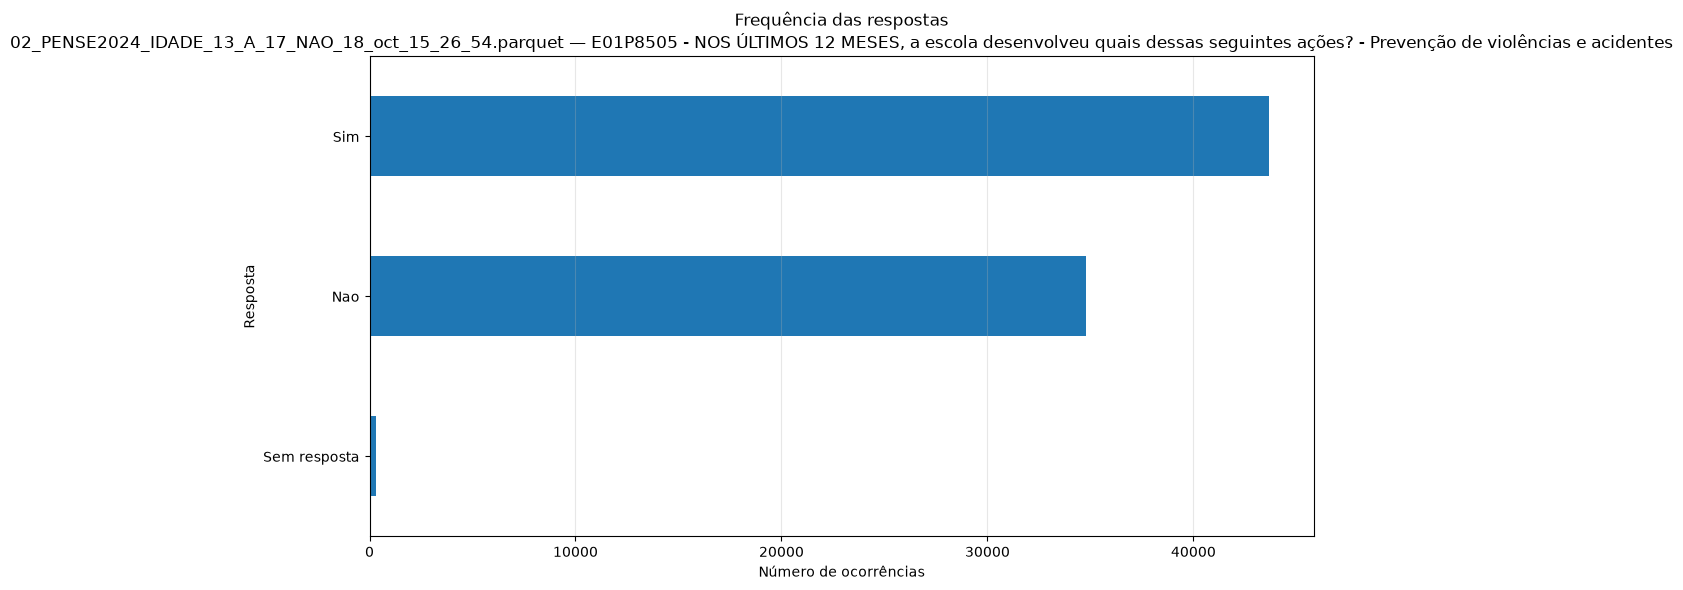


--------------------------------------------------------------------------------
Coluna: E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola

Tabela de frequências:


,frequencia,percentual
Sim,40308,51.16
Nao,38152,48.42
Sem resposta,329,0.42


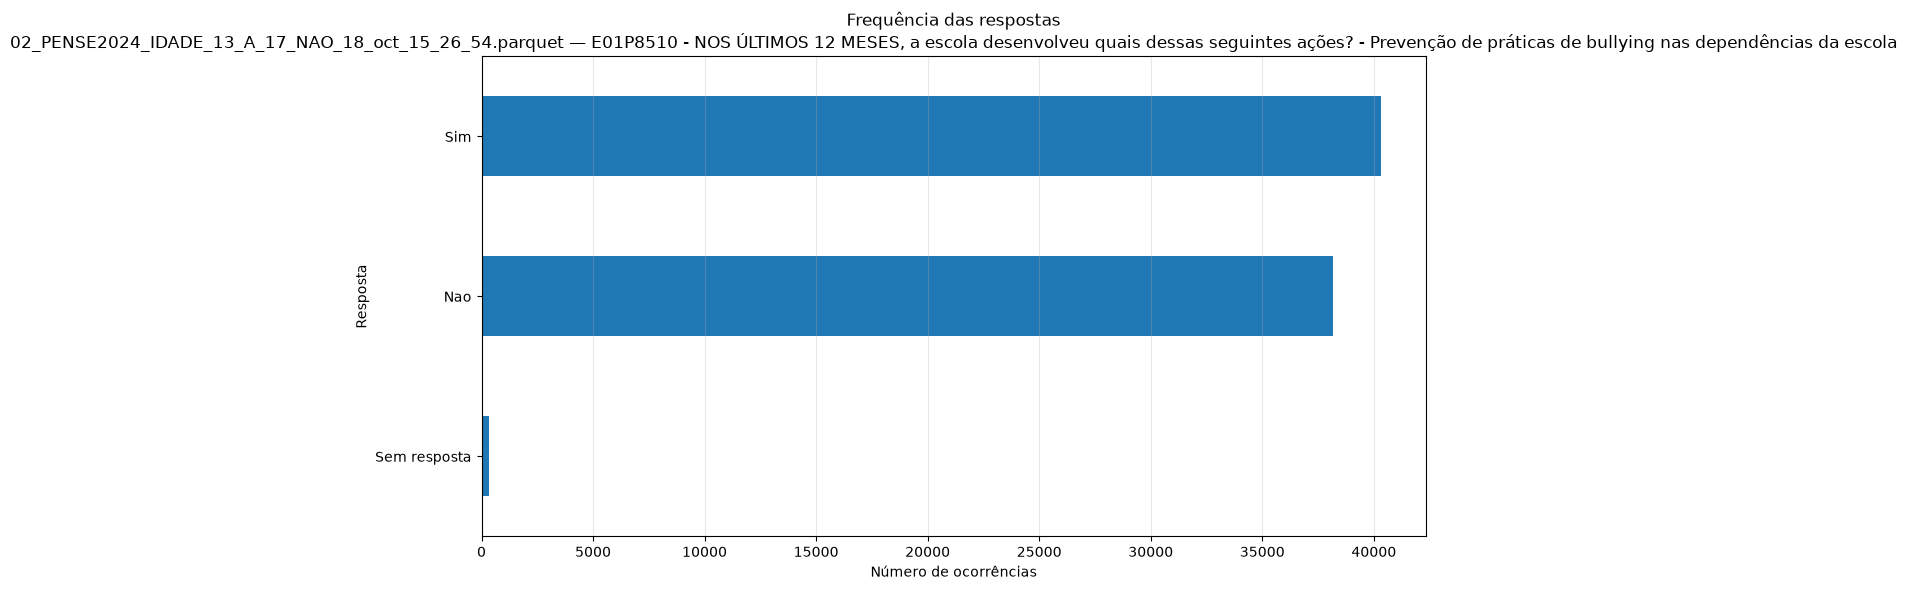


--------------------------------------------------------------------------------
Coluna: E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?

Tabela de frequências:


,frequencia,percentual
Sim,40403,51.28
Sim,23068,29.28
Não,14159,17.97
Sim,1060,1.35
Código não mapeado: 0,99,0.13


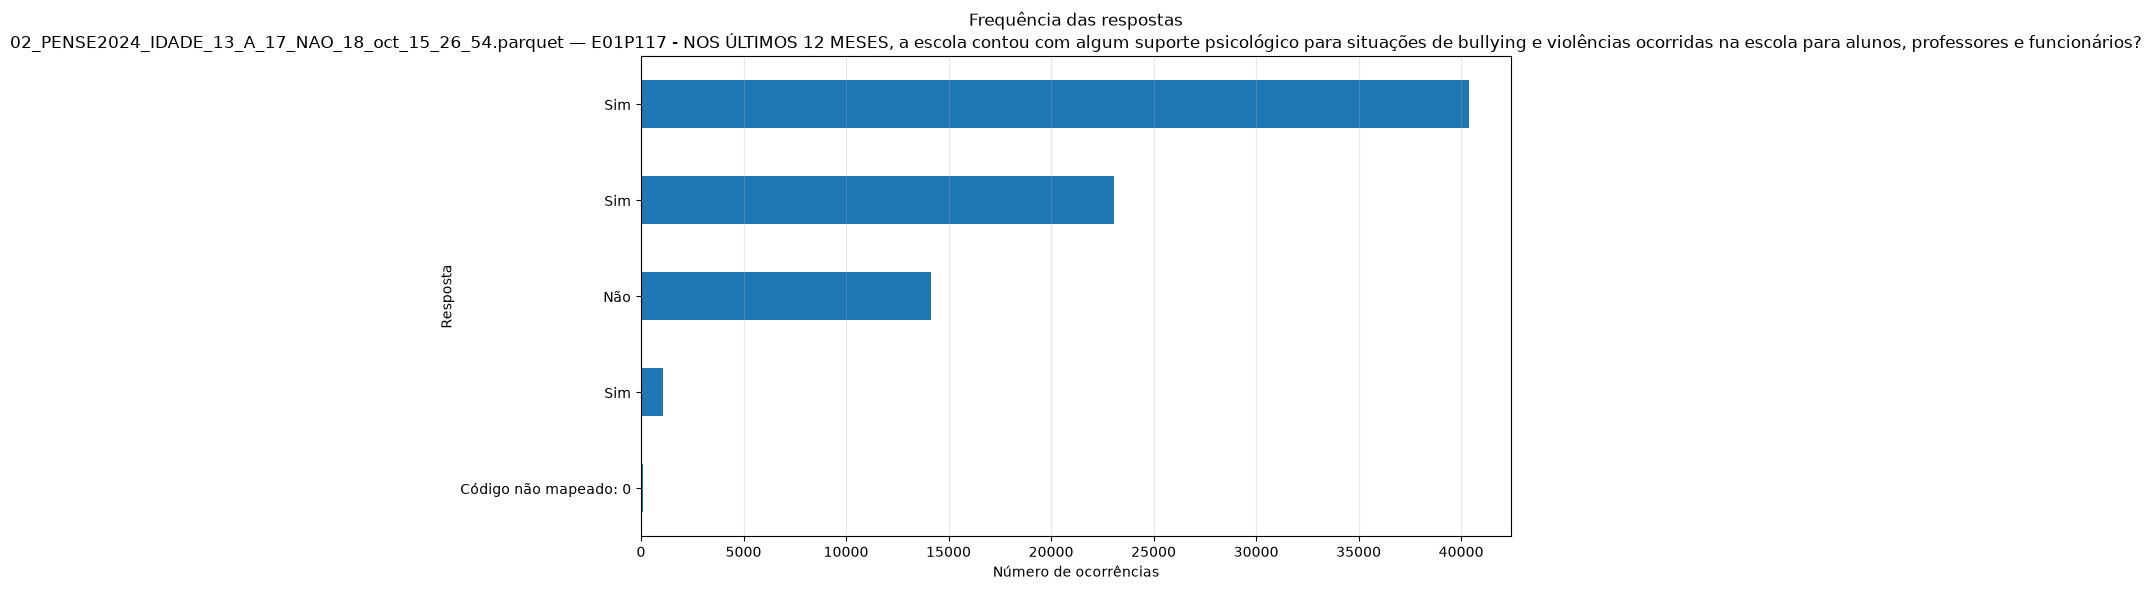


--------------------------------------------------------------------------------
Coluna: E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental

Tabela de frequências:


,frequencia,percentual
Nao,32944,41.81
Sim,31218,39.62
Sem resposta,14627,18.56


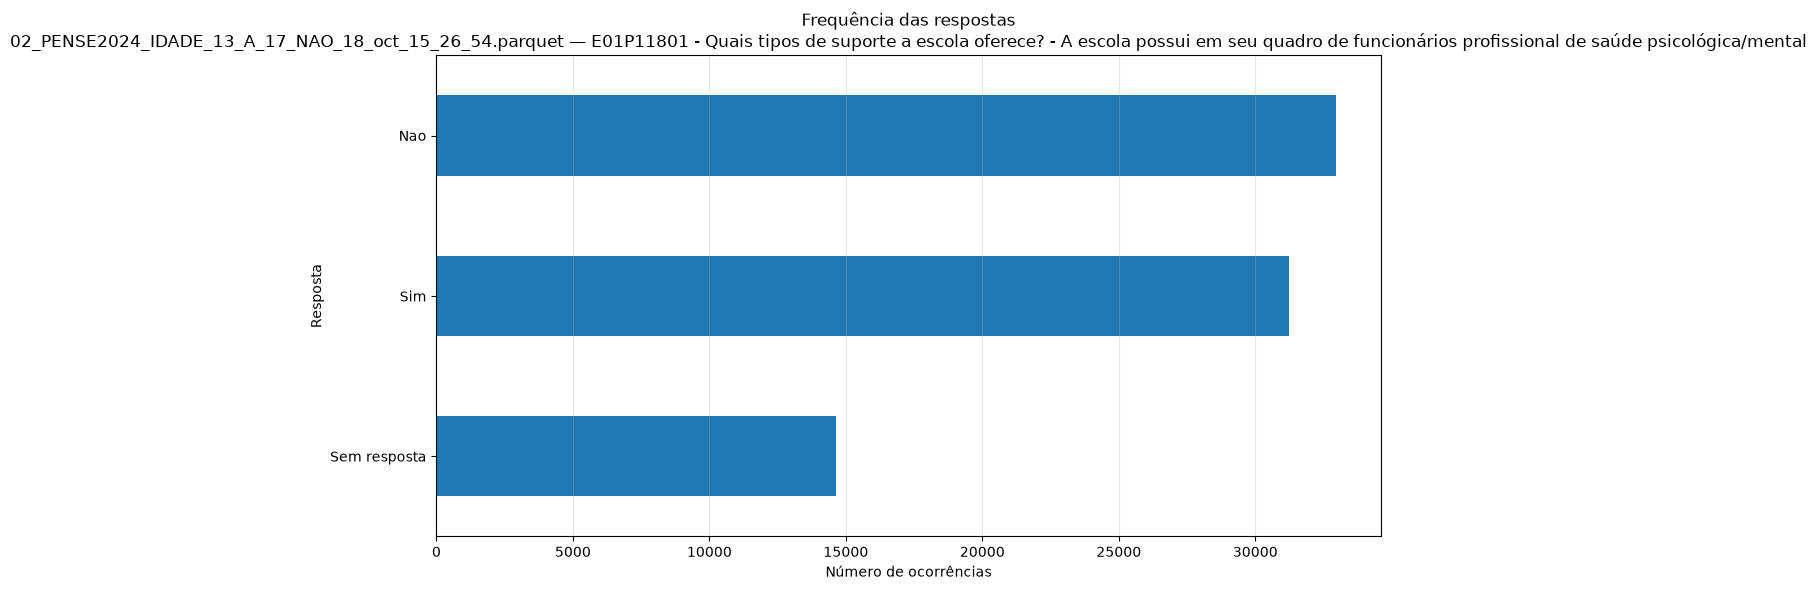


--------------------------------------------------------------------------------
Coluna: E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental

Tabela de frequências:


,frequencia,percentual
Nao,52350,66.44
Sem resposta,14627,18.56
Sim,11812,14.99


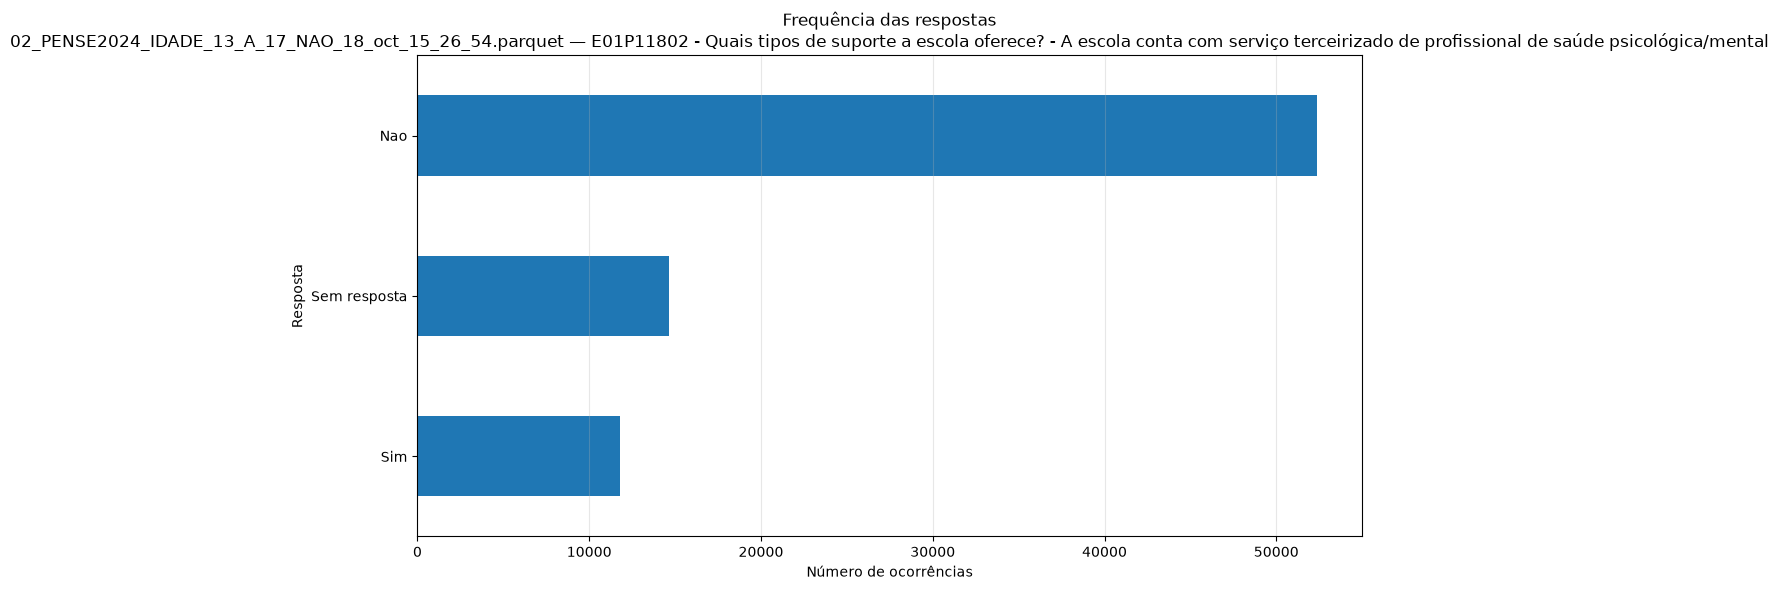


[15] MATRIZ DE CORRELAÇÃO NUMÉRICA


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
REGIAO - código de regiões,1.000,0.984,0.047,-0.002,-0.021,-0.176,0.042,0.041,0.168,0.078,...,-0.019,-0.001,0.003,-0.016,-0.019,0.036,0.007,0.030,-0.061,0.019
UF - código UF,0.984,1.000,0.047,-0.001,-0.022,-0.172,0.044,0.038,0.161,0.081,...,-0.020,0.000,0.004,-0.018,-0.021,0.027,0.003,0.028,-0.050,0.023
CAPITAL - indica se é município da capital,0.047,0.047,1.000,-0.008,0.012,-0.078,0.004,-0.025,0.139,0.064,...,-0.007,0.021,0.024,0.015,-0.005,0.037,0.023,-0.029,0.065,-0.019
B01001A - Qual é o seu sexo?,-0.002,-0.001,-0.008,1.000,0.013,-0.021,0.029,-0.019,0.005,0.007,...,0.000,-0.038,-0.077,0.131,0.059,-0.004,-0.002,-0.002,0.011,-0.005
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",-0.021,-0.022,0.012,0.013,1.000,-0.014,-0.051,-0.047,-0.017,-0.015,...,-0.017,-0.073,-0.057,0.058,0.032,-0.002,-0.015,-0.030,0.035,-0.004
B01002 - Qual é a sua cor ou raça?,-0.176,-0.172,-0.078,-0.021,-0.014,1.000,-0.042,-0.049,-0.209,-0.083,...,0.032,0.008,-0.009,-0.003,0.013,-0.027,-0.019,0.028,-0.070,-0.029
B01006 - Você mora com sua mãe?,0.042,0.044,0.004,0.029,-0.051,-0.042,1.000,0.116,0.088,0.031,...,-0.021,0.005,-0.009,-0.024,-0.030,0.003,0.009,-0.010,0.026,0.009
B01007 - Você mora com seu pai?,0.041,0.038,-0.025,-0.019,-0.047,-0.049,0.116,1.000,0.169,0.022,...,-0.033,-0.019,-0.002,-0.039,-0.035,0.015,0.019,-0.020,0.050,0.018
B01015B - Na sua casa tem computador ou notebook?,0.168,0.161,0.139,0.005,-0.017,-0.209,0.088,0.169,1.000,0.181,...,-0.071,0.003,0.023,0.001,-0.031,0.060,0.048,-0.089,0.171,0.070
B01016 - Você tem acesso à internet em sua casa?,0.078,0.081,0.064,0.007,-0.015,-0.083,0.031,0.022,0.181,1.000,...,-0.058,-0.017,-0.014,-0.007,-0.023,0.033,0.026,-0.046,0.066,0.038



INSPEÇÃO CONCLUÍDA: 02_PENSE2024_IDADE_13_A_17_NAO_18_oct_15_26_54.parquet


####################################################################################################
INSPEÇÃO DA BASE: 02_PENSE2024_IDADE_13_A_17_SIM_18_oct_15_26_54.parquet
####################################################################################################

[1] DIMENSÕES DA BASE
Número de linhas: 38,561
Número de colunas: 41
Total de células: 1,581,001
Memória utilizada: 13.57 MB

[2] DATAFRAME COMPLETO


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
0,1,11,0,2,2,4,3,3,3,3,...,1,1,1,1,1,3,1,1,3,1
1,1,11,0,1,2,4,3,1,1,3,...,1,1,1,1,1,3,1,1,3,1
2,1,11,0,1,2,4,3,3,3,3,...,1,1,1,1,1,3,1,1,3,1
3,1,11,0,2,2,1,3,1,3,3,...,1,3,1,3,3,3,1,1,3,1
4,1,11,0,2,2,4,3,3,3,3,...,1,3,1,1,1,3,1,1,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38556,5,53,1,2,2,1,3,3,3,3,...,1,1,1,1,1,1,1,1,3,3
38557,5,53,1,2,2,4,3,1,3,3,...,1,1,1,1,1,3,3,4,0,0
38558,5,53,1,2,2,1,3,3,3,3,...,1,1,1,1,1,3,3,4,0,0
38559,5,53,1,1,2,4,3,1,1,3,...,1,3,3,3,1,1,1,1,3,3



[3] PRIMEIRAS 5 LINHAS


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
0,1,11,0,2,2,4,3,3,3,3,...,1,1,1,1,1,3,1,1,3,1
1,1,11,0,1,2,4,3,1,1,3,...,1,1,1,1,1,3,1,1,3,1
2,1,11,0,1,2,4,3,3,3,3,...,1,1,1,1,1,3,1,1,3,1
3,1,11,0,2,2,1,3,1,3,3,...,1,3,1,3,3,3,1,1,3,1
4,1,11,0,2,2,4,3,3,3,3,...,1,3,1,1,1,3,1,1,3,1


... (12 outputs left out)

Total de células ausentes: 0

[10] VALORES ÚNICOS POR COLUNA


,valores_unicos,valores_unicos_incluindo_ausentes,percentual_unico
REGIAO - código de regiões,5,5,0.013
UF - código UF,27,27,0.070
CAPITAL - indica se é município da capital,2,2,0.005
B01001A - Qual é o seu sexo?,2,2,0.005
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",2,2,0.005
B01002 - Qual é a sua cor ou raça?,6,6,0.016
B01006 - Você mora com sua mãe?,3,3,0.008
B01007 - Você mora com seu pai?,3,3,0.008
B01015B - Na sua casa tem computador ou notebook?,3,3,0.008
B01016 - Você tem acesso à internet em sua casa?,3,3,0.008



[11] LINHAS DUPLICADAS
Linhas duplicadas: 0
Percentual de duplicatas: 0.000%

[12] COLUNAS CONSTANTES
['B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?']

[13] DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS

[14] DISTRIBUIÇÃO DAS VARIÁVEIS NUMÉRICAS

--------------------------------------------------------------------------------
Coluna: REGIAO - código de regiões

Tabela de frequências:


,frequencia,percentual
nordeste,12724,33.0
norte,9920,25.73
sudeste,6779,17.58
centro-oeste,4966,12.88
sul,4172,10.82


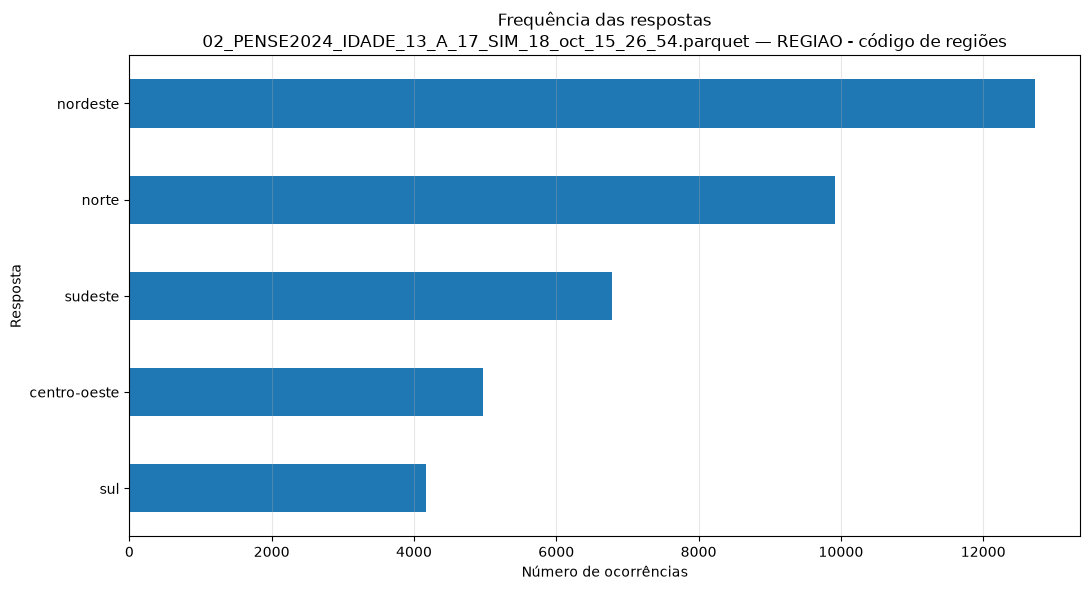


--------------------------------------------------------------------------------
Coluna: UF - código UF

Tabela de frequências:


,frequencia,percentual
Espírito Santo,1787,4.63
Pernambuco,1766,4.58
São Paulo,1761,4.57
Bahia,1726,4.48
Rio de Janeiro,1713,4.44
Amazonas,1576,4.09
Tocantins,1566,4.06
Mato Grosso do Sul,1539,3.99
Rondônia,1535,3.98
Santa Catarina,1534,3.98


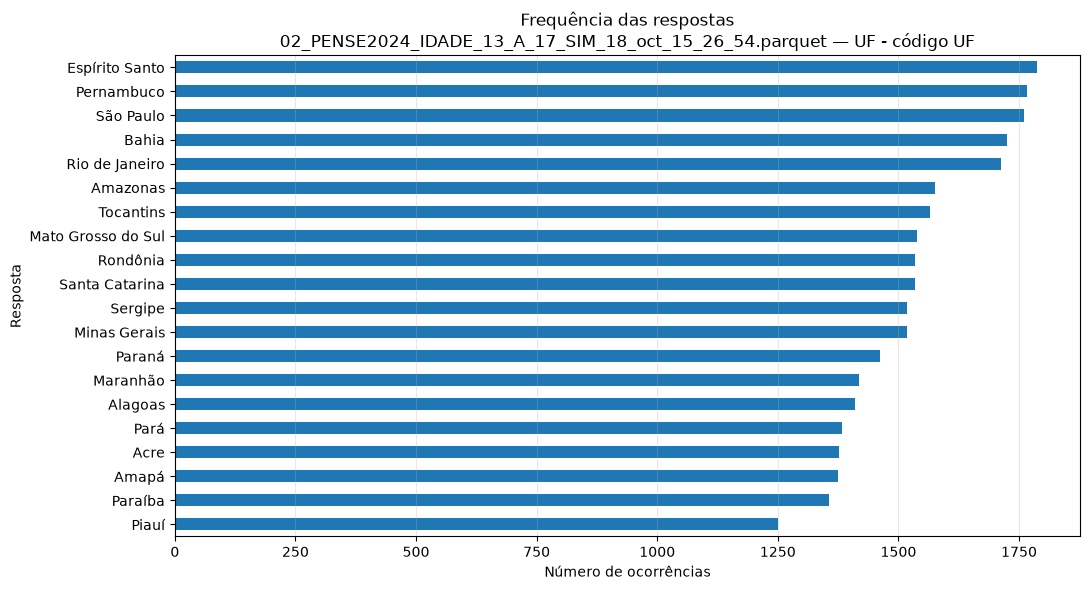


--------------------------------------------------------------------------------
Coluna: CAPITAL - indica se é município da capital

Tabela de frequências:


,frequencia,percentual
Capital,20452,53.04
Código não mapeado: 0,18109,46.96


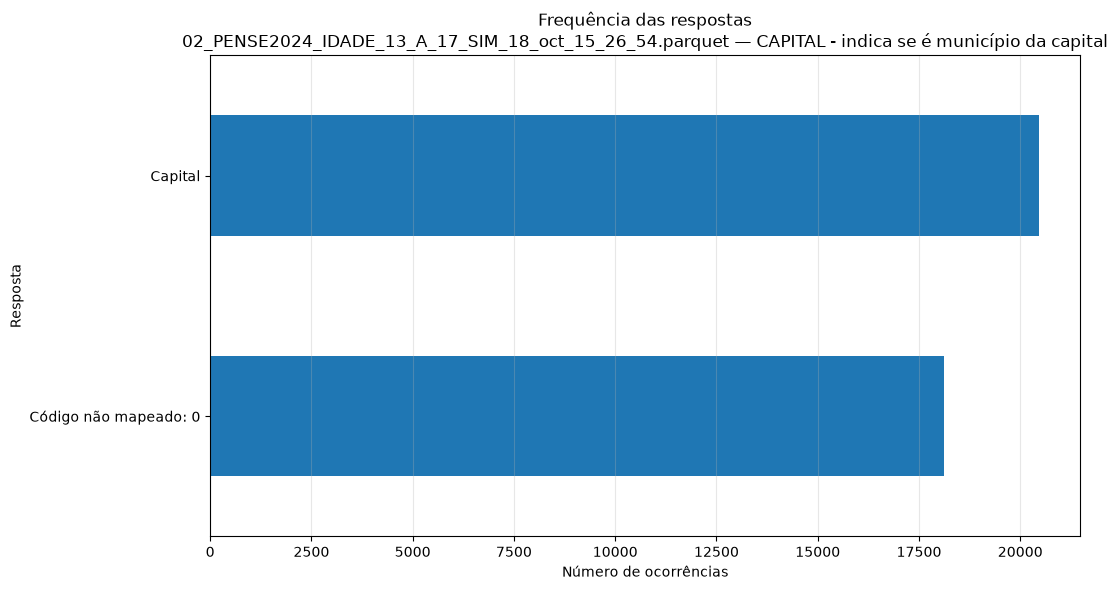


--------------------------------------------------------------------------------
Coluna: B01001A - Qual é o seu sexo?

Tabela de frequências:


,frequencia,percentual
Mulher,25762,66.81
Homem,12799,33.19


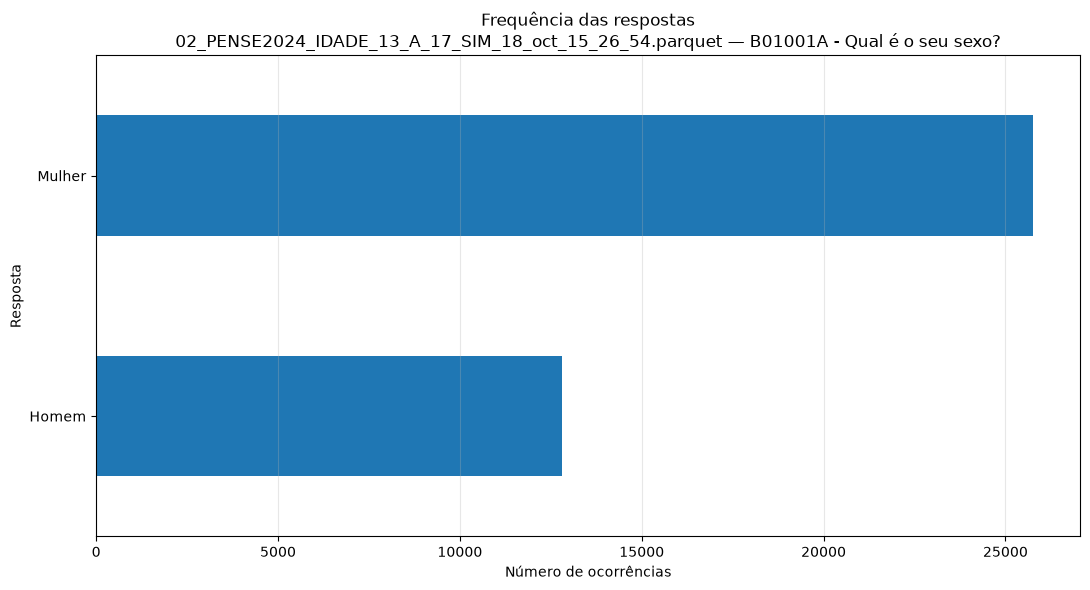


--------------------------------------------------------------------------------
Coluna: IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS

Tabela de frequências:


,frequencia,percentual
13 a 15 anos,25528,66.2
16 e 17 anos,13033,33.8


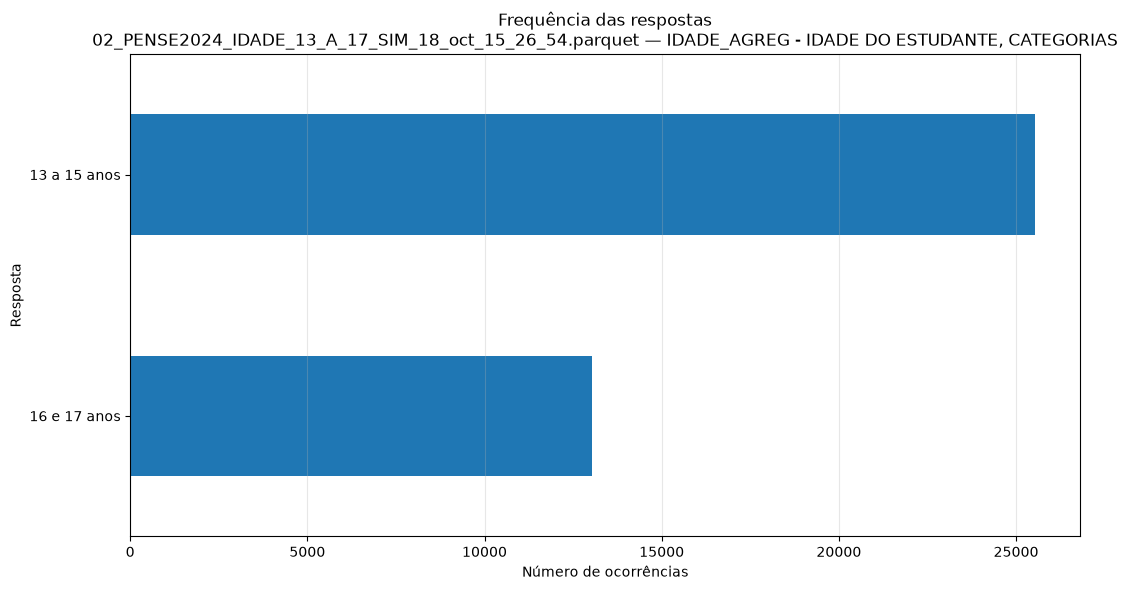


--------------------------------------------------------------------------------
Coluna: B01002 - Qual é a sua cor ou raça?

Tabela de frequências:


,frequencia,percentual
Parda,16663,43.21
Branca,15498,40.19
Preta,4147,10.75
Amarela,1170,3.03
Indígena,892,2.31
Sem reposta,191,0.5


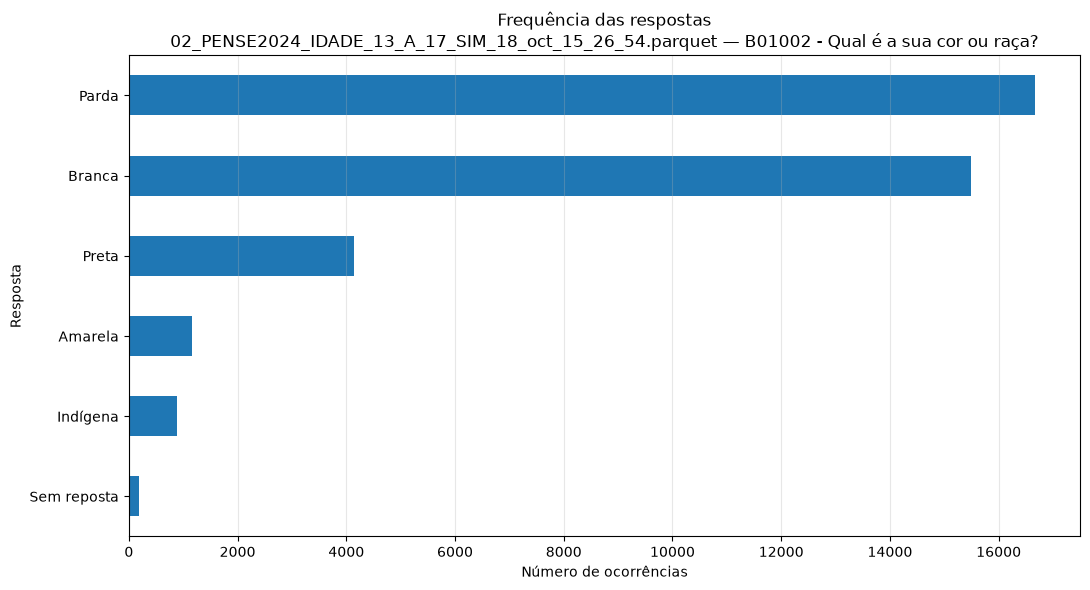


--------------------------------------------------------------------------------
Coluna: B01006 - Você mora com sua mãe?

Tabela de frequências:


,frequencia,percentual
Sim,33882,87.87
Nao,4670,12.11
Sem resposta,9,0.02


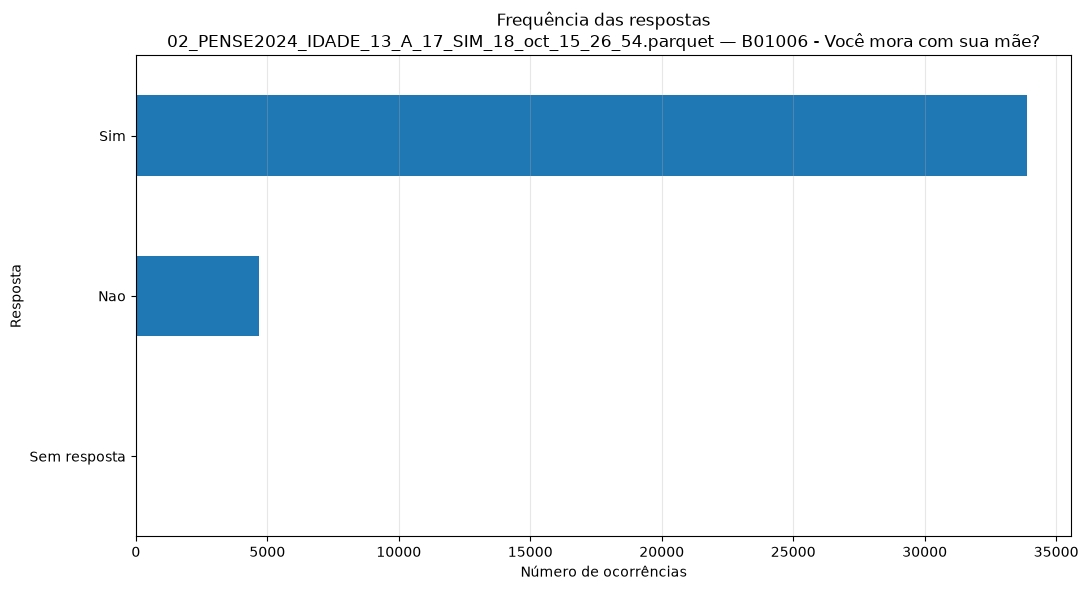


--------------------------------------------------------------------------------
Coluna: B01007 - Você mora com seu pai?

Tabela de frequências:


,frequencia,percentual
Sim,22296,57.82
Nao,16243,42.12
Sem resposta,22,0.06


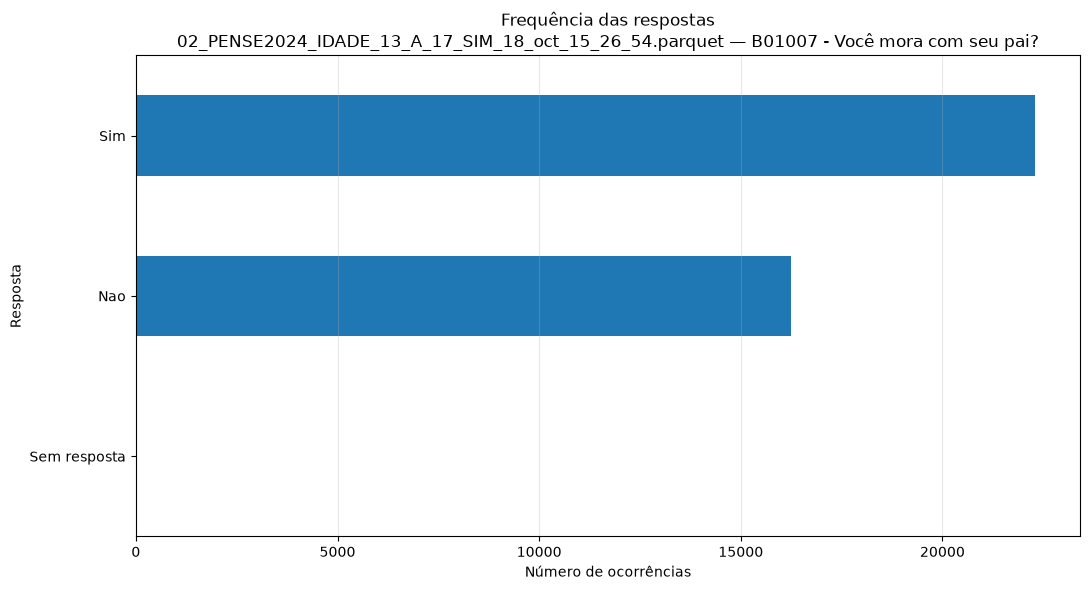


--------------------------------------------------------------------------------
Coluna: B01015B - Na sua casa tem computador ou notebook?

Tabela de frequências:


,frequencia,percentual
Sim,23960,62.14
Nao,14588,37.83
Sem resposta,13,0.03


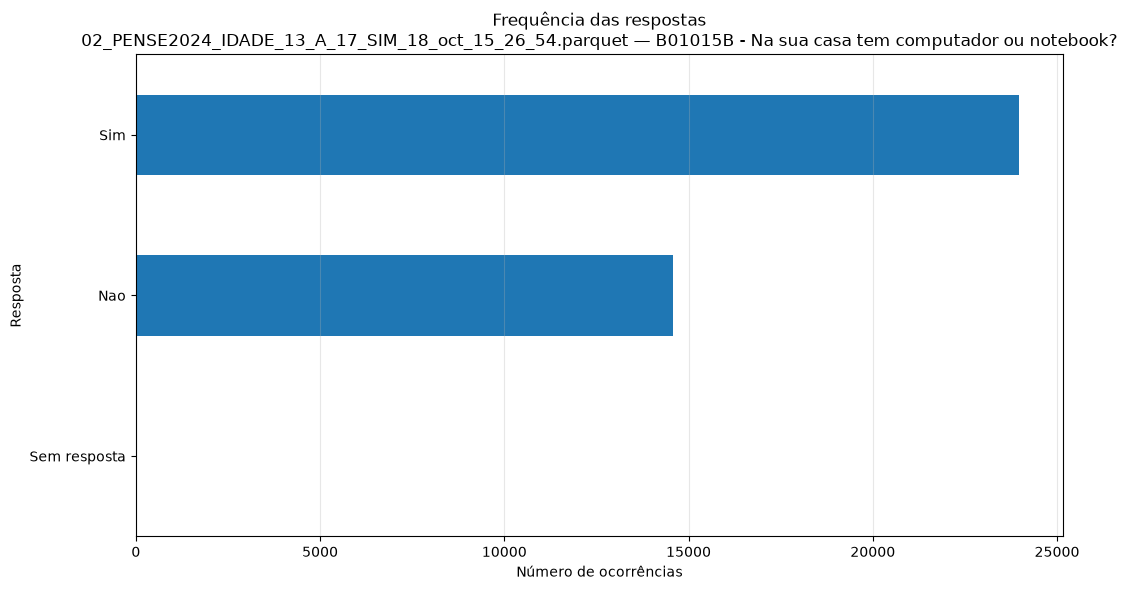


--------------------------------------------------------------------------------
Coluna: B01016 - Você tem acesso à internet em sua casa?

Tabela de frequências:


,frequencia,percentual
Sim,37450,97.12
Nao,1106,2.87
Sem resposta,5,0.01


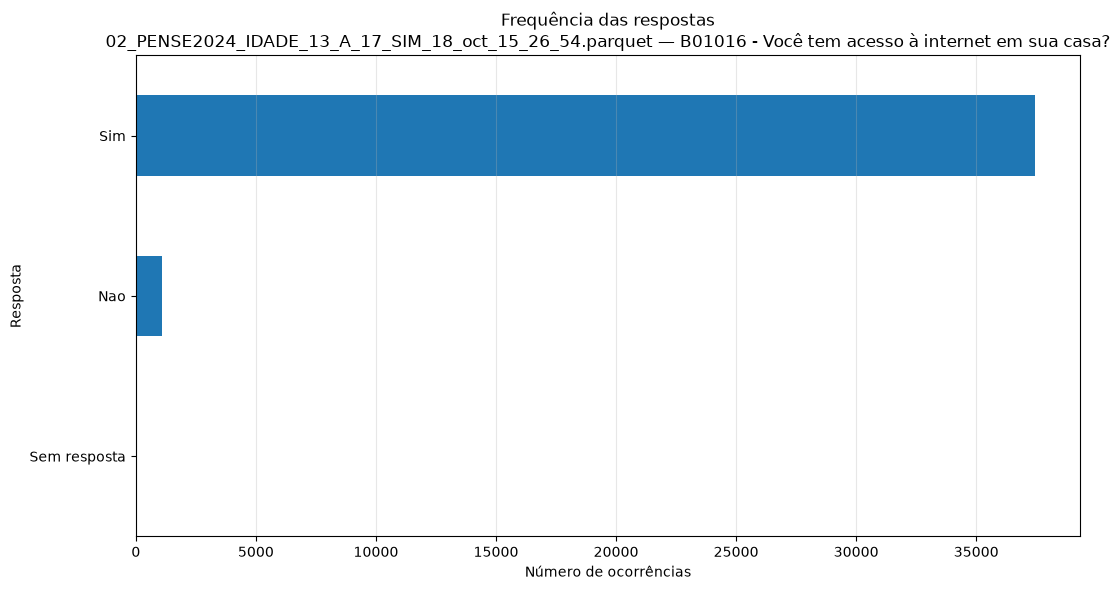


--------------------------------------------------------------------------------
Coluna: B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?

Tabela de frequências:


,frequencia,percentual
Um ou mais dias,25149,65.22
Nenhum dia,13369,34.67
Sem resposta,43,0.11


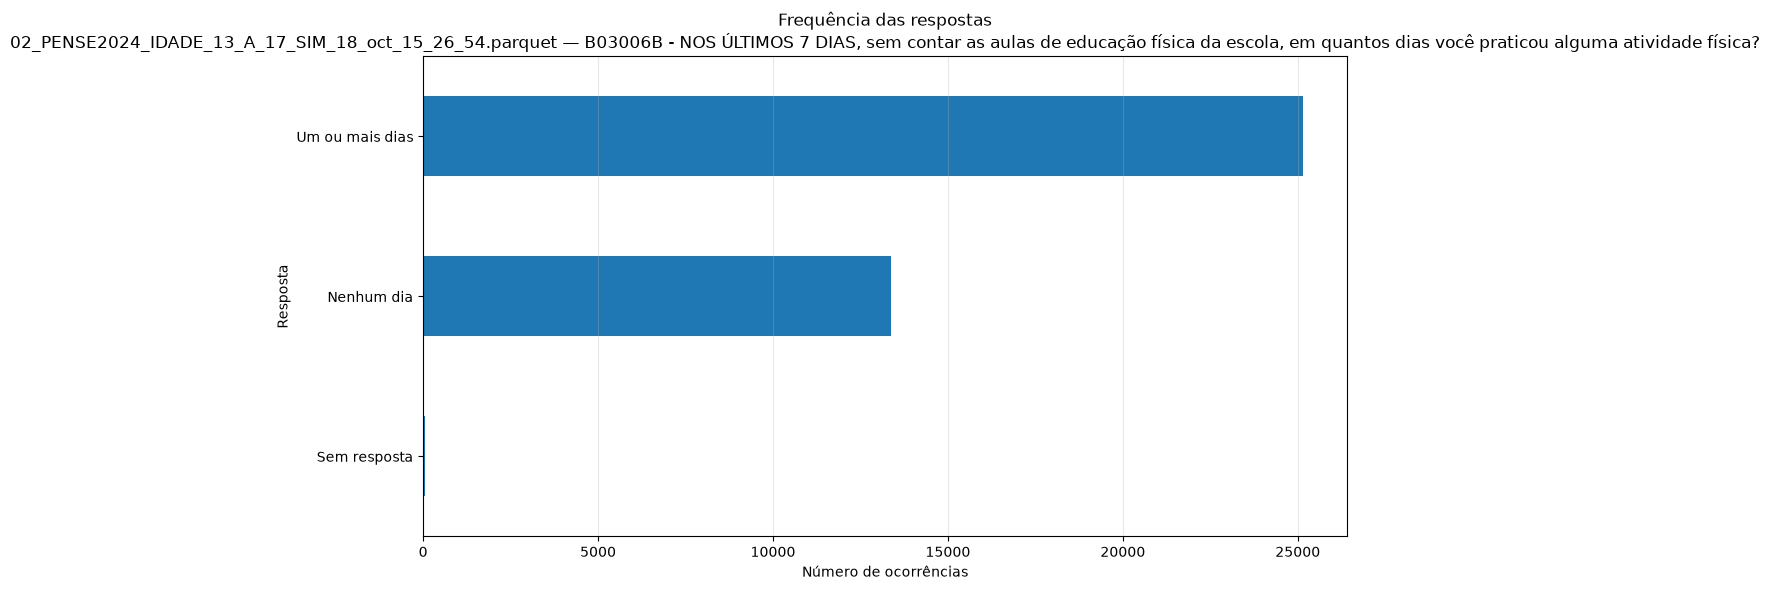


--------------------------------------------------------------------------------
Coluna: B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)

Tabela de frequências:


,frequencia,percentual
Um ou mais horas,30098,78.05
Nenhuma hora,4591,11.91
Sem resposta,3872,10.04


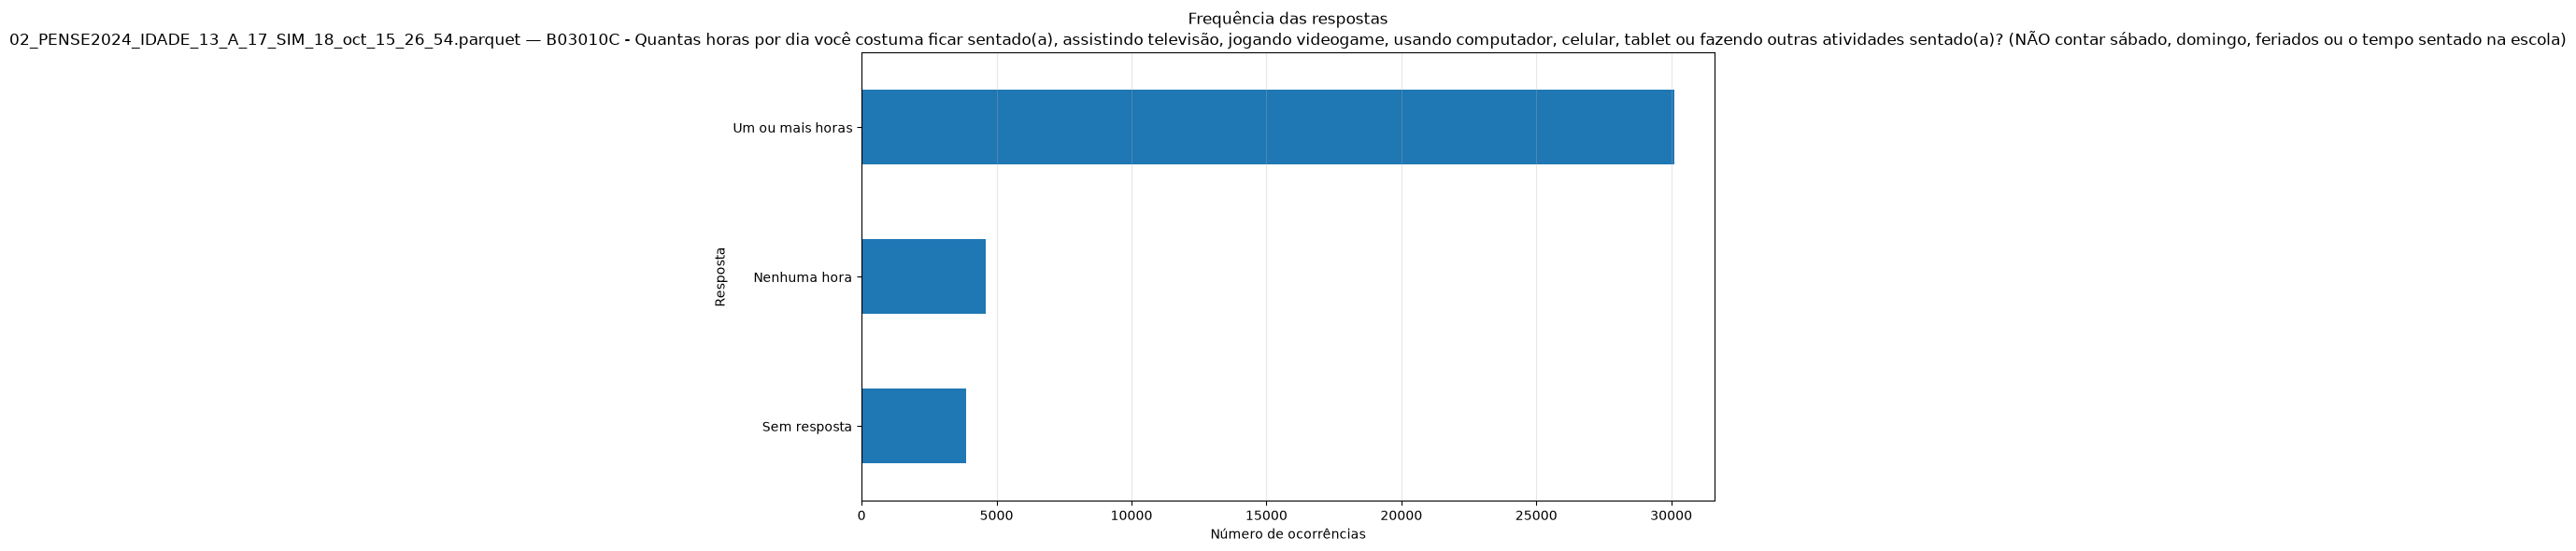


--------------------------------------------------------------------------------
Coluna: B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?

Tabela de frequências:


,frequencia,percentual
Sim,24394,63.26
Nao,14137,36.66
Sem resposta,30,0.08


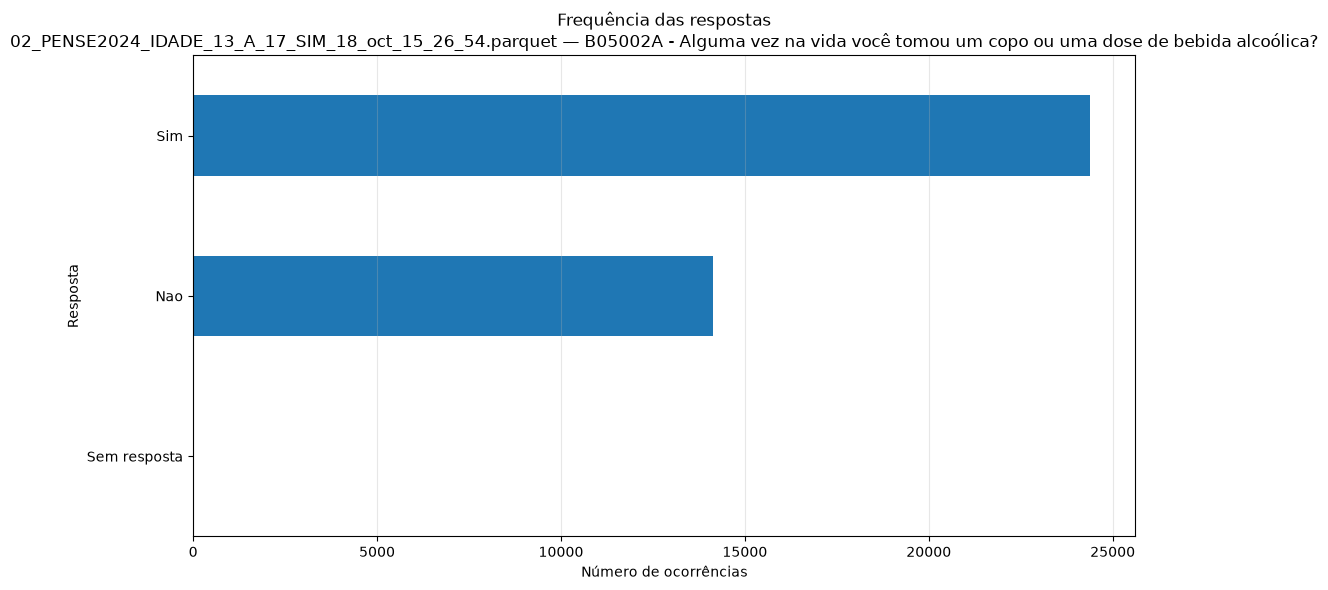


--------------------------------------------------------------------------------
Coluna: B07002 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável sabia realmente o que você estava fazendo em seu tempo livre?

Tabela de frequências:


,frequencia,percentual
Sabia,23309,60.45
Nunca/Raramente,8519,22.09
As vezes,6661,17.27
Sem resposta,72,0.19


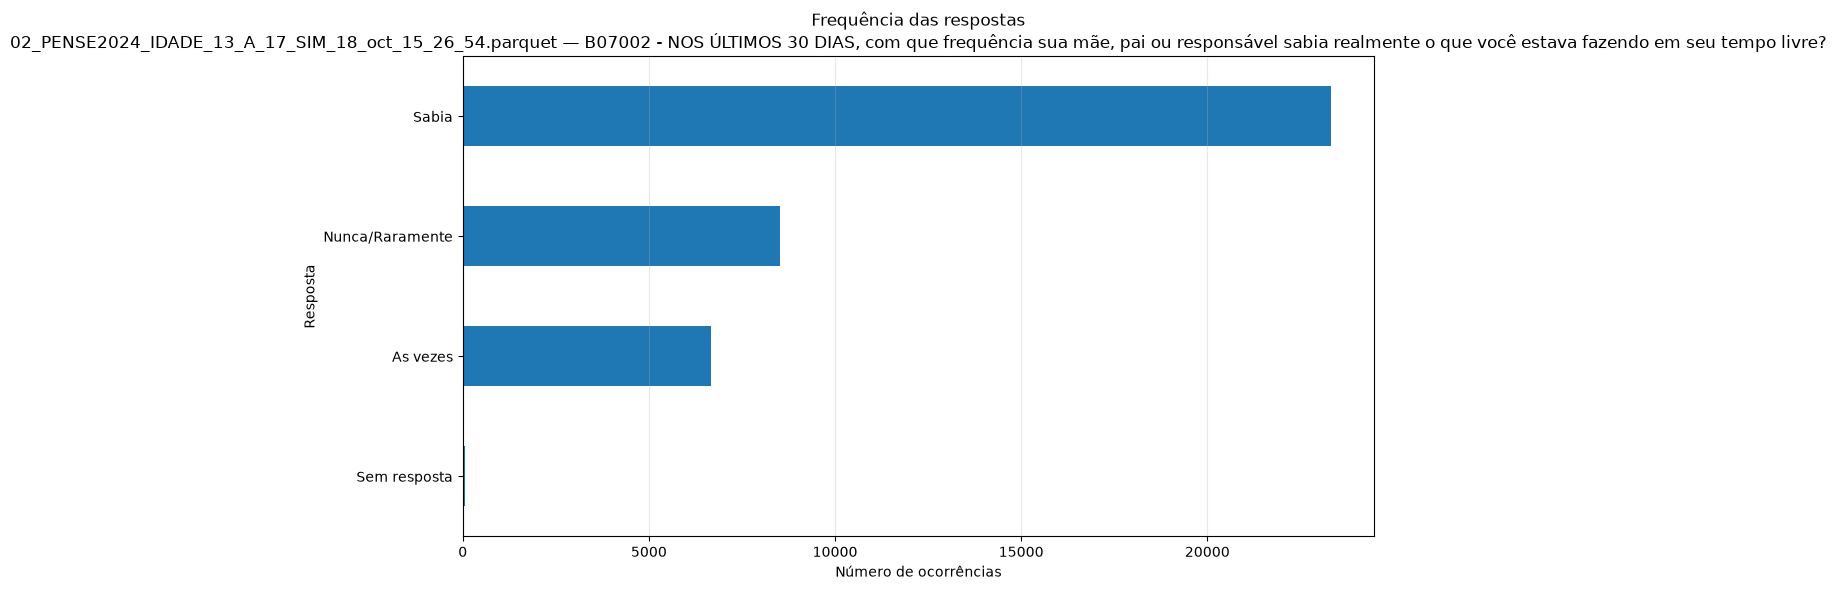


--------------------------------------------------------------------------------
Coluna: B07004 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável entendeu suas preocupações e problemas?

Tabela de frequências:


,frequencia,percentual
Nunca/Raramente,19290,50.02
Entendia,11279,29.25
As vezes,7918,20.53
Sem resposta,74,0.19


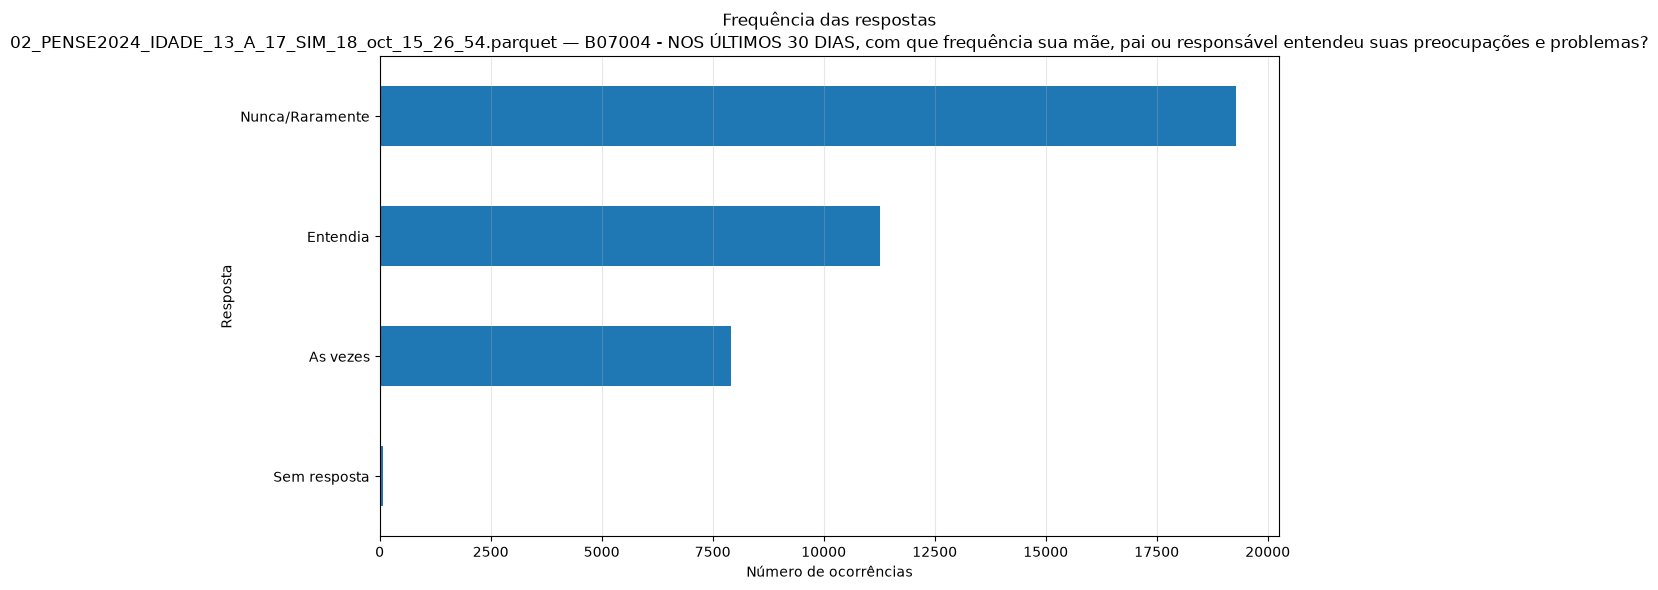


--------------------------------------------------------------------------------
Coluna: B07005 - NOS ÚLTIMOS 30 DIAS, com que frequência seus pais ou responsáveis mexeram em suas coisas sem a sua concordância?

Tabela de frequências:


,frequencia,percentual
Nunca/Raramente,23359,60.58
As vezes,7655,19.85
Sempre,7490,19.42
Sem resposta,57,0.15


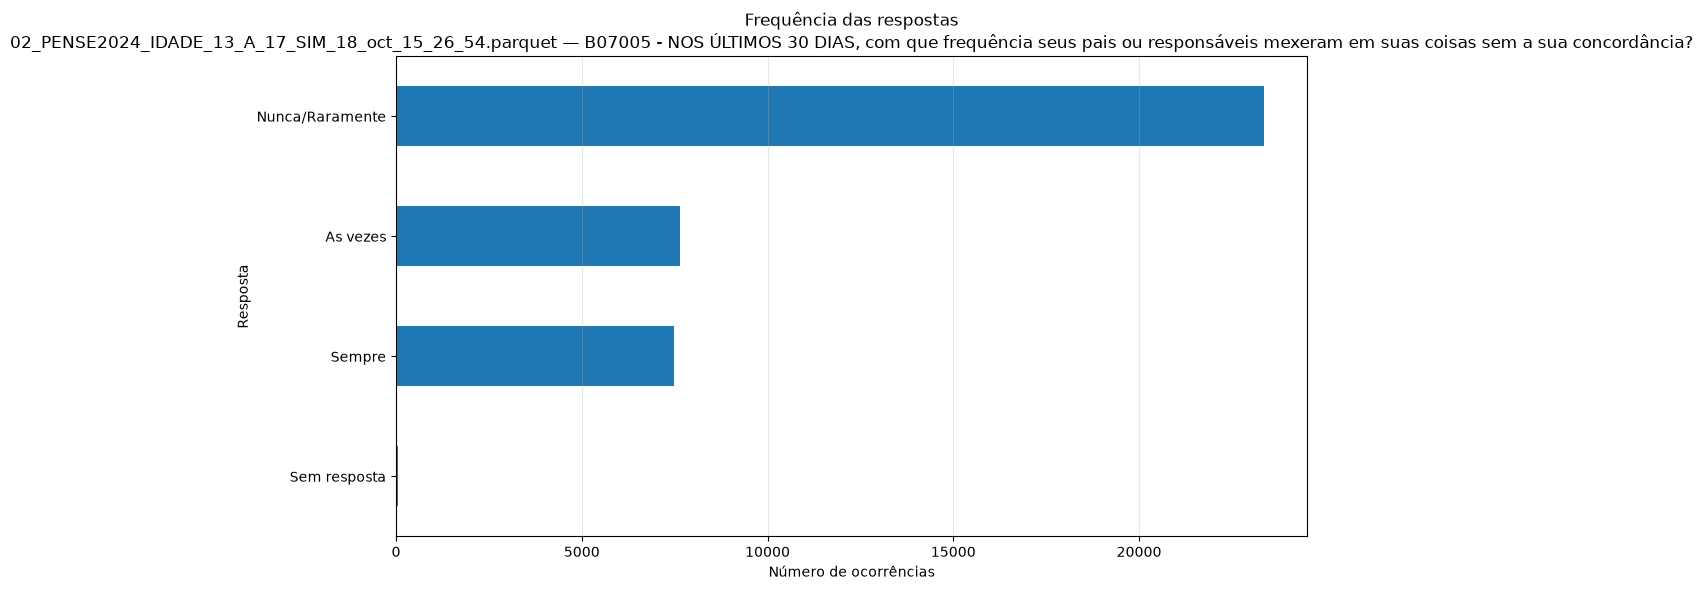


--------------------------------------------------------------------------------
Coluna: B07006 - NOS ÚLTIMOS 30 DIAS, com que frequência os colegas de sua escola trataram você bem e/ou foram prestativos com você?

Tabela de frequências:


,frequencia,percentual
Sim,22740,58.97
As vezes,8389,21.76
Nao,7358,19.08
Sem resposta,74,0.19


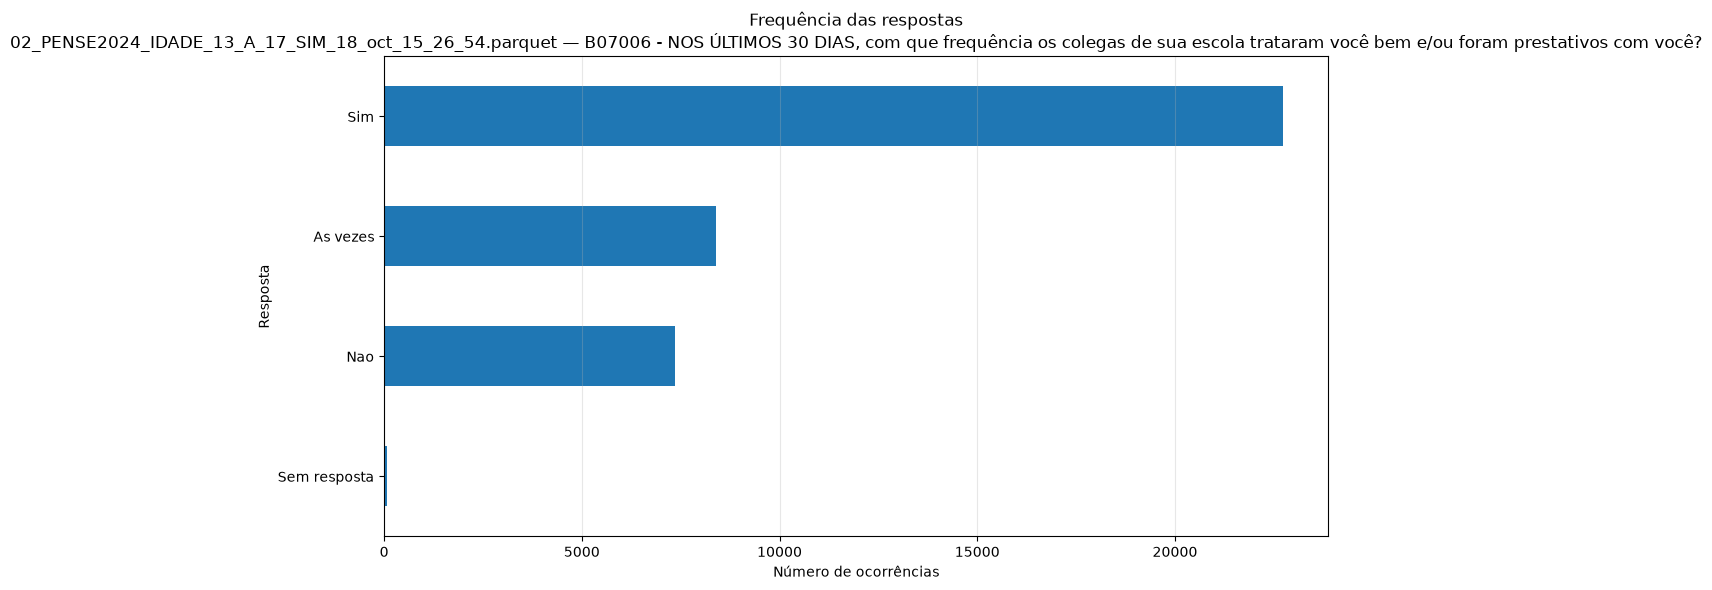


--------------------------------------------------------------------------------
Coluna: B07007B - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola o esculachou, zoou, mangou, intimidou ou caçoou tanto que você ficou magoado, incomodado, aborrecido, ofendido ou humilhado?

Tabela de frequências:


,frequencia,percentual
Uma ou mais vezes,20564,53.33
Nenhuma vez,17914,46.46
Sem resposta,83,0.22


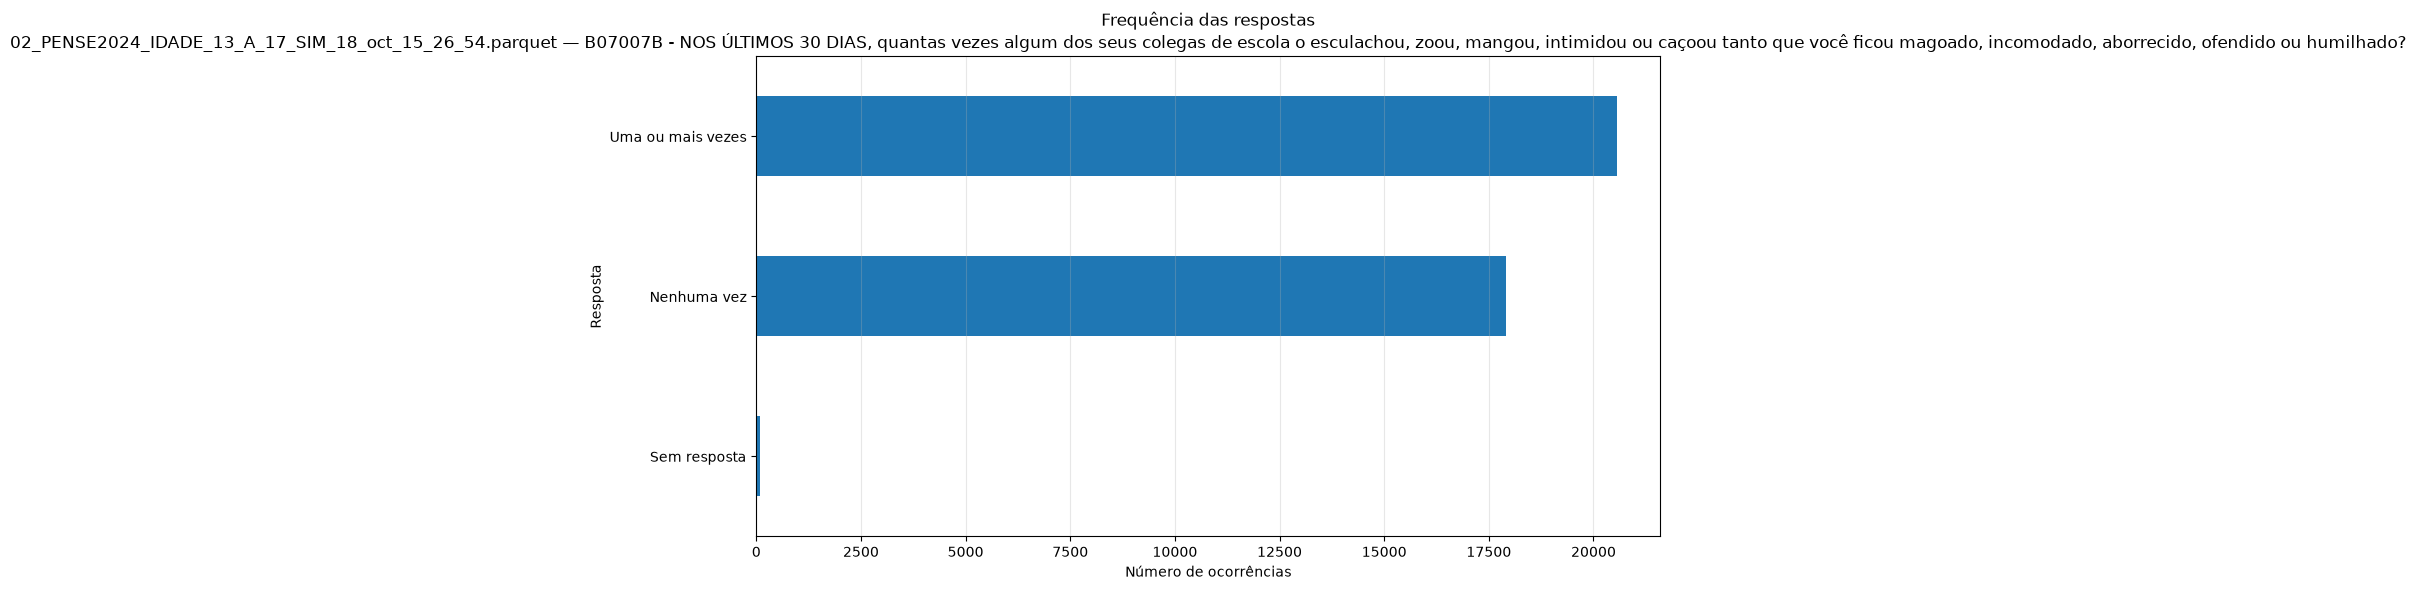


--------------------------------------------------------------------------------
Coluna: B07011A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola se recusou a falar com você, deixou você de lado sem razão ou fez com que outros colegas deixassem de falar com você?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,23887,61.95
Uma ou mais vezes,14585,37.82
Sem resposta,89,0.23


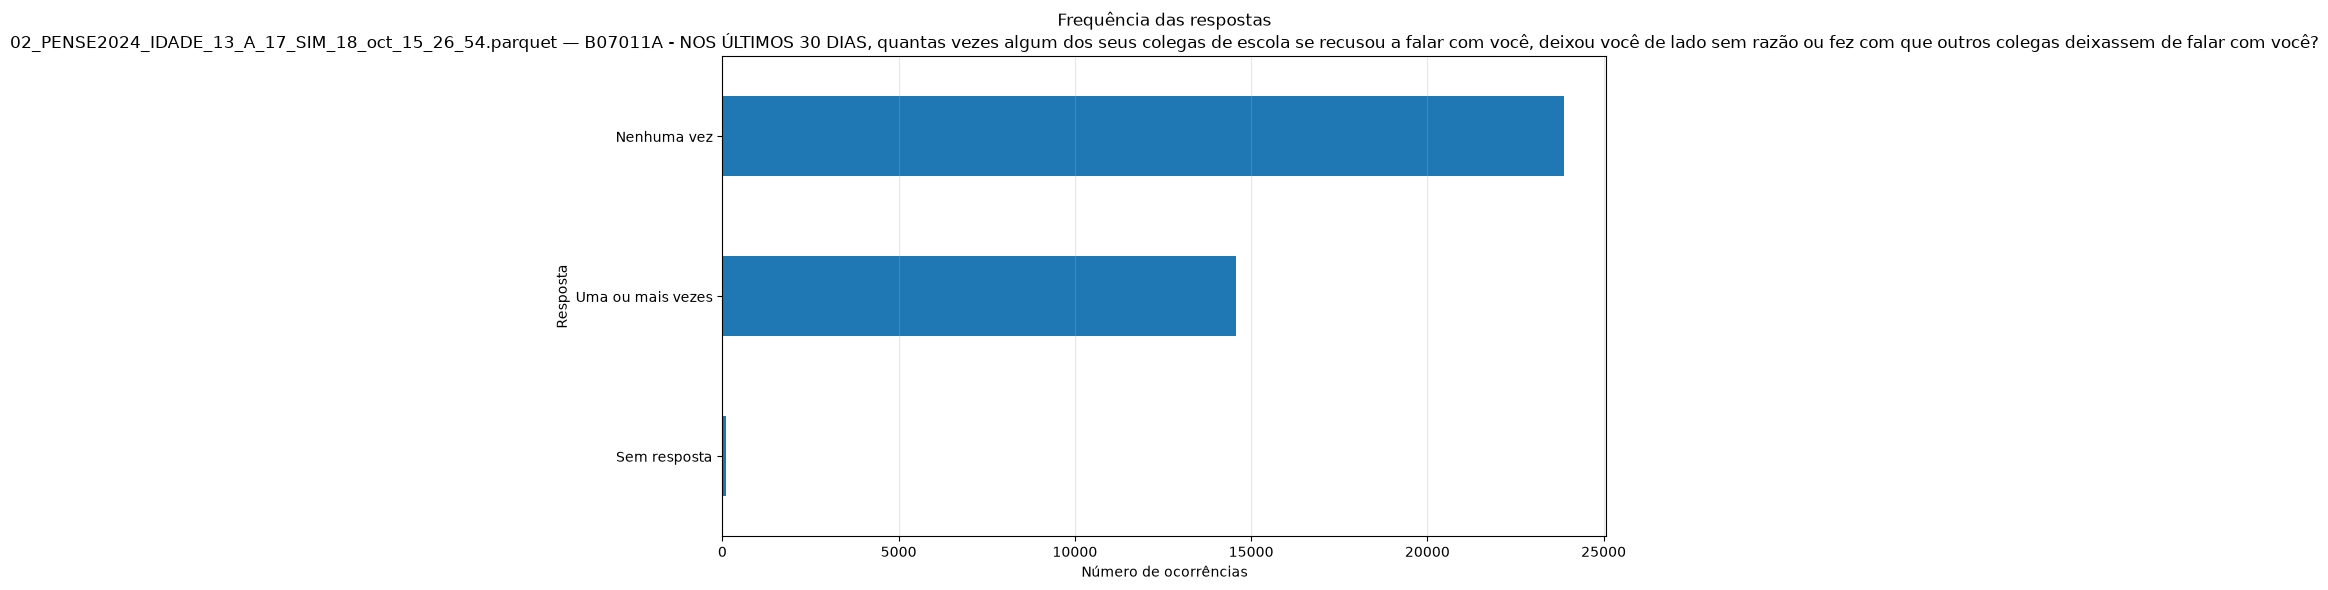


--------------------------------------------------------------------------------
Coluna: B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola bateu (deu socos, tapas, chutes, pontapés) em você ou o machucou fisicamente de outra forma?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,29614,76.8
Uma ou mais vezes,8867,22.99
Sem resposta,80,0.21


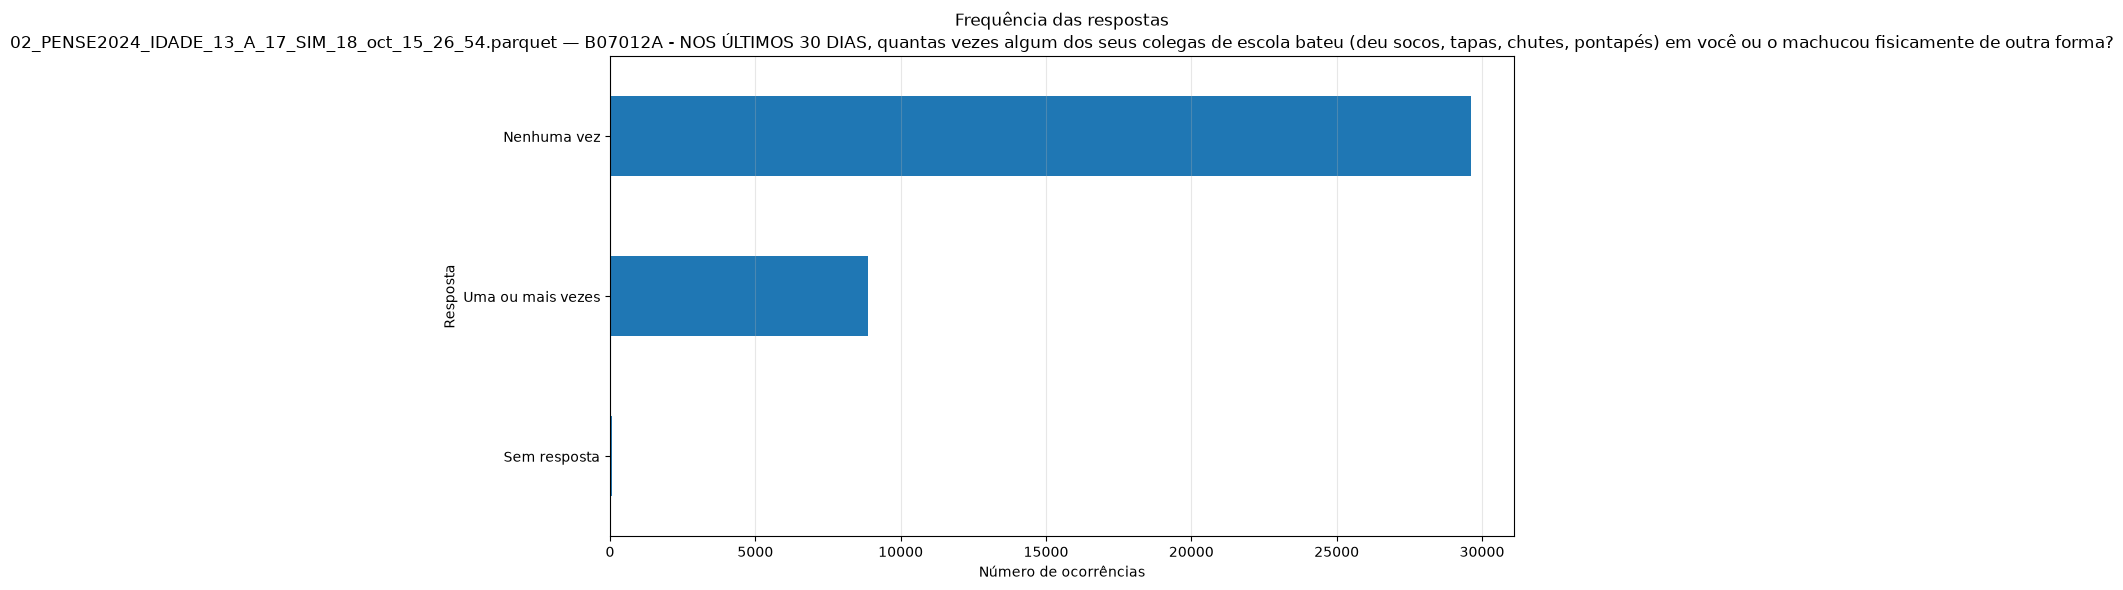


--------------------------------------------------------------------------------
Coluna: B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?

Tabela de frequências:


,frequencia,percentual
Nao,30154,78.2
Sim,8353,21.66
Sem resposta,54,0.14


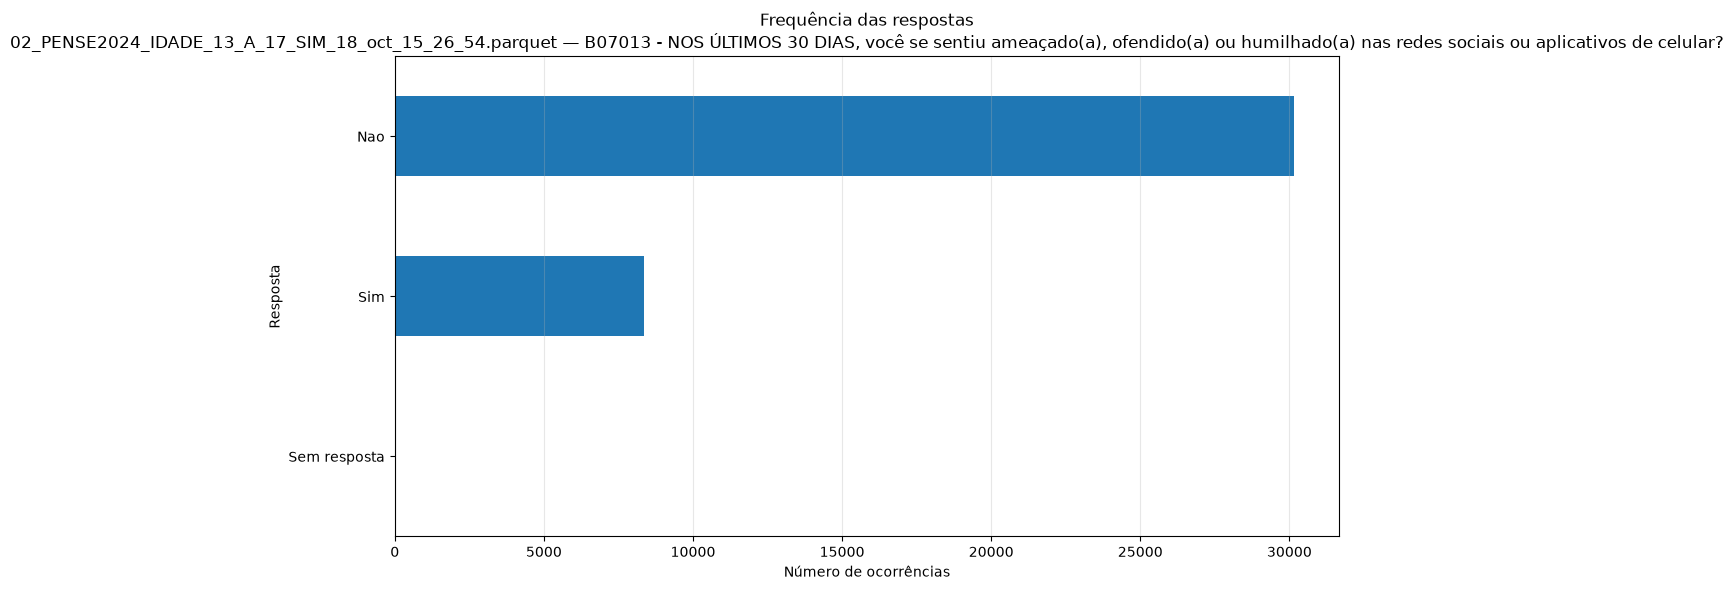


--------------------------------------------------------------------------------
Coluna: B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?

Tabela de frequências:


,frequencia,percentual
Nao,31680,82.16
Sim,6806,17.65
Sem resposta,75,0.19


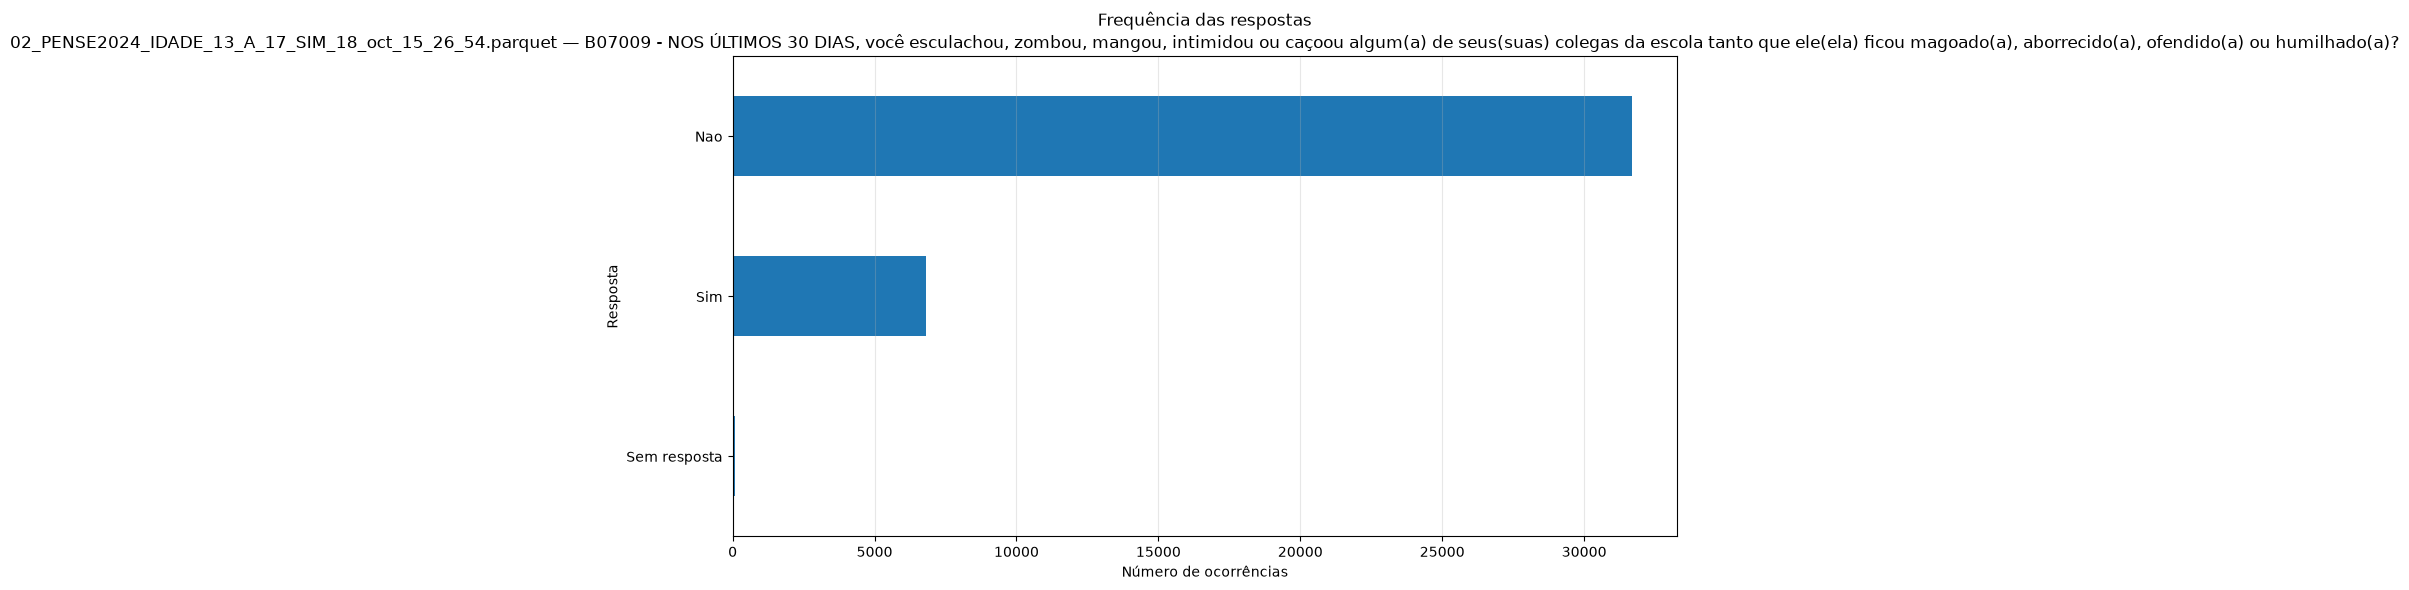


--------------------------------------------------------------------------------
Coluna: B07016 - NOS ÚLTIMOS 30 DIAS, você ameaçou, ofendeu ou humilhou outras pessoas nas redes sociais ou aplicativos de celular?

Tabela de frequências:


,frequencia,percentual
Nao,32526,84.35
Sim,5962,15.46
Sem resposta,73,0.19


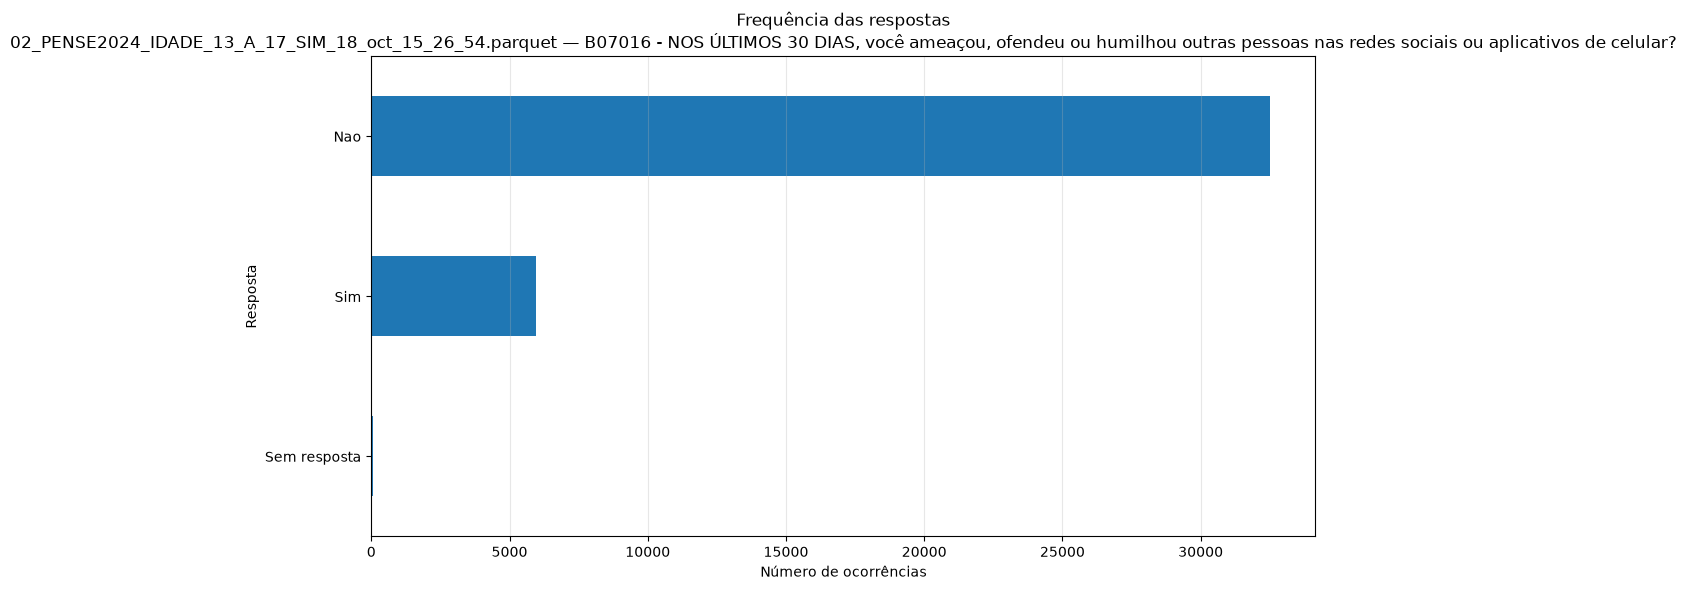


--------------------------------------------------------------------------------
Coluna: B12003 - Quantos(as) amigos(as) próximos você tem?

Tabela de frequências:


,frequencia,percentual
Mais que um,36461,94.55
Nenhum,2060,5.34
Sem resposta,40,0.1


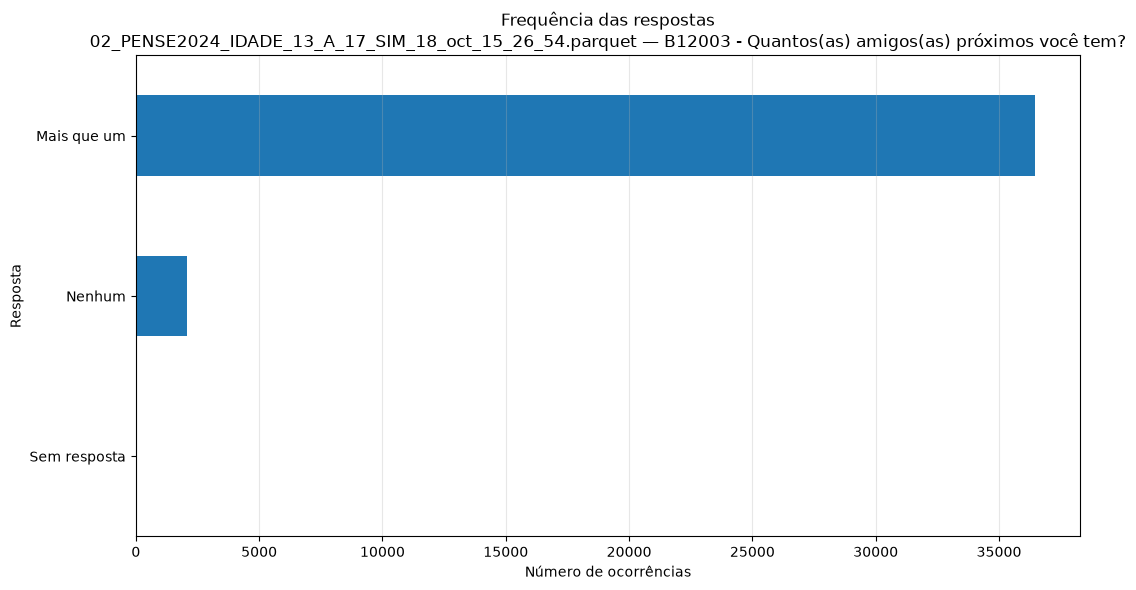


--------------------------------------------------------------------------------
Coluna: B12004 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu muito preocupado com as coisas comuns do seu dia a dia como atividades da escola, competições esportivas, tarefas de casa, etc.?

Tabela de frequências:


,frequencia,percentual
Sempre,25127,65.16
As vezes,7461,19.35
Nunca/Raramente,5894,15.28
Sem resposta,79,0.2


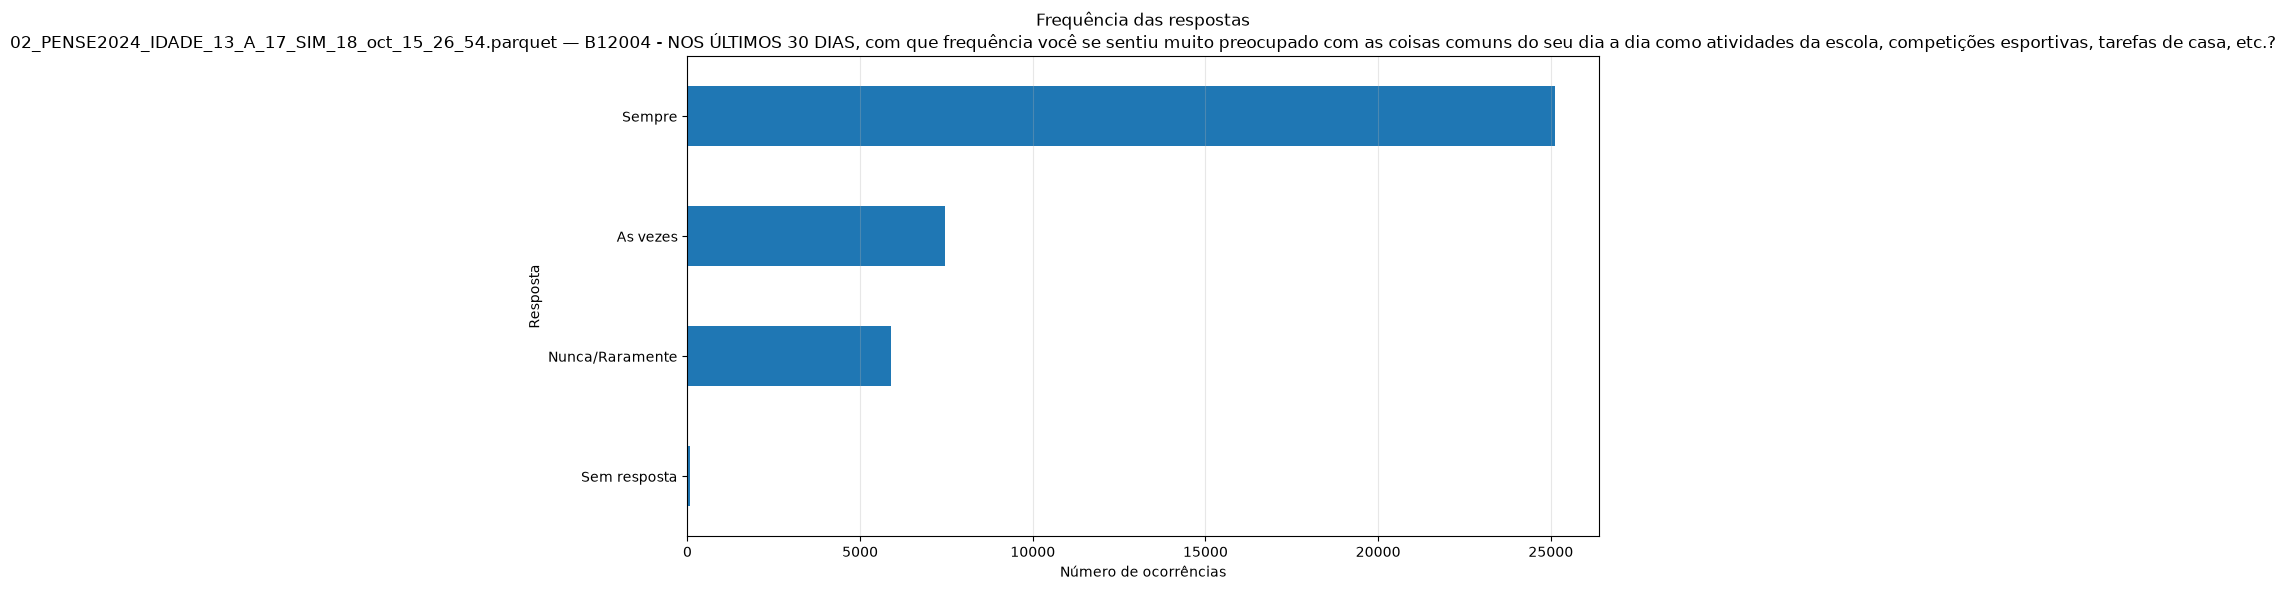


--------------------------------------------------------------------------------
Coluna: B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?

Tabela de frequências:


,frequencia,percentual
Sempre,20783,53.9
As vezes,12701,32.94
Nunca/Raramente,5038,13.07
Sem resposta,39,0.1


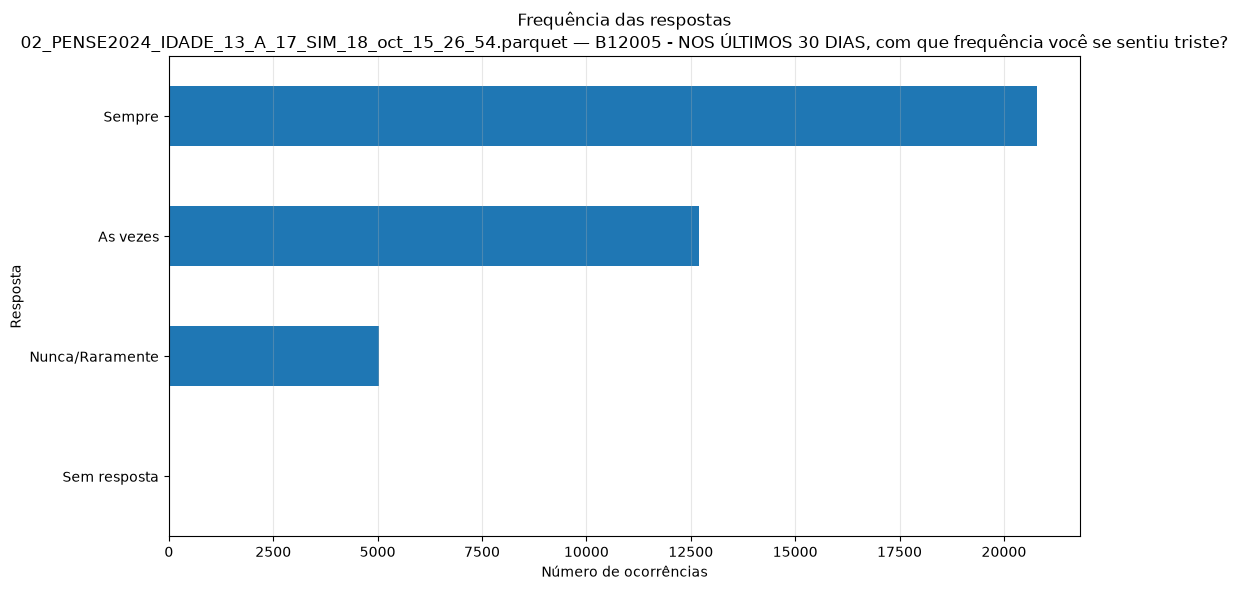


--------------------------------------------------------------------------------
Coluna: B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?

Tabela de frequências:


,frequencia,percentual
Sempre,16792,43.55
As vezes,11024,28.59
Nunca/Raramente,10696,27.74
Sem resposta,49,0.13


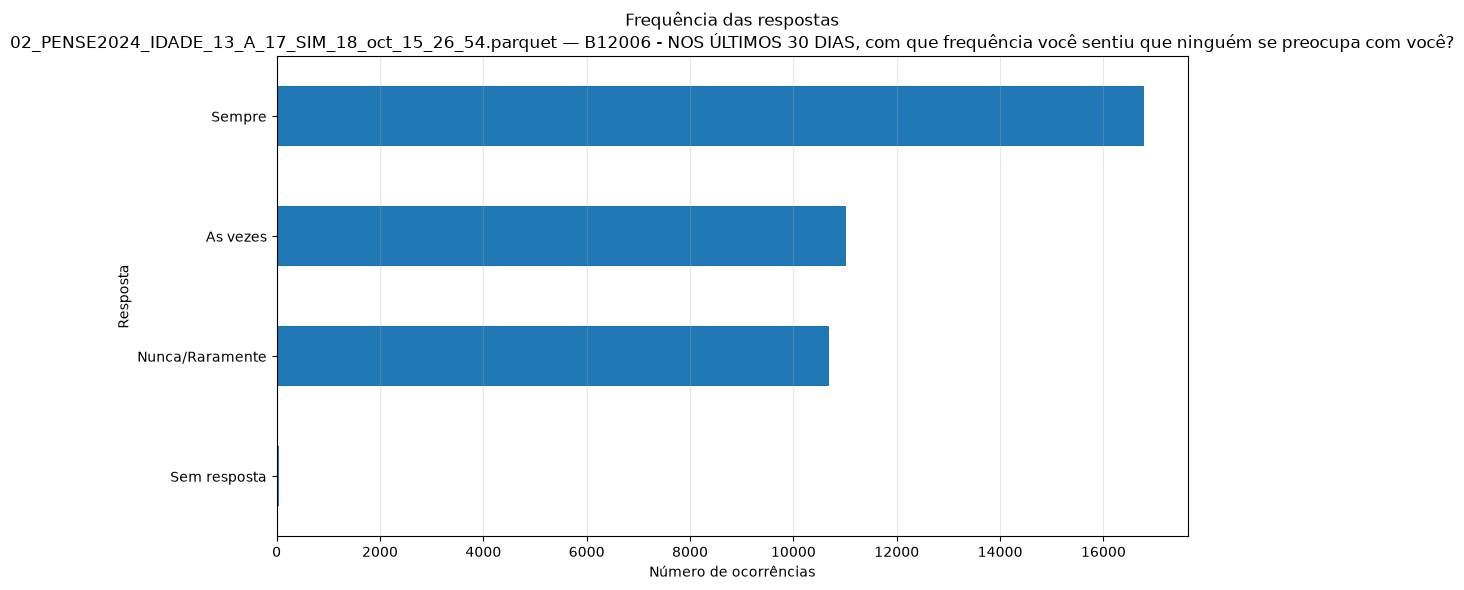


--------------------------------------------------------------------------------
Coluna: B12007 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu irritado(a), nervoso(a) ou mal-humorado(a) por qualquer coisa?

Tabela de frequências:


,frequencia,percentual
Sempre,24074,62.43
As vezes,9561,24.79
Nunca/Raramente,4873,12.64
Sem resposta,53,0.14


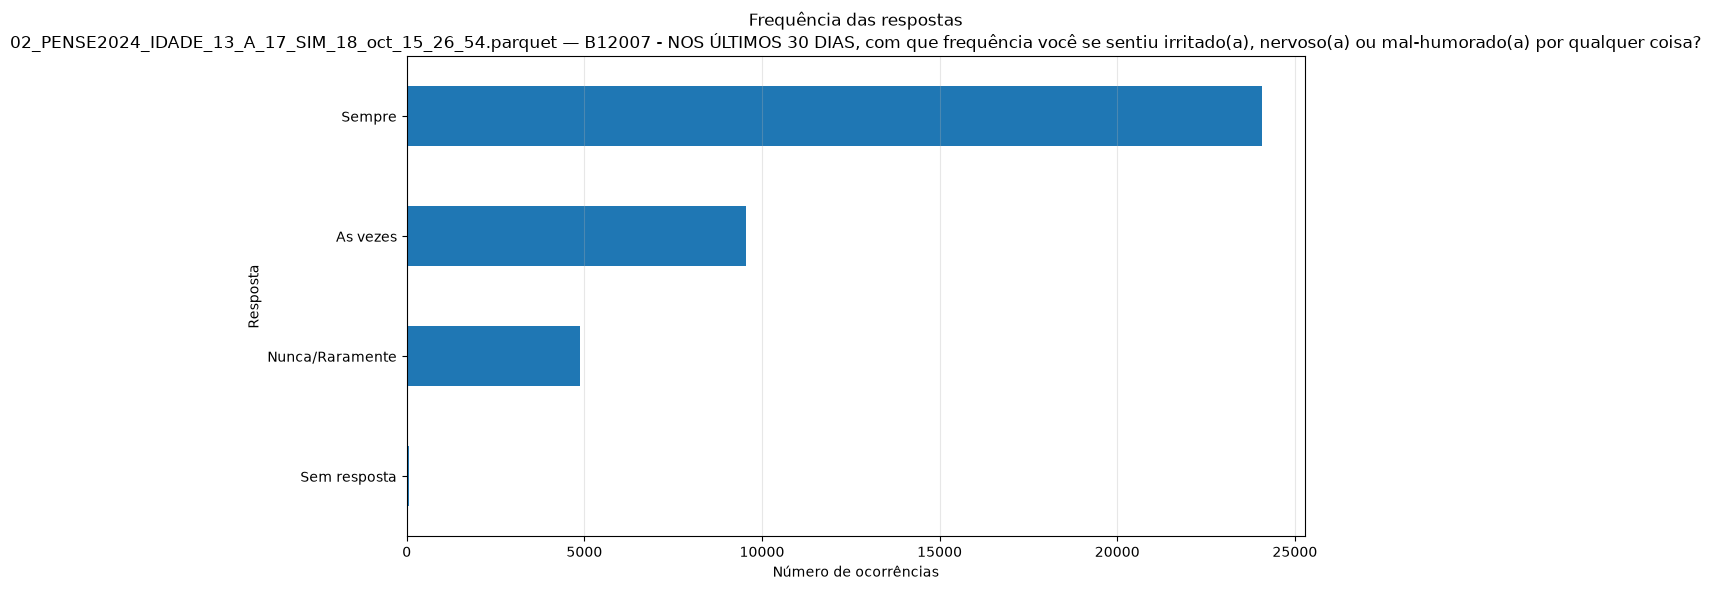


--------------------------------------------------------------------------------
Coluna: B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?

Tabela de frequências:


,frequencia,percentual
Sempre,14775,38.32
Nunca/Raramente,13964,36.21
As vezes,9760,25.31
Sem resposta,62,0.16


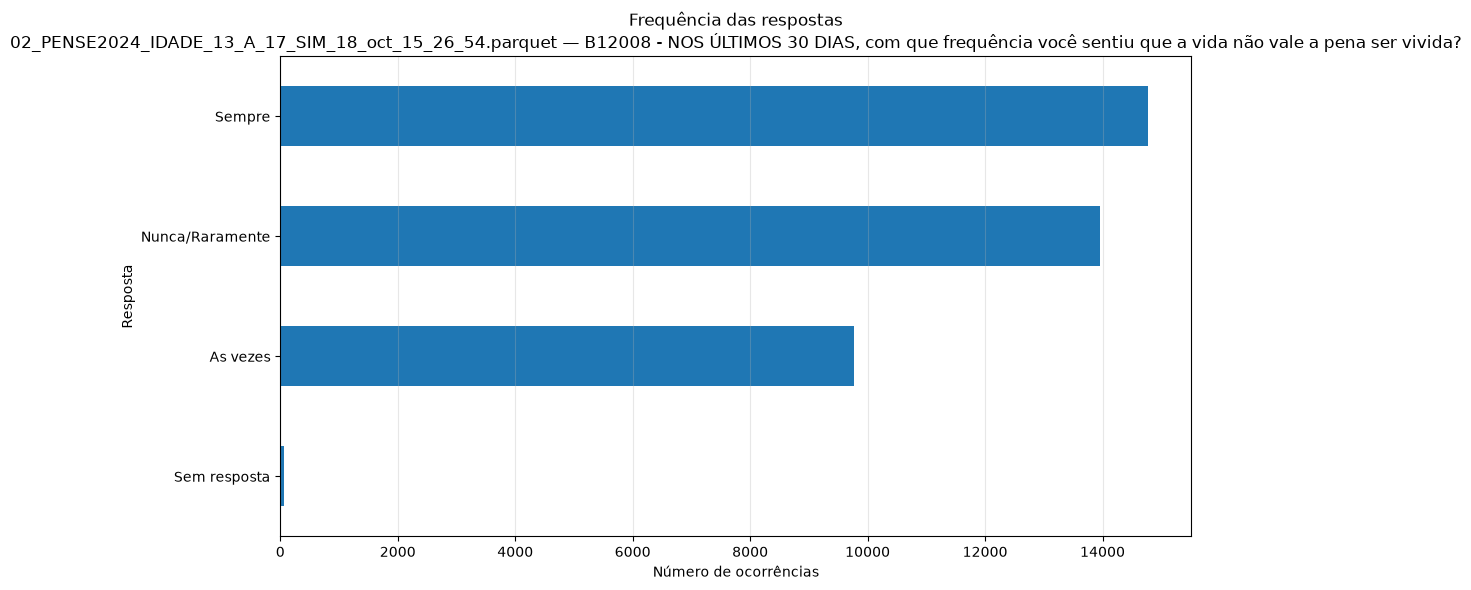


--------------------------------------------------------------------------------
Coluna: B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?

Tabela de frequências:


,frequencia,percentual
Sim,38561,100.0


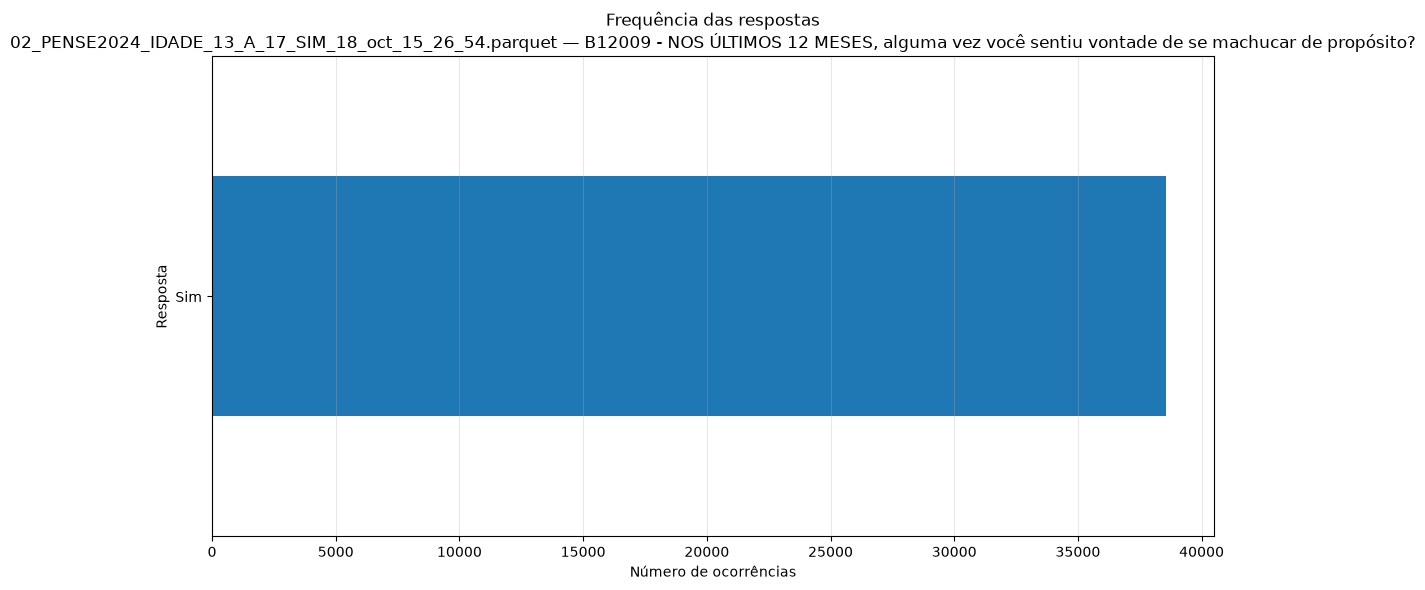


--------------------------------------------------------------------------------
Coluna: B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO de casa para a escola ou da escola para casa?

Tabela de frequências:


,frequencia,percentual
Nenhum dia,33002,85.58
1 ou mais dias,5334,13.83
Sem resposta,225,0.58


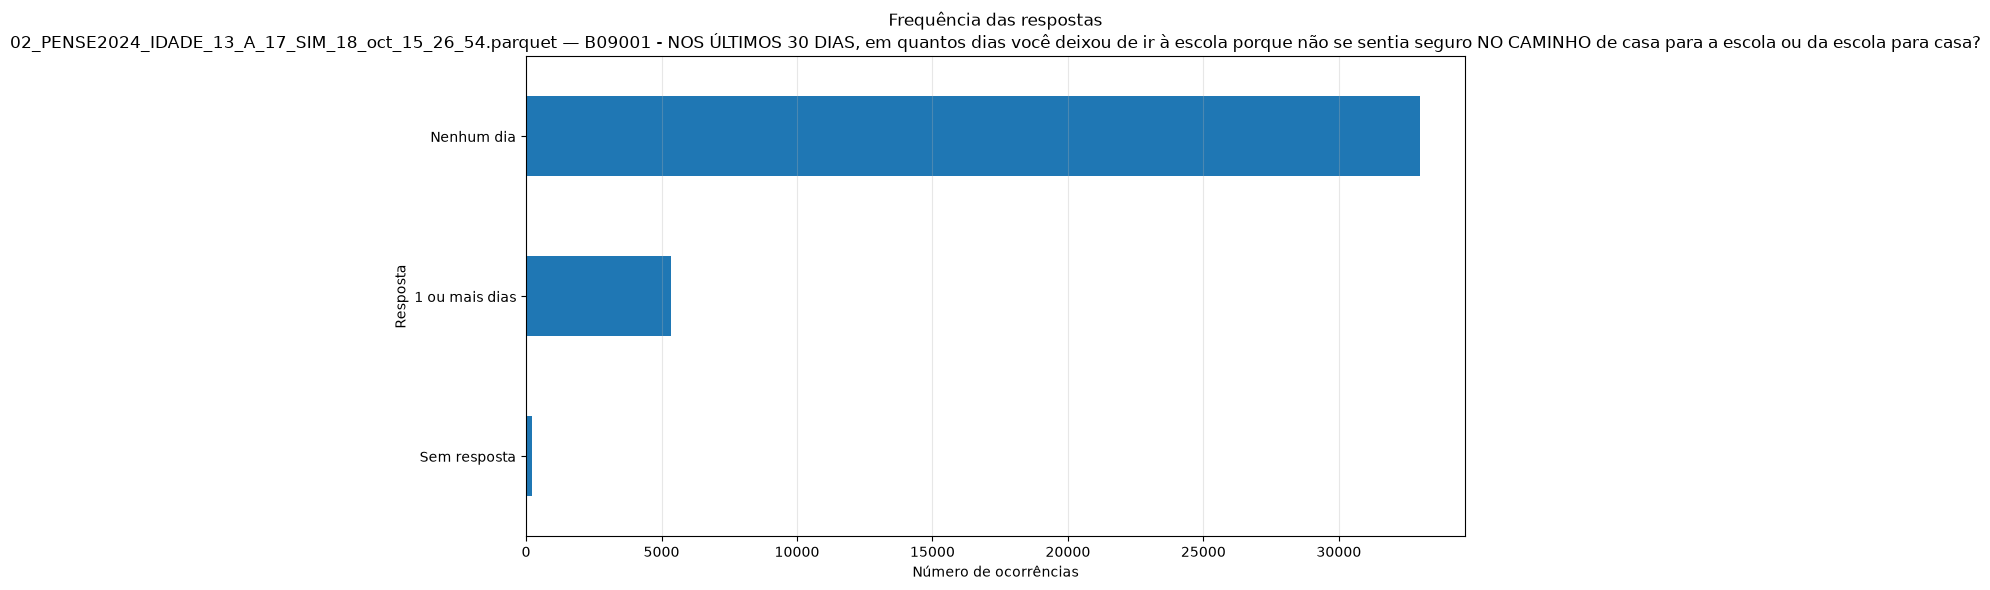


--------------------------------------------------------------------------------
Coluna: B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?

Tabela de frequências:


,frequencia,percentual
Nenhum dia,30702,79.62
1 ou mais dias,7629,19.78
Sem resposta,230,0.6


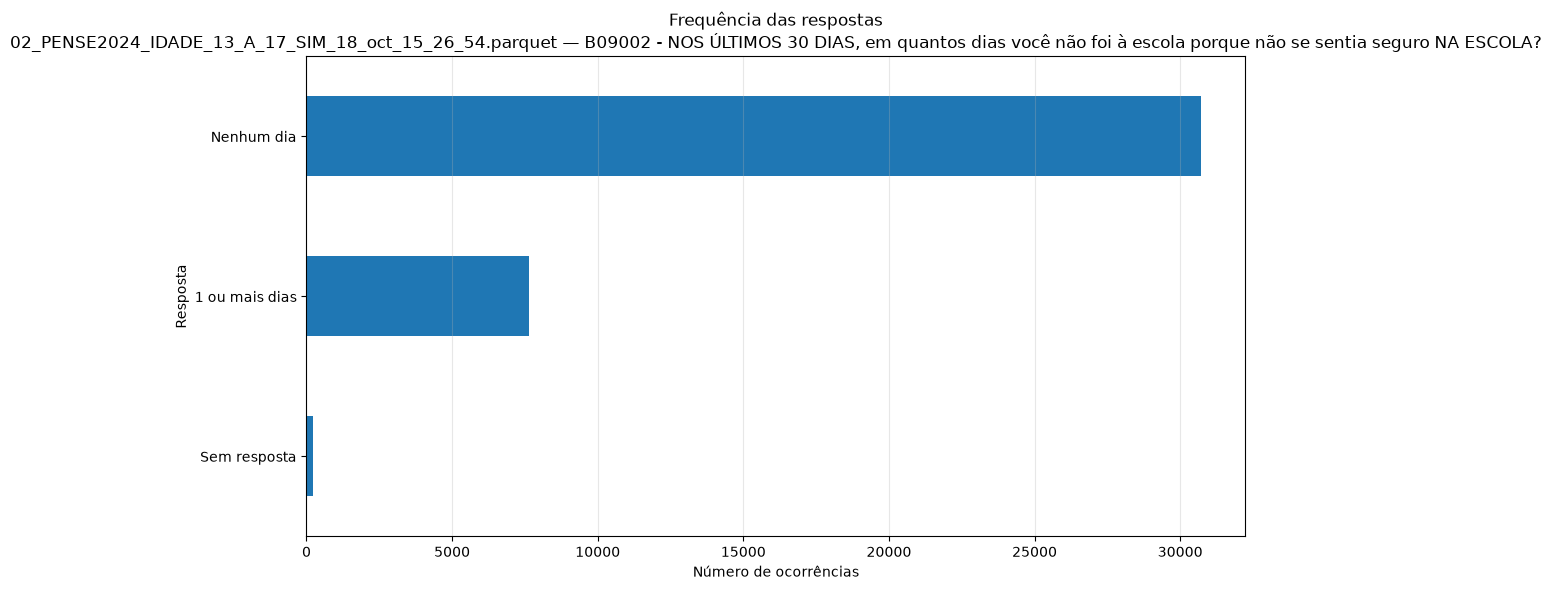


--------------------------------------------------------------------------------
Coluna: B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,26577,68.92
1 ou mais vezes,11715,30.38
Sem resposta,269,0.7


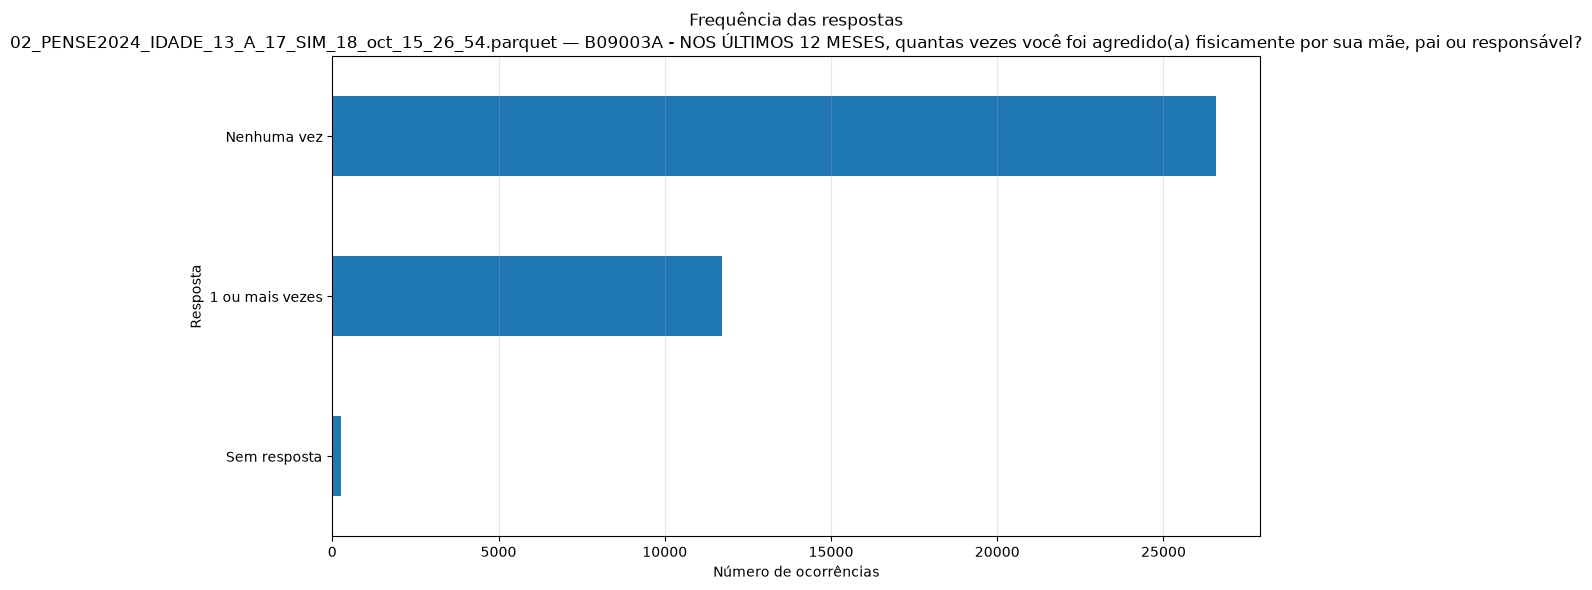


--------------------------------------------------------------------------------
Coluna: B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?

Tabela de frequências:


,frequencia,percentual
Nenhuma vez,30510,79.12
1 ou mais vezes,7784,20.19
Sem resposta,267,0.69


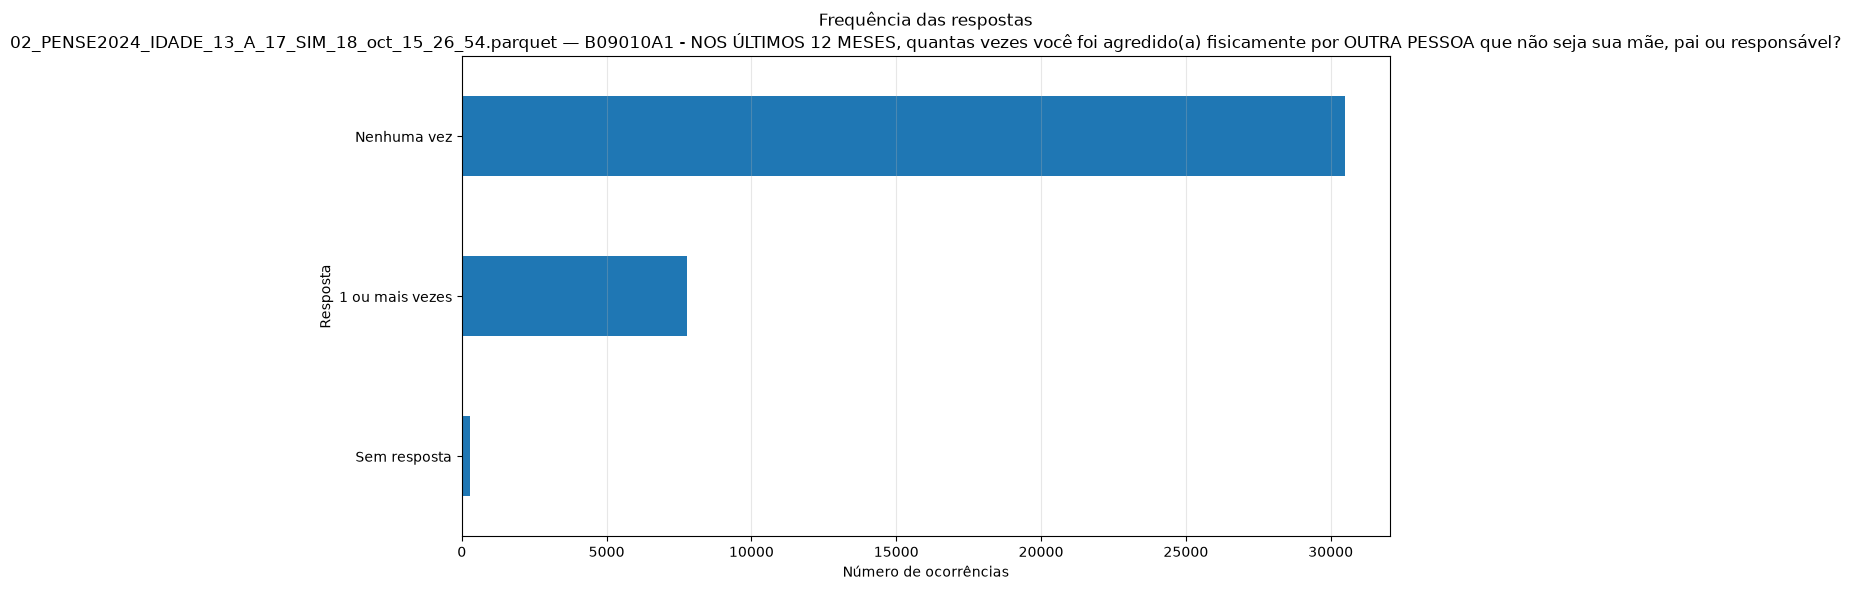


--------------------------------------------------------------------------------
Coluna: B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?

Tabela de frequências:


,frequencia,percentual
Nao,25110,65.12
Sim,13138,34.07
Sem resposta,313,0.81


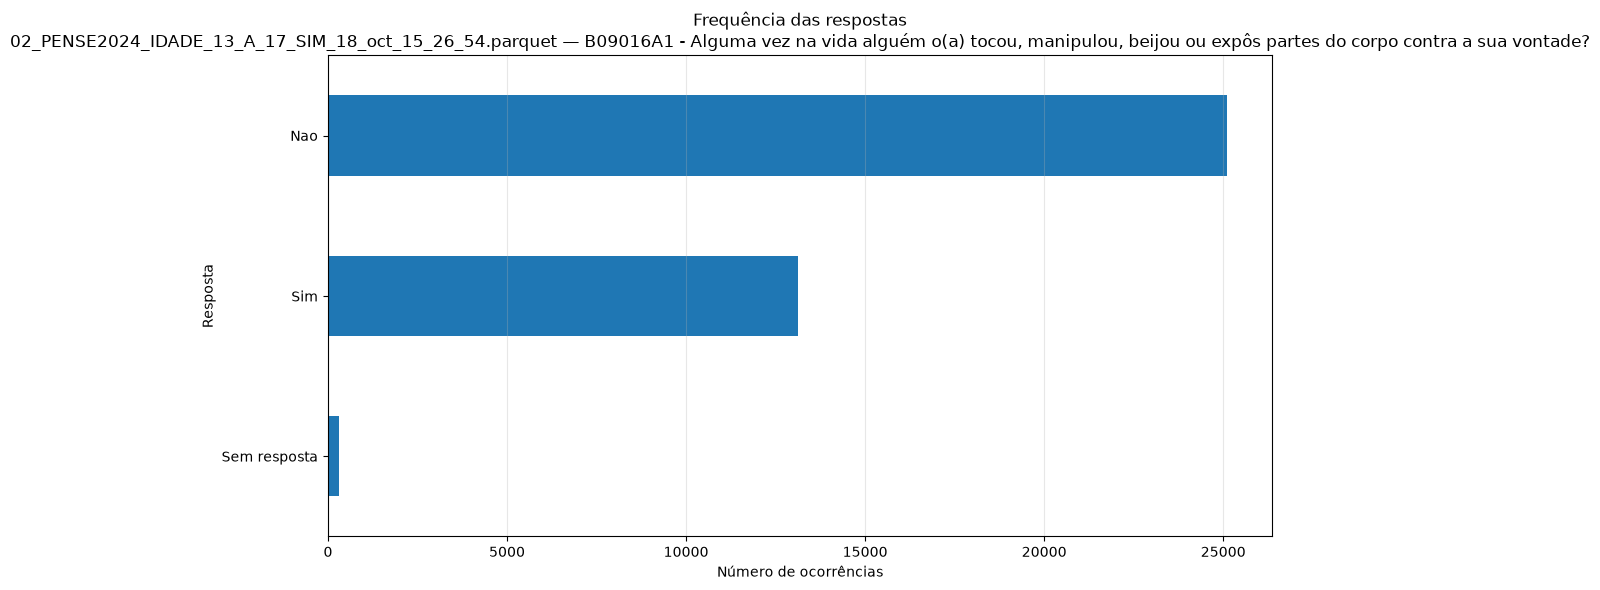


--------------------------------------------------------------------------------
Coluna: B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?

Tabela de frequências:


,frequencia,percentual
Nao,31969,82.91
Sim,6265,16.25
Sem resposta,327,0.85


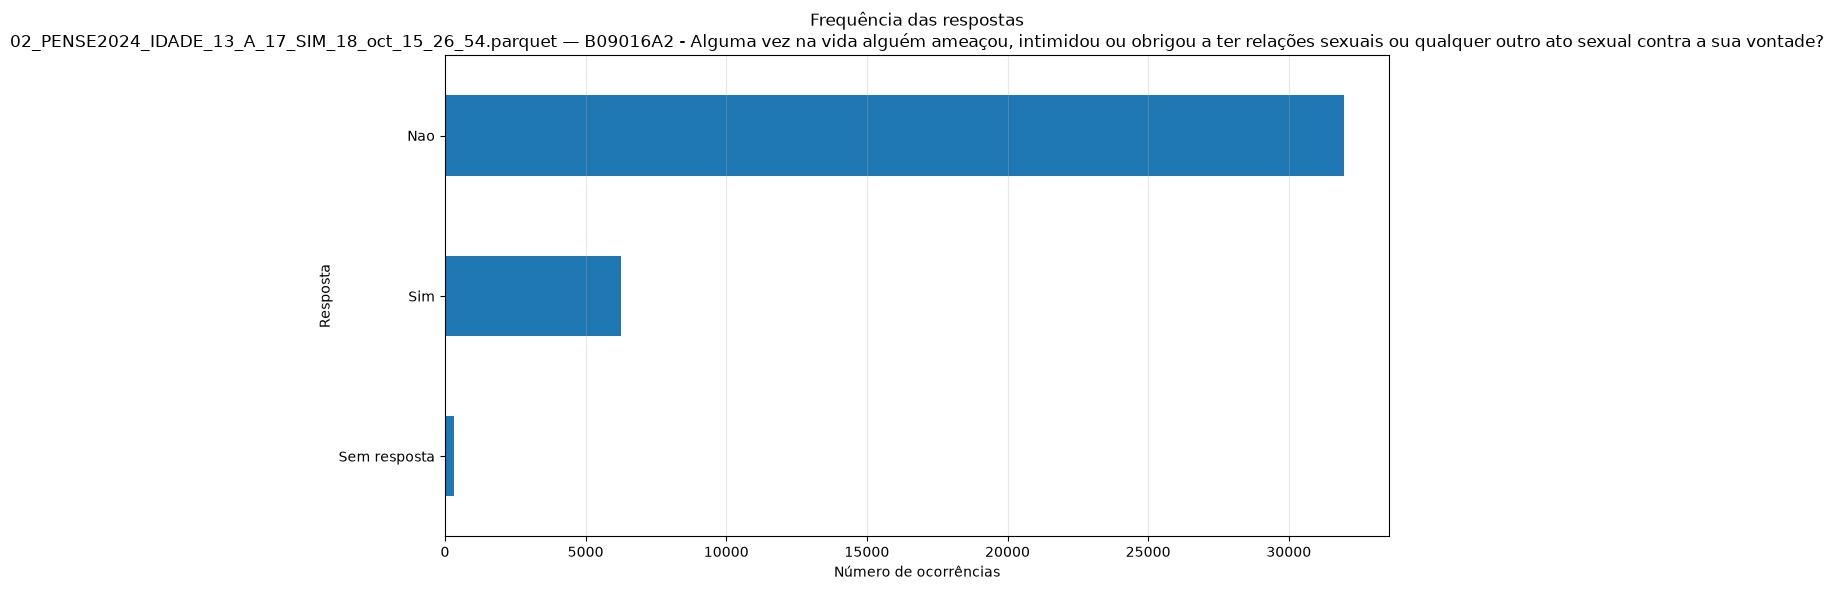


--------------------------------------------------------------------------------
Coluna: E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes

Tabela de frequências:


,frequencia,percentual
Sim,21607,56.03
Nao,16763,43.47
Sem resposta,191,0.5


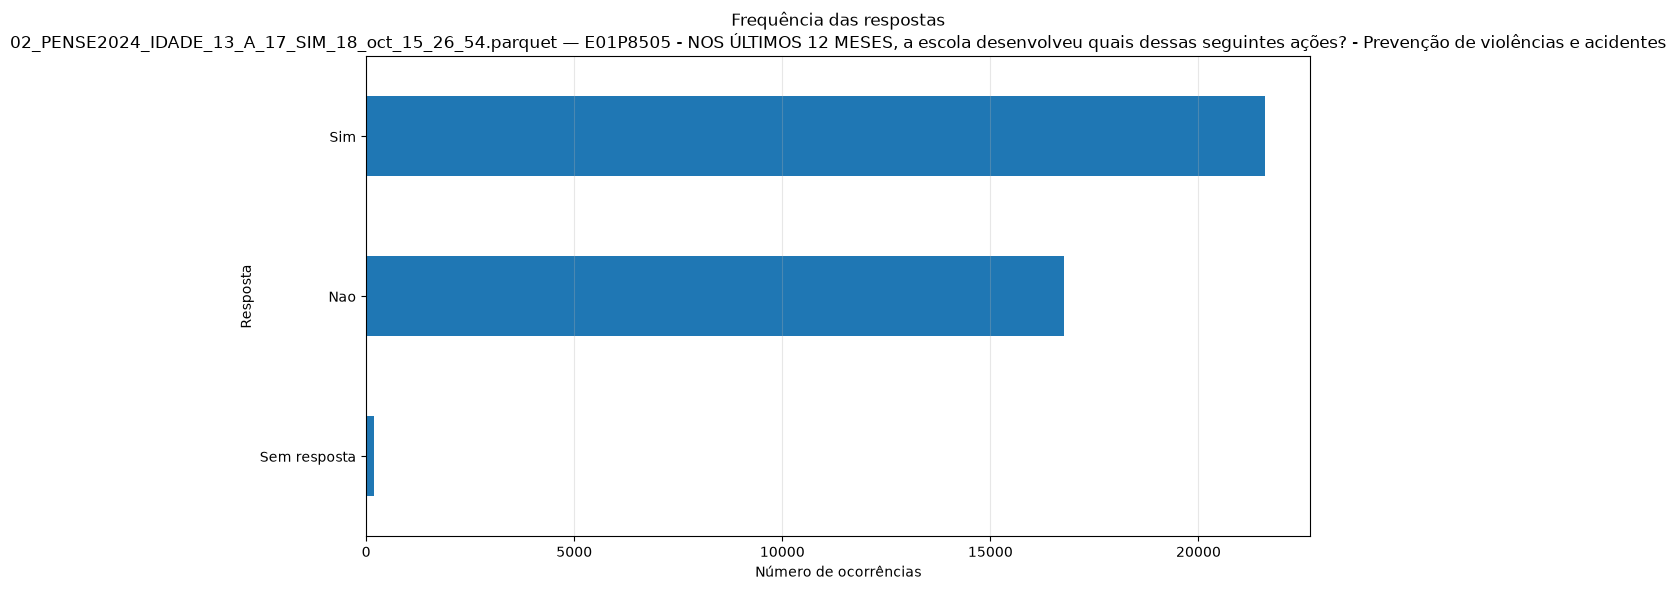


--------------------------------------------------------------------------------
Coluna: E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola

Tabela de frequências:


,frequencia,percentual
Sim,19712,51.12
Nao,18658,48.39
Sem resposta,191,0.5


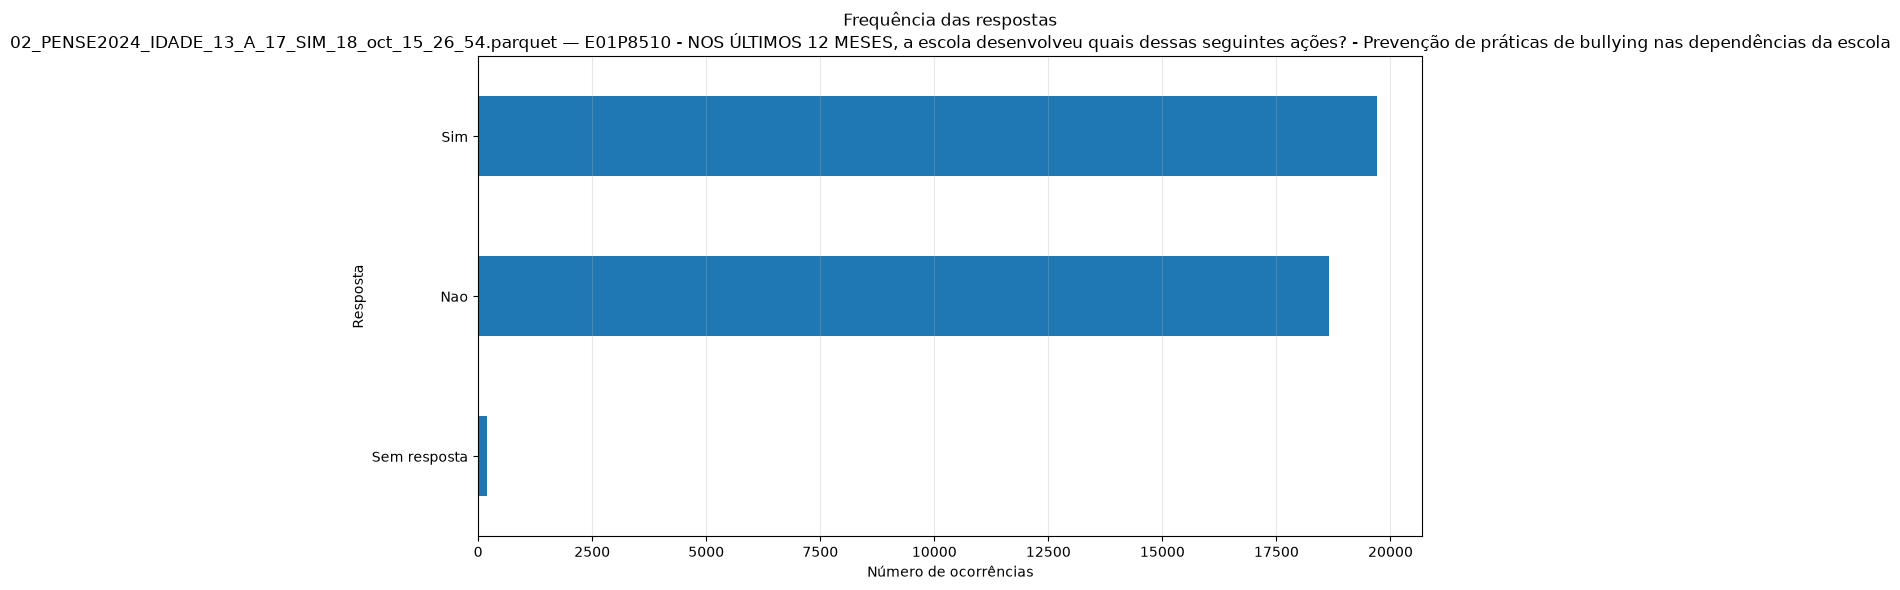


--------------------------------------------------------------------------------
Coluna: E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?

Tabela de frequências:


,frequencia,percentual
Sim,20107,52.14
Sim,11035,28.62
Não,6892,17.87
Sim,483,1.25
Código não mapeado: 0,44,0.11


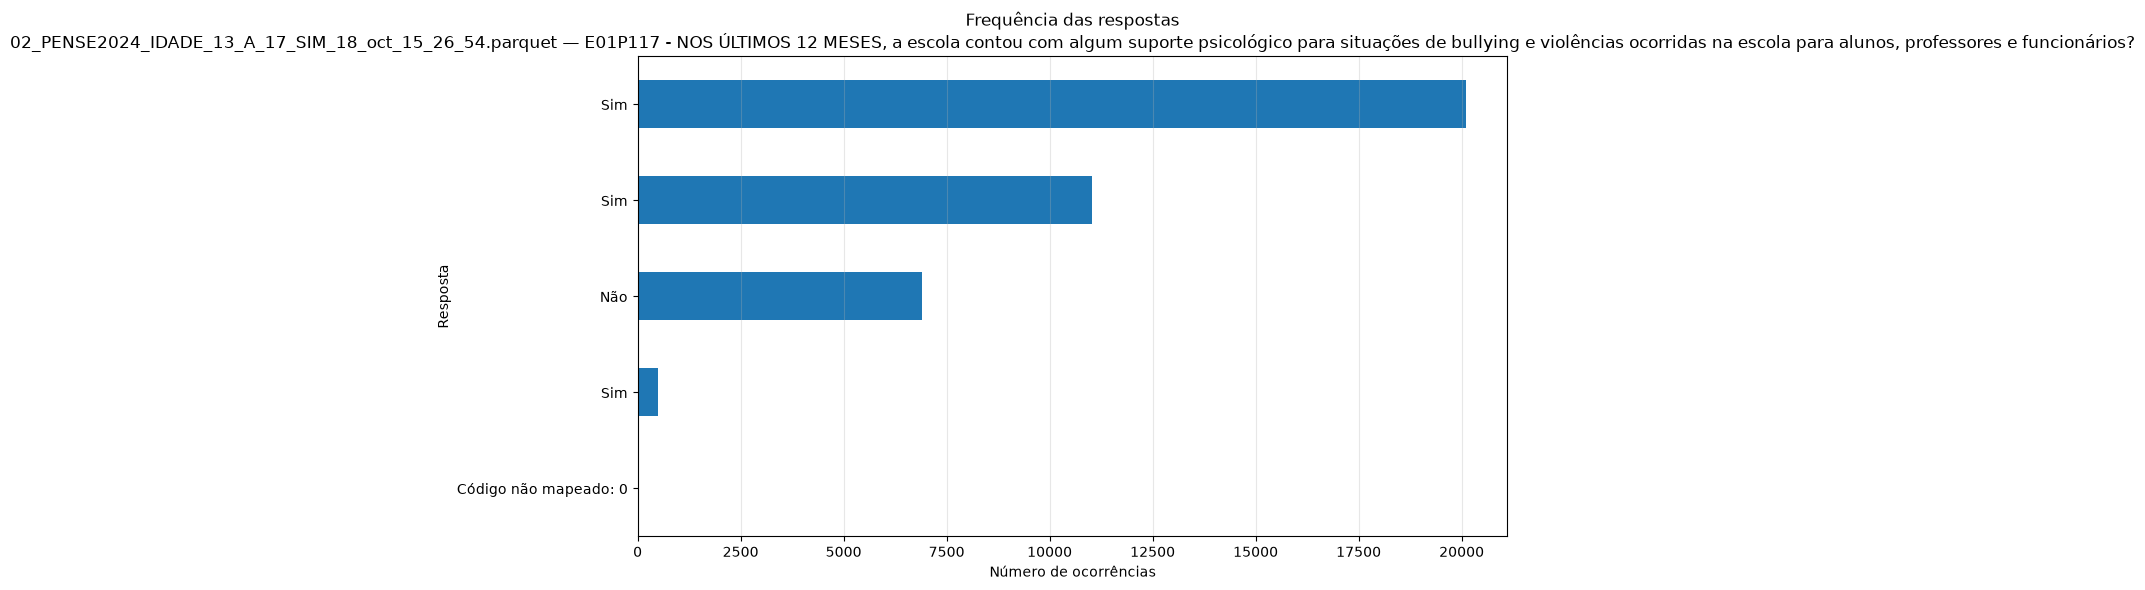


--------------------------------------------------------------------------------
Coluna: E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental

Tabela de frequências:


,frequencia,percentual
Nao,16467,42.7
Sim,14968,38.82
Sem resposta,7126,18.48


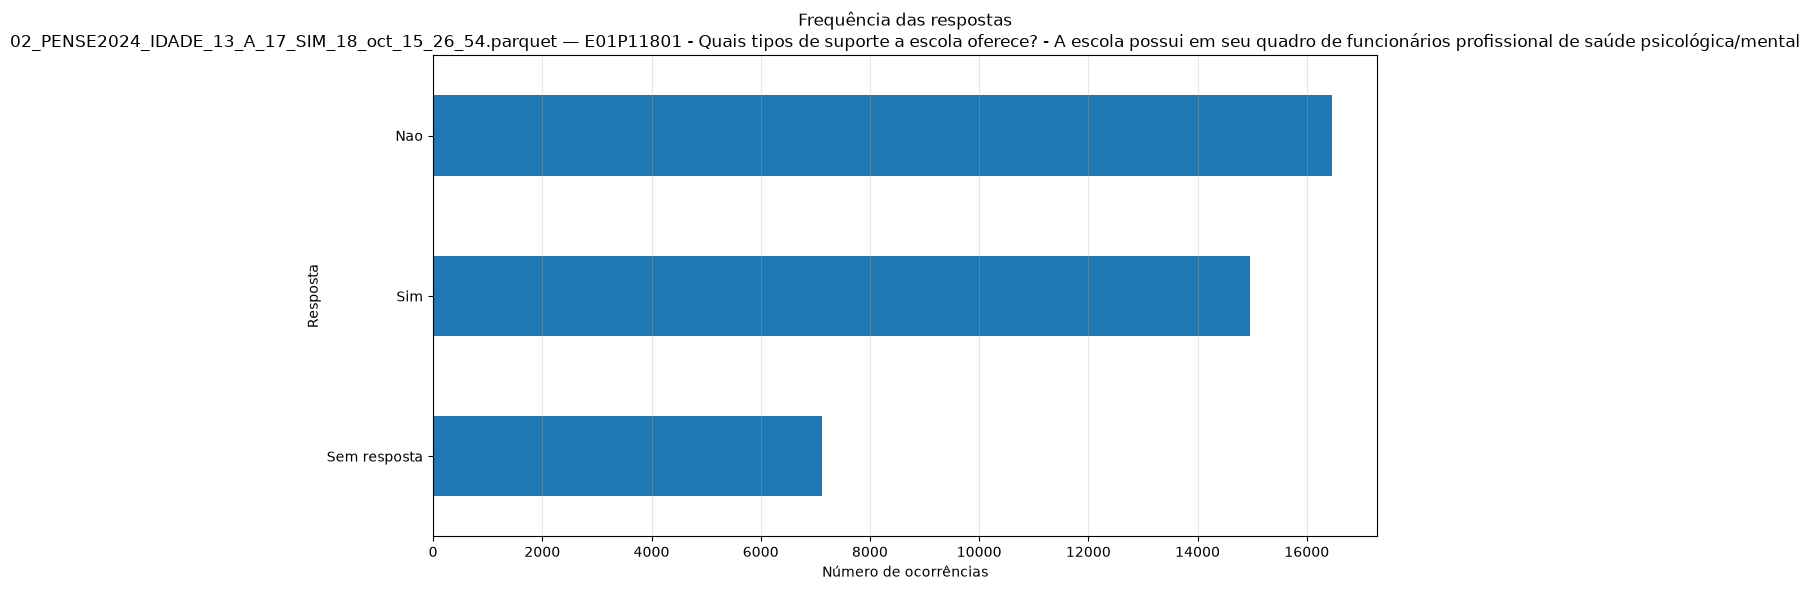


--------------------------------------------------------------------------------
Coluna: E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental

Tabela de frequências:


,frequencia,percentual
Nao,25733,66.73
Sem resposta,7126,18.48
Sim,5702,14.79


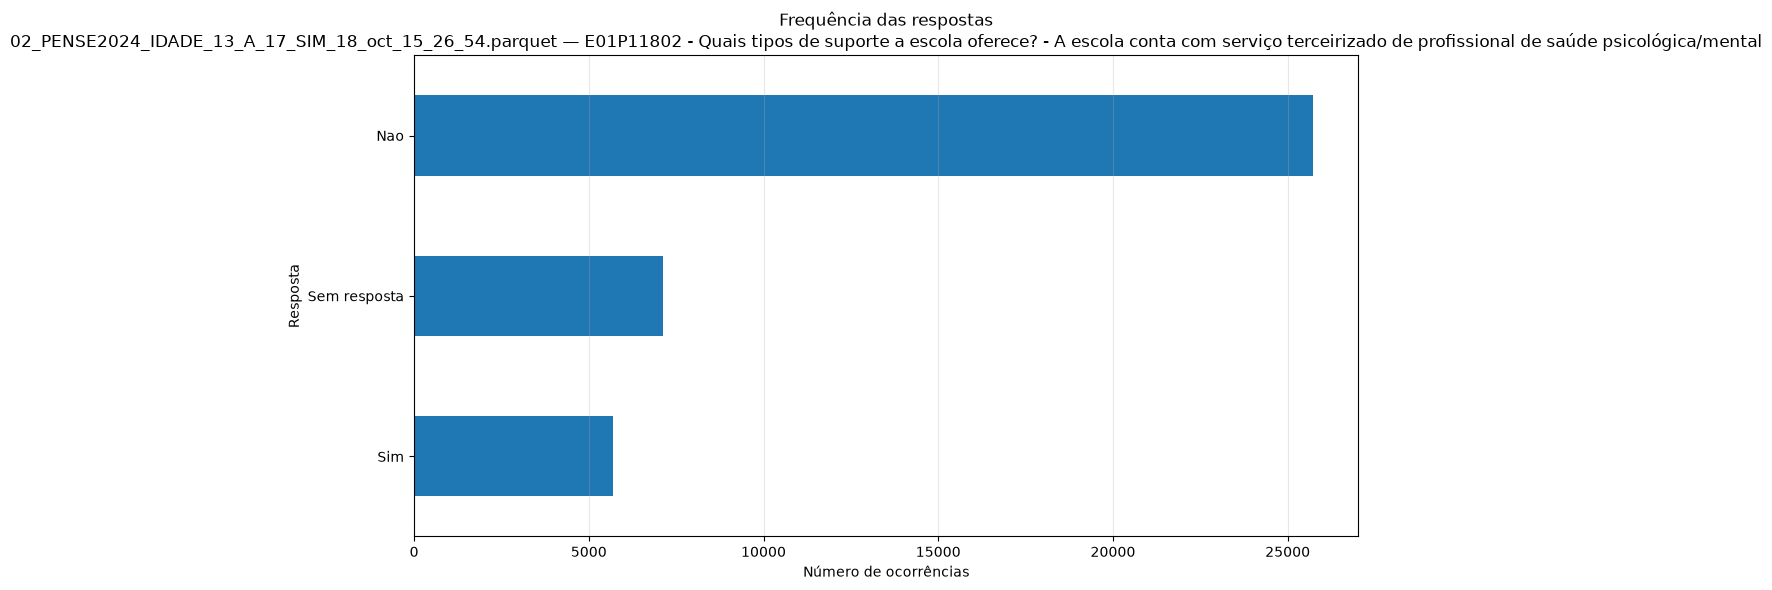


[15] MATRIZ DE CORRELAÇÃO NUMÉRICA


,REGIAO - código de regiões,UF - código UF,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
REGIAO - código de regiões,1.000,0.984,0.030,-0.007,-0.021,-0.164,0.039,0.039,0.158,0.071,...,-0.020,0.004,0.003,-0.013,-0.031,0.024,0.001,0.039,-0.062,0.012
UF - código UF,0.984,1.000,0.032,-0.006,-0.020,-0.162,0.043,0.038,0.152,0.075,...,-0.020,0.004,0.003,-0.013,-0.032,0.015,-0.003,0.036,-0.050,0.016
CAPITAL - indica se é município da capital,0.030,0.032,1.000,-0.014,0.022,-0.063,0.010,-0.022,0.122,0.055,...,0.003,0.013,0.024,0.023,-0.005,0.019,0.017,-0.009,0.050,-0.037
B01001A - Qual é o seu sexo?,-0.007,-0.006,-0.014,1.000,-0.007,-0.002,0.009,-0.043,-0.041,0.017,...,0.012,0.001,-0.110,0.173,0.085,-0.006,-0.005,0.001,-0.008,0.004
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",-0.021,-0.020,0.022,-0.007,1.000,-0.024,-0.056,-0.041,-0.012,-0.018,...,-0.047,-0.100,-0.088,0.063,0.049,-0.007,-0.013,-0.034,0.042,0.003
B01002 - Qual é a sua cor ou raça?,-0.164,-0.162,-0.063,-0.002,-0.024,1.000,-0.047,-0.057,-0.201,-0.071,...,0.020,0.006,0.002,-0.014,0.015,-0.020,-0.010,0.032,-0.070,-0.031
B01006 - Você mora com sua mãe?,0.039,0.043,0.010,0.009,-0.056,-0.047,1.000,0.103,0.088,0.040,...,-0.006,0.024,0.003,-0.035,-0.049,0.005,0.010,-0.014,0.030,0.012
B01007 - Você mora com seu pai?,0.039,0.038,-0.022,-0.043,-0.041,-0.057,0.103,1.000,0.180,0.025,...,-0.046,-0.020,-0.002,-0.064,-0.060,0.016,0.019,-0.020,0.054,0.021
B01015B - Na sua casa tem computador ou notebook?,0.158,0.152,0.122,-0.041,-0.012,-0.201,0.088,0.180,1.000,0.170,...,-0.071,-0.007,0.012,-0.004,-0.063,0.049,0.033,-0.085,0.174,0.063
B01016 - Você tem acesso à internet em sua casa?,0.071,0.075,0.055,0.017,-0.018,-0.071,0.040,0.025,0.170,1.000,...,-0.051,-0.019,-0.036,-0.011,-0.047,0.025,0.019,-0.040,0.062,0.043



INSPEÇÃO CONCLUÍDA: 02_PENSE2024_IDADE_13_A_17_SIM_18_oct_15_26_54.parquet

TODAS AS BASES FORAM INSPECIONADAS.


In [1]:

import pandas as pd
import tkinter as tk
import matplotlib.pyplot as plt
import re

from tkinter import filedialog
from pathlib import Path
from IPython.display import display


# ============================================================
# 1. ARQUIVO EXCEL COM AS REGRAS DE CODIFICAÇÃO
# ============================================================

arquivo_excel = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "01_Colunas_recomendadas_pense_2024_final.xlsx"
)

if not arquivo_excel.exists():
    raise FileNotFoundError(
        f"Arquivo Excel não encontrado: {arquivo_excel}"
    )

regras = pd.read_excel(
    arquivo_excel,
    header=1
)

coluna_codigo = "Código da coluna"
coluna_codificacao = "Nova codificacao"

for coluna in [coluna_codigo, coluna_codificacao]:
    if coluna not in regras.columns:
        raise ValueError(
            f"Coluna '{coluna}' não encontrada no Excel. "
            f"Colunas disponíveis: {list(regras.columns)}"
        )

print("Arquivo Excel carregado com sucesso!")
print(f"Caminho: {arquivo_excel}")
print(f"Número de regras carregadas: {len(regras)}")


# ============================================================
# 2. NORMALIZAR CÓDIGOS
# ============================================================

def normalizar_codigo(valor):

    if pd.isna(valor):
        return None

    texto = str(valor).strip()

    try:
        numero = float(texto)

        if numero.is_integer():
            return str(int(numero))

    except (ValueError, TypeError):
        pass

    return texto


def normalizar_nome_variavel(valor):

    texto = str(valor).strip()

    # Exemplo: B12009 - descrição da variável
    return texto.split(" - ", 1)[0].strip()


# ============================================================
# 3. ENCONTRAR A LEGENDA DE UM CÓDIGO NA NOVA CODIFICACAO
# ============================================================

def encontrar_legenda(codigo, texto_codificacao):

    if pd.isna(texto_codificacao):
        return None

    codigo = normalizar_codigo(codigo)

    if codigo is None:
        return None

    texto = str(texto_codificacao).strip()

    if not texto or texto.lower() == "nan":
        return None

    texto = (
        texto.replace("\r\n", "\n")
        .replace("\r", "\n")
    )

    codigo_regex = re.escape(codigo)

    # Formatos:
    # 1=Sim
    # 2=Não
    # 1 - Sim
    # 2: Não
    # 1) Sim
    padroes_diretos = [
        rf"(?<![\d.-]){codigo_regex}\s*=\s*([^,;\n]+)",
        rf"(?<![\d.-]){codigo_regex}\s*-\s*([^(,;\n]+)",
        rf"(?<![\d.-]){codigo_regex}\s*:\s*([^,;\n]+)",
        rf"(?<![\d.-]){codigo_regex}\s*\)\s*([^,;\n]+)",
    ]

    for padrao in padroes_diretos:

        resultado = re.search(
            padrao,
            texto,
            flags=re.IGNORECASE
        )

        if resultado:

            legenda = resultado.group(1).strip()

            # Retirar eventual indicação de recodificação
            legenda = re.sub(
                r"\s*(?:→|->)\s*-?\d+\s*$",
                "",
                legenda
            ).strip()

            if legenda:
                return legenda

    # Formatos invertidos:
    # Sim (1)
    # Não (2)
    # Sem resposta (0)

    padrao_parenteses = re.compile(
        rf"([^()\n,;]+?)\s*\(\s*{codigo_regex}\s*\)"
    )

    resultados = list(
        padrao_parenteses.finditer(texto)
    )

    if resultados:

        legenda = resultados[-1].group(1).strip()

        # Se houver "1 - Sim (1)", remover o código inicial.
        legenda = re.sub(
            r"^\s*-?\d+\s*[-:=]\s*",
            "",
            legenda
        ).strip()

        if legenda:
            return legenda

    # Formato: [1] Sim
    padrao_colchetes = re.compile(
        rf"\[\s*{codigo_regex}\s*\]\s*([^\n,;]+)"
    )

    resultado = padrao_colchetes.search(texto)

    if resultado:
        legenda = resultado.group(1).strip()

        if legenda:
            return legenda

    return None


# ============================================================
# 4. CONSTRUIR MAPA DE CODIFICAÇÃO POR VARIÁVEL
# ============================================================

mapa_codificacao = {}

for _, linha in regras.iterrows():

    codigo_variavel = normalizar_nome_variavel(
        linha[coluna_codigo]
    ) if pd.notna(linha[coluna_codigo]) else None

    if not codigo_variavel:
        continue

    texto_codificacao = linha[coluna_codificacao]

    mapa_respostas = {}

    if pd.notna(texto_codificacao):

        # Procurar os códigos numéricos presentes na codificação.
        # Cada código será associado à sua legenda.
        texto = str(texto_codificacao)

        codigos_encontrados = re.findall(
            r"(?<![\d.-])-?\d+(?![\d.])",
            texto
        )

        for codigo in dict.fromkeys(codigos_encontrados):

            legenda = encontrar_legenda(
                codigo,
                texto_codificacao
            )

            if legenda is not None:
                mapa_respostas[
                    normalizar_codigo(codigo)
                ] = legenda

    mapa_codificacao[codigo_variavel] = mapa_respostas


# ============================================================
# 5. RECUPERAR OS RÓTULOS DE UMA COLUNA
# ============================================================

def obter_mapa_variavel(nome_coluna):

    codigo_variavel = normalizar_nome_variavel(
        nome_coluna
    )

    return mapa_codificacao.get(
        codigo_variavel,
        {}
    )


# ============================================================
# 6. APLICAR RÓTULOS ÀS FREQUÊNCIAS
# ============================================================

def rotular_frequencias(frequencias, mapa):

    rotulos = []

    for codigo in frequencias.index:

        if pd.isna(codigo):

            rotulo = "Sem resposta (NaN)"

        else:

            codigo_normalizado = normalizar_codigo(
                codigo
            )

            rotulo = mapa.get(
                codigo_normalizado,
                f"Código não mapeado: {codigo}"
            )

        rotulos.append(rotulo)

    resultado = frequencias.copy()

    # Mantém a ordem das frequências e os valores originais.
    # Não altera o DataFrame original.
    resultado.index = rotulos

    return resultado


# ============================================================
# 7. SELECIONAR OS ARQUIVOS PARQUET PELO FINDER
# ============================================================

root = tk.Tk()
root.withdraw()

arquivos = filedialog.askopenfilenames(
    title="Selecione os arquivos Parquet para comparação",
    filetypes=[("Arquivos Parquet", "*.parquet")]
)

root.destroy()

if not arquivos:
    raise SystemExit("Nenhum arquivo selecionado.")


# ============================================================
# 8. CALCULAR ESTATÍSTICAS NUMÉRICAS
# ============================================================

estatisticas = {}

for arquivo in arquivos:

    caminho = Path(arquivo)

    print(f"\nCalculando estatísticas: {caminho.name}")

    df = pd.read_parquet(caminho)

    df_numerico = df.select_dtypes(
        include="number"
    )

    if not df_numerico.empty:

        resumo = df_numerico.describe().T[
            ["count", "mean", "std"]
        ]

    else:

        resumo = pd.DataFrame(
            columns=["count", "mean", "std"]
        )

    estatisticas[caminho.name] = resumo

    del df, df_numerico


# ============================================================
# 9. COMPARAÇÃO DAS BASES
# ============================================================

comparacao = pd.concat(
    estatisticas,
    axis=1
)

print("\n" + "=" * 100)
print("COMPARAÇÃO DAS ESTATÍSTICAS NUMÉRICAS")
print("=" * 100)

display(comparacao.round(3))


# ============================================================
# 10. INSPECIONAR INDIVIDUALMENTE CADA BASE
# ============================================================

for arquivo in arquivos:

    caminho = Path(arquivo)

    print("\n\n" + "#" * 100)
    print(f"INSPEÇÃO DA BASE: {caminho.name}")
    print("#" * 100)

    df = pd.read_parquet(caminho)

    # --------------------------------------------------------
    # 10.1. DIMENSÕES E MEMÓRIA
    # --------------------------------------------------------

    print("\n[1] DIMENSÕES DA BASE")

    print(f"Número de linhas: {df.shape[0]:,}")
    print(f"Número de colunas: {df.shape[1]:,}")
    print(f"Total de células: {df.size:,}")

    memoria_mb = (
        df.memory_usage(deep=True).sum() / 1024**2
    )

    print(f"Memória utilizada: {memoria_mb:.2f} MB")

    # --------------------------------------------------------
    # 10.2. DATAFRAME COMPLETO
    # --------------------------------------------------------

    print("\n[2] DATAFRAME COMPLETO")
    display(df)

    # --------------------------------------------------------
    # 10.3. PRIMEIRAS E ÚLTIMAS LINHAS
    # --------------------------------------------------------

    print("\n[3] PRIMEIRAS 5 LINHAS")
    display(df.head())

    print("\n[4] ÚLTIMAS 5 LINHAS")
    display(df.tail())

    # --------------------------------------------------------
    # 10.4. DF.INFO()
    # --------------------------------------------------------

    print("\n[5] INFORMAÇÕES GERAIS — DF.INFO()")

    df.info(
        show_counts=True,
        memory_usage="deep"
    )

    # --------------------------------------------------------
    # 10.5. TIPOS DE DADOS
    # --------------------------------------------------------

    print("\n[6] TIPOS DE DADOS")

    display(
        df.dtypes.rename("dtype").to_frame()
    )

    print("\nQuantidade de colunas por tipo:")

    display(
        df.dtypes.astype(str)
        .value_counts()
        .to_frame("quantidade")
    )

    # --------------------------------------------------------
    # 10.6. DESCRIBE NUMÉRICO
    # --------------------------------------------------------

    print("\n[7] DF.DESCRIBE() — COLUNAS NUMÉRICAS")
    display(df.describe().T)

    # --------------------------------------------------------
    # 10.7. DESCRIBE DE TODAS AS COLUNAS
    # --------------------------------------------------------

    print("\n[8] DF.DESCRIBE(INCLUDE='ALL')")
    display(df.describe(include="all").T)

    # --------------------------------------------------------
    # 10.8. VALORES AUSENTES
    # --------------------------------------------------------

    print("\n[9] VALORES AUSENTES")

    ausentes = pd.DataFrame({
        "valores_ausentes": df.isna().sum(),
        "percentual_ausente": df.isna().mean() * 100
    })

    ausentes = ausentes.sort_values(
        "percentual_ausente",
        ascending=False
    )

    display(ausentes.round(3))

    print(
        f"Total de células ausentes: "
        f"{df.isna().sum().sum():,}"
    )

    # --------------------------------------------------------
    # 10.9. CARDINALIDADE
    # --------------------------------------------------------

    print("\n[10] VALORES ÚNICOS POR COLUNA")

    cardinalidade = pd.DataFrame({
        "valores_unicos": df.nunique(dropna=True),
        "valores_unicos_incluindo_ausentes":
            df.nunique(dropna=False),
        "percentual_unico": (
            df.nunique(dropna=True) / len(df) * 100
            if len(df) > 0 else 0
        )
    })

    display(cardinalidade.round(3))

    # --------------------------------------------------------
    # 10.10. LINHAS DUPLICADAS
    # --------------------------------------------------------

    print("\n[11] LINHAS DUPLICADAS")

    duplicadas = df.duplicated().sum()

    print(f"Linhas duplicadas: {duplicadas:,}")

    if len(df) > 0:
        print(
            f"Percentual de duplicatas: "
            f"{duplicadas / len(df) * 100:.3f}%"
        )
    else:
        print("Percentual de duplicatas: não aplicável.")

    # --------------------------------------------------------
    # 10.11. COLUNAS CONSTANTES
    # --------------------------------------------------------

    print("\n[12] COLUNAS CONSTANTES")

    constantes = [
        coluna
        for coluna in df.columns
        if df[coluna].nunique(dropna=False) <= 1
    ]

    if constantes:
        print(constantes)
    else:
        print("Nenhuma coluna constante identificada.")

    # --------------------------------------------------------
    # 10.12. FREQUÊNCIAS CATEGÓRICAS + GRÁFICOS
    # --------------------------------------------------------

    print("\n[13] DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS")

    colunas_categoricas = df.select_dtypes(
        include=["object", "category", "string", "bool"]
    ).columns

    for coluna in colunas_categoricas:

        print("\n" + "-" * 80)
        print(f"Coluna: {coluna}")

        mapa = obter_mapa_variavel(coluna)

        frequencias = df[coluna].value_counts(
            dropna=False
        )

        frequencias_rotuladas = rotular_frequencias(
            frequencias,
            mapa
        )

        tabela = (
            frequencias_rotuladas.head(20)
            .to_frame("frequencia")
        )

        tabela["percentual"] = (
            tabela["frequencia"] / len(df) * 100
            if len(df) > 0 else 0
        )

        print("\nTabela de frequências:")

        display(tabela.round(2))

        dados_grafico = (
            frequencias_rotuladas
            .nlargest(20)
            .sort_values()
        )

        plt.figure(figsize=(11, 6))

        dados_grafico.plot(kind="barh")

        plt.title(
            f"Frequência das respostas\n"
            f"{caminho.name} — {coluna}"
        )

        plt.xlabel("Número de ocorrências")
        plt.ylabel("Resposta")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

    # --------------------------------------------------------
    # 10.13. FREQUÊNCIAS NUMÉRICAS + GRÁFICOS
    # COM RÓTULOS DO EXCEL
    # --------------------------------------------------------

    print("\n[14] DISTRIBUIÇÃO DAS VARIÁVEIS NUMÉRICAS")

    colunas_numericas = df.select_dtypes(
        include="number"
    ).columns

    for coluna in colunas_numericas:

        print("\n" + "-" * 80)
        print(f"Coluna: {coluna}")

        mapa = obter_mapa_variavel(coluna)

        frequencias = df[coluna].value_counts(
            dropna=False
        )

        frequencias_rotuladas = rotular_frequencias(
            frequencias,
            mapa
        )

        # Tabela com até 30 respostas mais frequentes
        tabela = (
            frequencias_rotuladas.head(30)
            .to_frame("frequencia")
        )

        tabela["percentual"] = (
            tabela["frequencia"] / len(df) * 100
            if len(df) > 0 else 0
        )

        print("\nTabela de frequências:")

        display(tabela.round(2))

        # Gráfico dos 20 valores mais frequentes
        dados_grafico = (
            frequencias_rotuladas
            .nlargest(20)
            .sort_values()
        )

        plt.figure(figsize=(11, 6))

        dados_grafico.plot(kind="barh")

        plt.title(
            f"Frequência das respostas\n"
            f"{caminho.name} — {coluna}"
        )

        plt.xlabel("Número de ocorrências")
        plt.ylabel("Resposta")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

    # --------------------------------------------------------
    # 10.14. MATRIZ DE CORRELAÇÃO
    # --------------------------------------------------------

    print("\n[15] MATRIZ DE CORRELAÇÃO NUMÉRICA")

    df_numerico = df.select_dtypes(
        include="number"
    )

    if df_numerico.shape[1] >= 2:
        display(df_numerico.corr().round(3))
    else:
        print(
            "Menos de duas colunas numéricas "
            "para calcular correlações."
        )

    # --------------------------------------------------------
    # 10.15. ENCERRAMENTO
    # --------------------------------------------------------

    print("\n" + "=" * 100)
    print(f"INSPEÇÃO CONCLUÍDA: {caminho.name}")
    print("=" * 100)

    del df, df_numerico


# ============================================================
# 11. FINALIZAÇÃO
# ============================================================

print("\nTODAS AS BASES FORAM INSPECIONADAS.")
